# **Ant Life-Cycle Simulation and Machine Learning**
***
![https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/Schematics/Front_pic.jpg](https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/Schematics/Front_pic.jpg)
***

**Predicting when a rare, *de novo* allele can persist in a social-insect structured metapopulation**

## **Overview**

Ant colonies contain two castes, **queens** and **workers**, that share the same genome but are selected towards different phenotypic optima. A newly arisen allele can therefore be beneficial in one caste and costly in the other. Whether such an allele is eventually **lost**, **fixed**, or **maintained as a polymorphism** depends on two groups of factors: the *ecology* of the colonies (survival, extinction, migration, number of queens and of mating males) and the *genetics* of the allele (its effect and its dominance in each caste).

Answering this question directly requires an individual-based life-cycle simulation, and that is expensive: every combination of parameters is run for 100 replicates of 10,000 generations. This notebook uses **machine learning as a tool to understand the simulation**. We proceed in four steps:

1. **Describe** the simulation and the dataset it produced.
2. **Explore and prepare** the *complete* dataset for a binary classification task: *is polymorphism maintained or not?* We also analyse how well the simulated parameter sets cover the feature space and how noisy the label is.
3. **Train and compare** five classifiers of increasing flexibility: logistic regression, decision tree, random forest, XGBoost and a multilayer perceptron. Every model is tuned by 5-fold cross-validation and evaluated with three metrics, accuracy, PR AUC and ROC AUC.
4. **Interpret** the best model with simple SHAP, partial dependence and ICE plots, model-free checks directly on the simulated data, and a distilled rule-based surrogate. We use them to test a specific hypothesis about dominance in queens and workers. Because distillation reproduces the black box poorly, we finish with readable alternatives: better student models, a glass-box Explainable Boosting Machine and an interaction screen that does not rely on SHAP interaction values.

## **Contents**

1. Setup
2. The Simulation Model and the Dataset
3. Data Loading and Cleaning
4. Exploratory Data Analysis
5. Data Preparation
6. Data Analysis: Coverage of the Feature Space and Label Noise
7. Modelling Strategy
8. Logistic Regression
9. Decision Tree
10. Random Forest
11. XGBoost
12. Multilayer Perceptron
13. Model Comparison and Diagnostics
14. Interpreting XGBoost
15. Conclusions, Limitations and Next Steps

> **Reading guide.** Blocks labelled **Takeaway** summarise what the preceding result tells us. Blocks labelled **Note** give practical or methodological context. The numbered result tables (Table 1: hyperparameters, Table 2: metrics) are built in Sections 13.1 and 13.2.

## **1. Setup**

### **1.1 Libraries, Custom Script and Random Seed**

The cell below imports every library used in the notebook, grouped by purpose, and loads the custom script `dataset_generator_simple_model.py`. That script generates the simulation data by drawing each parameter at random within its biological range (see Section 2).

This notebook is both usable in collab and in local. Finally, a fixed **random seed** (`random_seed = 5`) makes the train/test split, the cross-validation folds and every hyperparameter search reproducible, and `POLYMORPH_THRESHOLD` defines what we call a *polymorphic* parameter set (see Section 4.3).


> **Note.** The notebook works directly from the data files listed in `DATASET_FILES` (Section 3). If a file sits in the same folder as the notebook it is used, otherwise it is downloaded from the project's GitHub repository. The generator scripts are only needed to *produce* new data (optional cell at the start of Section 3, `GENERATE_DATA = False`).
>
> **Run configuration.** `QUICK_RUN = True` shrinks every expensive step (rows, search sizes, bootstrap, EBM, interaction screen) so that the whole notebook runs in minutes: use it to check that everything works, then set it back to `False` for the real run. All the budgets are collected in the `BUDGET` dictionary of the cell below.

In [89]:
### --- Libraries for General Use --- ###
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

### --- Libraries for Data Splitting, Cross-Validation and Hyperparameter Tuning --- ###
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_score, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

### --- Libraries for the Models --- ###
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
try:
    from xgboost import XGBClassifier
except ImportError:                      # xgboost is not pre-installed on Google Colab.
    %pip install -q xgboost
    from xgboost import XGBClassifier
try:
    from interpret.glassbox import ExplainableBoostingClassifier
except ImportError:                      # interpret is not pre-installed on Google Colab.
    %pip install -q interpret
    from interpret.glassbox import ExplainableBoostingClassifier

### --- Libraries for Evaluation and Model Inspection --- ###
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             log_loss, brier_score_loss, r2_score, average_precision_score,
                             precision_recall_curve, precision_score, recall_score, f1_score,
                             matthews_corrcoef, balanced_accuracy_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
try:
    import shap
except ImportError:                      # shap is not pre-installed on Google Colab.
    %pip install -q shap
    import shap

### --- Libraries for Statistics and Sampling Designs --- ###
from scipy import stats
from scipy.stats import qmc
from scipy.spatial import cKDTree

### --- Random Seed and Definition of the Polymorphic Class --- ###
random_seed = 5
POLYMORPH_THRESHOLD = 0.0   # A parameter set is polymorphic if frac_polymorphic > this value.

### --- Run Configuration: One Switch and One Dictionary for Every Budget --- ###
QUICK_RUN = False   # True: tiny budgets, to check in minutes that the whole notebook runs. False: the real run.

BUDGET = {
    'max_rows':         6_000 if QUICK_RUN else None,      # Rows kept from the data set (None = all of them).
    'search_rows':      4_000 if QUICK_RUN else 40_000,    # Training rows used by the hyperparameter searches (Section 7.1).
    'n_iter':           ({'Decision Tree': 4, 'Random Forest': 3, 'XGBoost': 3, 'Multilayer Perceptron': 3} if QUICK_RUN
                         else {'Decision Tree': 60, 'Random Forest': 40, 'XGBoost': 40, 'Multilayer Perceptron': 50}),
    'n_boot':           50 if QUICK_RUN else 1000,         # Bootstrap resamples of the test set (Sections 13.4 and 14.9).
    'perm_repeats_mlp': 2 if QUICK_RUN else 10,            # Shuffles per feature, permutation importance of the MLP (Section 12.3).
    'perm_repeats_xgb': 2 if QUICK_RUN else 5,             # Same for XGBoost (Section 14.2).
    'lc_sizes':         np.linspace(0.3, 1.0, 3) if QUICK_RUN else np.linspace(0.1, 1.0, 6),   # Learning curve (Section 13.8).
    'n_syn':            20_000 if QUICK_RUN else 200_000,  # Synthetic parameter sets labelled by the teacher (Section 14.7).
    'ebm_interactions': [0, 5] if QUICK_RUN else [0, 5, 10, 20],   # Numbers of pair terms tried by the EBM (Section 14.9).
    'ebm_outer_bags':   4 if QUICK_RUN else 8,             # Bagged models inside the EBM (8 is the default of the library).
    'screen_rows':      3_000 if QUICK_RUN else 40_000,    # Rows of the interaction screen (Section 14.10).
    'screen_folds':     2 if QUICK_RUN else 5,
    'n_curve_pairs':    3 if QUICK_RUN else 12,            # Pairs added one by one in the cumulative curve (Section 14.10).
}

### **1.2 Helper Plotting Functions**

The same figures are needed several times (once per model, for instance), so they are wrapped in small helper functions. Defining them once keeps the rest of the notebook short and the figures consistent.

| Function | What it displays |
|---|---|
| `barplot_polymorphic_or_not` | Number and fraction of non polymorphic versus polymorphic samples. |
| `plot_feature_distr` | Distribution of every feature, drawn separately for polymorphic and non polymorphic samples. |
| `plot_feature_pairwise_corr` | Correlation matrix of all the features and the response variable. |
| `plot_confusion_matrix` | Confusion matrix of a fitted model on a chosen data set, with TN, FP, FN and TP as percentages. |
| `plot_roc` | ROC curve and area under the curve (AUC) of a fitted model on a chosen data set. |
| `feat_imp_plot` | Top 10 impurity-based feature importances of a fitted tree ensemble. |
| `wilson_ci` | 95% Wilson confidence interval of an observed proportion (used for observed polymorphism rates). |
| `plot_pr` | Plot the precision call curve and its AUC for a fitted model on a chosen dataset. |

The helpers used for tuning and for the result tables are defined in Section 7.1, and those used for partial dependence in Section 14.4.

In [90]:
### --- Polymorphic Versus Non Polymorphic Barplot Helper --- ###
def barplot_polymorphic_or_not(df, polymorph_threshold = 0.0):
    """Bar plot of the non polymorphic versus polymorphic share of the samples."""
    polymorph_samples = (df['frac_polymorphic'] > polymorph_threshold)
    n_poly = int(polymorph_samples.sum())
    n_non = int((~polymorph_samples).sum())

    fig, ax = plt.subplots()
    bars = ax.bar([0, 1], [n_non / len(df), n_poly / len(df)], color = 'moccasin')
    ax.bar_label(bars, labels = [f'n = {n_non}', f'n = {n_poly}'], padding = 3)
    ax.set_xticks(ticks = [0, 1], labels = ['Non Polymorphic', 'Polymorphic'])
    ax.set_ylabel('Fraction of Samples')
    ax.set_ylim(0, 1.05)
    ax.set_title('Non-Polymorphic vs Polymorphic Fraction', fontweight = 'bold', pad = 15)
    plt.show()

### --- Features Distribution Plotting Helper --- ###
def plot_feature_distr(df, params, polymorph_threshold = 0.0, ncols = 4):
    """Histogram of every feature, drawn separately for polymorphic and non polymorphic samples."""
    polymorph_samples = (df['frac_polymorphic'] > polymorph_threshold)

    nrows = int(np.ceil(len(params) / ncols))
    fig, axs = plt.subplots(nrows = nrows, ncols = ncols, figsize = (4 * ncols, 3.6 * nrows), squeeze = False)
    axs = axs.ravel()
    for ax, col_name in zip(axs, params):
        # Counts (Nq, Nm) get one bin per integer value, continuous features get 20 bins.
        if col_name in ('Nq', 'Nm'):
            bins = np.arange(df[col_name].min() - 0.5, df[col_name].max() + 1.5)
        else:
            bins = 20
        ax.hist(df.loc[polymorph_samples, col_name], bins = bins, alpha = 0.5, label = 'Polymorphic', density = True)
        ax.hist(df.loc[~polymorph_samples, col_name], bins = bins, alpha = 0.5, label = 'Non Polymorphic', density = True)
        ax.set_title(col_name, fontweight = 'bold')
        ax.set_xlabel('Value')
        ax.set_ylabel('Density')
    for ax in axs[len(params):]:
        ax.set_visible(False)
    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc = 'upper center', ncol = 2, fontsize = 14, bbox_to_anchor = (0.5, 1.03))
    plt.tight_layout(rect = [0, 0, 1, 0.97])
    plt.show()

### --- Correlation Matrix Plotting Helper --- ###
def plot_feature_pairwise_corr(df):
    """Correlation matrix of all the columns of df (features and response variable)."""
    corr_matrix = df.corr()

    fig, ax = plt.subplots(figsize = (10, 8))
    cax = ax.matshow(corr_matrix, cmap = 'PuOr', vmin = -1, vmax = 1)
    ax.set_xticks(range(len(corr_matrix.columns)))
    ax.set_yticks(range(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns, rotation = 90)
    ax.set_yticklabels(corr_matrix.columns)
    fig.colorbar(cax)
    plt.show()

### --- Confusion Matrix Plotting Helper --- ###
def plot_confusion_matrix(model, X_set, y_set, type_of_set = "Test", threshold = 0.5):
    """Confusion matrix of a fitted model at a given probability threshold."""
    pred = (model.predict_proba(X_set)[:, 1] >= threshold).astype(int)
    cm = confusion_matrix(y_set, pred, labels = [0, 1])
    cm_percent = cm / cm.sum() * 100
    cm_row = cm / cm.sum(axis = 1, keepdims = True) * 100

    names = [['True Negative (TN)', 'False Positive (FP)'], ['False Negative (FN)', 'True Positive (TP)']]
    annot_labels = np.array([[f'{names[i][j]}\n{cm[i, j]:,}  ({cm_percent[i, j]:.2f}% of all)' for j in range(2)] for i in range(2)])

    plt.figure(figsize = (8, 6))
    sns.heatmap(cm_row, annot = annot_labels, fmt = '', cmap = 'Oranges', cbar = True,
                linewidths = 2, annot_kws = {'size': 11, 'weight': 'bold'}, vmin = 0, vmax = 100,
                cbar_kws = {'label': '% of the true class'})
    plt.title(f'Confusion Matrix of the {type_of_set} Set (threshold = {threshold:.3f})', fontsize = 14, fontweight = 'bold', pad = 15)
    plt.xlabel('Predicted Label', fontsize = 12)
    plt.ylabel('True Label', fontsize = 12)
    plt.show()

### --- ROC Curve Plotting Helper --- ###
def plot_roc(model, X_set, y_set, type_of_set = "Test"):
    """ROC curve (orange) of a fitted model, with the area under the curve (AUC)."""
    y_proba = model.predict_proba(X_set)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_set, y_proba)
    auc_score = roc_auc_score(y_set, y_proba)

    plt.figure(figsize = (8, 6))
    plt.plot(fpr, tpr, color = 'orange', lw = 2, label = 'ROC Curve')
    plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--')
    plt.fill_between(fpr, tpr, color = 'skyblue', alpha = 0.4, label = f'AUC (={auc_score:.3f})')

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.title(f'Receiver Operating Characteristic (ROC) for the {type_of_set} Set', fontsize = 14,
              fontweight = 'bold', pad = 15)
    plt.xlabel('False Positive Rate', fontsize = 12)
    plt.ylabel('True Positive Rate', fontsize = 12)
    plt.legend(loc = 'lower right')
    plt.grid(alpha = 0.3)
    plt.show()

### --- Feature Importance Plotting Helper --- ###
def feat_imp_plot(model, feature_names, model_name):
    """Top 10 impurity-based feature importances of a fitted tree ensemble (RF, XGB)."""
    importances = pd.Series(model.feature_importances_, index = feature_names)

    plt.figure(figsize = (10, 6))
    importances.nlargest(10).sort_values().plot(kind = 'barh', color = 'moccasin')
    plt.title(f'Top 10 Feature Importances for {model_name}', fontweight = 'bold')
    plt.xlabel('Relative Importance')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()

### --- Wilson Confidence Interval for a Proportion --- ###
def wilson_ci(k, n, confidence = 0.95):
    """Wilson confidence interval (low, high) of an observed proportion k / n."""
    ci = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level = confidence, method = 'wilson')
    return ci.low, ci.high

### --- Precision-Recall Curve Plotting Helper --- ###
def plot_pr(model, X_set, y_set, type_of_set = "Test", threshold = None):
    """Precision-recall curve of a fitted model; the dashed line is a random classifier (precision = prevalence)."""
    y_proba = model.predict_proba(X_set)[:, 1]
    precision, recall, _ = precision_recall_curve(y_set, y_proba)
    ap = average_precision_score(y_set, y_proba)
    plt.figure(figsize = (8, 6))
    plt.plot(recall, precision, color = 'orange', lw = 2, label = f'PR curve (AP = {ap:.3f})')
    plt.axhline(np.mean(y_set), color = 'gray', linestyle = '--', label = f'Random classifier (precision = {np.mean(y_set):.3f})')
    if threshold is not None:
        pred = y_proba >= threshold
        plt.scatter([recall_score(y_set, pred)], [precision_score(y_set, pred, zero_division = 0)], color = 'darkblue', zorder = 3,
                    label = f'Chosen threshold = {threshold:.3f}')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.title(f'Precision-Recall Curve for the {type_of_set} Set', fontsize = 14, fontweight = 'bold', pad = 15)
    plt.xlabel('Recall', fontsize = 12)
    plt.ylabel('Precision', fontsize = 12)
    plt.legend(loc = 'upper right')
    plt.grid(alpha = 0.3)
    plt.show()

## **2. The Simulation Model and the Dataset**

This section explains how the `ant_simple_model_dataset.csv` file used in the rest of the notebook was produced. Each row is **one random combination of parameters** (a parameter set), together with what happened to the *de novo* allele over `reps` independent replicate simulations of that parameter set.

### **2.1 The Biological Model**

The simulation describes a **structured metapopulation** of `Nd = 100` demes (ant colonies), each hosting `Nq` queens (between 1 and 10). A *de novo* allele, i.e. one that has just appeared in the population, is introduced in `ic = 20` colonies. We then follow its frequency for `T = 10,000` generations.

- **Phenotypic optima.** Queens and workers have different optima: **1 for queens and 0 for workers**. A caste's performance is $1 - (trait - z)^2$, so it is highest when the trait is on that caste's optimum.
- **The parameter `z`** (0 to 1) describes how close the current phenotype lies to the worker optimum (1) or to the queen optimum (0).
- **The allele** has an effect `s` on the trait (from -0.1 to 0.1, identical in both castes) and a dominance `d`, which is set separately for queens and workers.

> **Note.** In the dataset the letter `s` is used twice: `s` is the **survival rate** (an ecological parameter), whereas the allelic effect is stored as `sq` (queens) and `sw` (workers). Be careful not to confuse the two.

### **2.2 Simulation Parameters**

| Symbol | Meaning | Range |
|---|---|---|
| `Nd` | Number of demes (colonies) | fixed to 100 |
| `ic` | Number of colonies initially carrying the allele | fixed to 20 |
| `T` | Number of generations simulated | fixed to 10,000 |
| `Nq` | Number of queens per colony | 1 to 10 |
| `Nm` | Number of reproductive males | 1 to 20 |
| `s` | Survival rate (a queen that has just reproduced survives another cycle) | 0.0 to 1.0 |
| `e` | Extinction rate of colonies | 0.0 to 1.0 |
| `m` | Migration (dispersal) rate | 0.0 to 1.0 |
| `zq`, `zw` | Current phenotype of queens and workers | 0.0 to 1.0 |
| `sq`, `sw` | Effect of the allele in queens and workers | -0.1 to 0.1 |
| `dq`, `dw` | Dominance of the allele in queens and workers | 0.0 to 1.0 |

### **2.3 Recorded Outputs**

For every parameter set, the generator stored all the parameter values above plus the following summaries of the replicate runs:

| Column | Meaning |
|---|---|
| `n_reps` | Number of replicates per parameter set, kept constant (100) during the whole data generation. |
| `mean_pA` | Mean frequency of the *de novo* allele, i.e. the arithmetic mean over the replicates. |
| `sd_pA` | Standard deviation of that frequency across the replicates. |
| `frac_lost` | Fraction of replicates in which the allele was **lost**. |
| `frac_fixed` | Fraction of replicates in which the allele was **fixed**. |
| `frac_polymorphic` | Fraction of replicates in which the allele was **neither fixed nor lost**, i.e. polymorphism was maintained. |


> **Note.** Both files (script and .csv) are fetched automaticall from Github, else you can keep them in the same folder in local.

### **2.4 Figure 1: The Life Cycle**
***
![https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/Schematics/Front_pic.jpg](https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/Schematics/Figure_1.jpg)
***

**Figure 1 explained.** The figure shows the complete life cycle that is simulated in each of the `Nd` demes. It is the **ecological backbone** of the model:

1. **Survival or extinction.** A colony either survives or goes extinct.
2. **Reproduction.** Surviving colonies first produce **workers**, then **sexuals** (new queens and males).
3. **Mating.** Sexuals mate either locally or during mating flights, with `Nm` reproductive males.
4. **Recolonisation.** Queen slots left empty, by the death of a queen or by the extinction of a colony, are refilled.

Two probabilities govern this cycle. **Survival** is the probability that a queen that has just reproduced survives another cycle. **Dispersal** is the probability that a local queen, or a queen arriving by dispersal, recolonises an empty queen slot.

With this ecological foundation in place, the next figure shows how genotypes translate into phenotypes in queens and workers.

### **2.5 Figure 2: Genotype and Phenotype in Queens and Workers**
***
![https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/Schematics/Front_pic.jpg](https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/Schematics/Figure_2.jpg)
***

**Figure 2 explained.** The model follows **one focal diploid locus with two alleles**: `A`, the *de novo* allele, and `a`. The alleles have **opposite effects in queens and workers**. These effects feed into colony fecundity and ultimately determine how many copies of each allele are transmitted to the next generation. This antagonism between castes is what can, under the right conditions, keep both alleles in the population.

## **3. Data Loading and Cleaning**

We now load the data generated with `dataset_generator_simple_model.py` and remove the columns that carry no useful information for learning.

| Column removed | Reason |
|---|---|
| `frac_lost`, `frac_fixed` | **Redundant** with `frac_polymorphic`, since $1 - (\text{frac\_lost} + \text{frac\_fixed}) = \text{frac\_polymorphic}$. |
| `n_reps` | **Constant**: it equals 100 in every row, so it cannot explain anything. |
| `mean_pA` | **Misleading** as a response. A mean frequency of 0.5 looks like widespread polymorphism, but it can arise just as well when half of the replicates lose the allele (frequency 0) and half fix it (frequency 1), with no polymorphism at all. Fixation (positive effect) and loss (drift) can simply average out. |
| `sd_pA` | Spread of the same quantity after 10,000 generations. As `mean_pA` is not a good metric, neither is its standard deviation. |

After cleaning, we are left with the eleven simulation parameters (`param_cols_all`) and the response variable `frac_polymorphic`. The cell also checks that every parameter lies in the range documented in Section 2.2.


> **Note (optional).** The commented lines at the top of the next cell regenerate the dataset from scratch with `generate_dataset`. This takes roughly **5 days**, so most readers will prefer to use the provided `ant_simple_model_dataset.csv`.

In [91]:
### --- Data Generation (Optional: Skipped by Default) --- ###
# The data set already exists (the next cell loads it), so this cell does nothing unless GENERATE_DATA is True.
# It downloads the generator script from GitHub and runs it. This takes roughly 5 days. The CSV it writes must carry the
# name listed in DATASET_FILES (next cell) for the rest of the notebook to pick it up.
GENERATE_DATA = False

if GENERATE_DATA:
    import urllib.request
    scripts_url = 'https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/DatasetGenerators/'
    script_name = 'dataset_generator_simple_model.py'
    print(f'Downloading {script_name} from GitHub...')
    urllib.request.urlretrieve(scripts_url + script_name, script_name)
    from dataset_generator_simple_model import generate_dataset

    error_or_not, msg = generate_dataset(n_samples = 10000, reps = 100, workers = 4)
    print(msg)


In [92]:
### --- Data Loading (Works both Locally and on Colab) --- ###
repo_url = 'https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/Datasets/'
DATASET_FILES = ['ant_simple_model_dataset.csv']

def load_dataset(files):
    """Load every file (local if available, otherwise GitHub) and stack them under a fresh, unique row index.

    The index column of the CSV is only a sample counter. It is NOT kept as the row index of the table: a repeated
    index silently breaks `.loc` look-ups, which the later sections rely on (`df_model.loc[X_test.index]`).
    """
    parts = []
    for file in files:
        if os.path.exists(file):
            print(f'Using local file {file}.')
            parts.append(pd.read_csv(file, index_col = 0))
        else:
            print(f'Downloading {file} from GitHub...')
            parts.append(pd.read_csv(repo_url + file, index_col = 0))
    df = pd.concat(parts, ignore_index = True)
    print(f'Loaded {len(df):,} rows from {len(files)} file(s).')
    return df

df_raw = load_dataset(DATASET_FILES)
if BUDGET['max_rows'] and len(df_raw) > BUDGET['max_rows']:
    df_raw = df_raw.sample(n = BUDGET['max_rows'], random_state = random_seed).reset_index(drop = True)
    print(f'QUICK_RUN: keeping a random subsample of {len(df_raw):,} rows.')

### --- Documented Parameter Ranges (Section 2.2) --- ###
# Single source of truth for the ranges: used for the sanity check below, for the coverage analysis
# (Section 6) and to sample new parameter sets in the distillation step (Section 14.7).
PARAM_RANGES = {
    's': (0.0, 1.0), 'e': (0.0, 1.0), 'm': (0.0, 1.0),
    'zw': (0.0, 1.0), 'zq': (0.0, 1.0),
    'dw': (0.0, 1.0), 'dq': (0.0, 1.0),
    'sw': (-0.1, 0.1), 'sq': (-0.1, 0.1),
    'Nq': (1, 10), 'Nm': (1, 20),
}
param_cols_all = list(PARAM_RANGES)   # All the simulation parameters.

### --- Data Cleaning --- ###
# Remove everything that is neither an explanatory feature nor the response variable.
df_sim = df_raw.drop(columns = ['sd_pA', 'n_reps', 'frac_lost', 'frac_fixed', 'mean_pA'])

### --- Sanity Check: Observed Ranges Versus Documented Ranges --- ###
range_check = pd.DataFrame({
    'observed min': df_sim[param_cols_all].min(),
    'documented min': [PARAM_RANGES[c][0] for c in param_cols_all],
    'observed max': df_sim[param_cols_all].max(),
    'documented max': [PARAM_RANGES[c][1] for c in param_cols_all],
})

display(range_check)
assert (range_check['observed min'] >= range_check['documented min'] - 1e-9).all()
assert (range_check['observed max'] <= range_check['documented max'] + 1e-9).all()
assert df_sim.index.is_unique
print(f'{len(df_sim):,} parameter sets, {df_sim.isna().sum().sum()} missing values.')

Loaded 11,882 rows from 1 file(s).


,observed min,documented min,observed max,documented max
s,0.000041,0.0,0.999971,1.0
e,0.000010,0.0,0.999959,1.0
m,0.000015,0.0,0.999924,1.0
zw,0.000076,0.0,0.999932,1.0
zq,0.000076,0.0,0.999932,1.0
dw,0.000015,0.0,0.999923,1.0
dq,0.000087,0.0,0.999910,1.0
sw,-0.099989,-0.1,0.099991,0.1
sq,-0.099989,-0.1,0.099991,0.1
Nq,1.000000,1.0,10.000000,10.0


11,882 parameter sets, 0 missing values.


A first look at the data confirms the structure described in Section 2. Note that `zw` equals `zq` and `sw` equals `sq` in every row: this is by design of the simulation, and we remove these duplicates in Section 5.1. The `frac_polymorphic` column is the response variable; every other column is a simulation parameter.

In [93]:
### --- Data Display --- ###
df_sim.head(6) # Display head of the data.

,s,e,m,zw,zq,dw,dq,sw,sq,Nq,Nm,frac_polymorphic
0,0.357718,0.230921,0.483966,0.314324,0.314324,0.806838,0.825209,0.065894,0.065894,8,2,0.00
1,0.048572,0.359939,0.239023,0.591418,0.591418,0.944899,0.173094,0.079700,0.079700,1,3,0.00
2,0.892589,0.479211,0.830789,0.885811,0.885811,0.740353,0.034923,-0.012227,-0.012227,3,7,0.00
3,0.072650,0.630431,0.530054,0.282026,0.282026,0.443350,0.346804,0.040918,0.040918,7,9,0.00
4,0.475356,0.660237,0.224082,0.257872,0.257872,0.115671,0.831151,-0.058153,-0.058153,3,9,0.26
5,0.950576,0.340998,0.824687,0.061601,0.061601,0.879456,0.219170,0.038176,0.038176,8,2,0.41


## **4. Exploratory Data Analysis**

Before choosing a model, we look at the data to decide **how it should be processed**.

### **4.1 Distribution of the Response Variable**

We begin with a histogram of `frac_polymorphic`. For each parameter set, this variable is the fraction of replicates (out of 100) in which polymorphism was maintained.

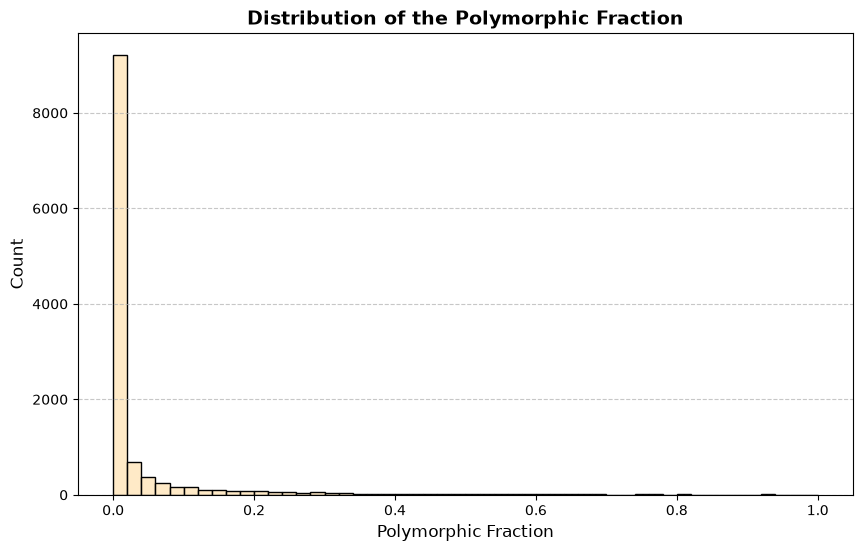

In [94]:
### --- Distribution of the Polymorphic Fraction --- ###
plt.figure(figsize = (10, 6)) # Set figure dimensions.
sns.histplot(df_sim['frac_polymorphic'], bins = 50, color = 'moccasin') # Plots the histogram.

# Add labels, title and horizontal dashed grid lines for clarity.
plt.title('Distribution of the Polymorphic Fraction', fontsize = 14, fontweight = 'bold')
plt.xlabel('Polymorphic Fraction', fontsize = 12)
plt.ylabel('Count', fontsize = 12)
plt.grid(axis = 'y', linestyle = '--', alpha = 0.7)
plt.show()

The distribution is the classical **zero-inflated** shape: a very large spike at 0, and the remaining values spread over the rest of the range. In most parameter sets, the allele is lost or fixed in every single replicate, and only some parameter sets let polymorphism survive.

### **4.2 Classification or Regression?**

The problem can be framed in two valid ways. Both make biological sense, but they answer slightly different questions:

| Framing | Question answered | Cost |
|---|---|---|
| **Regression** on `frac_polymorphic` | *How much* polymorphism do we expect? | Hard to fit on such a skewed variable. |
| **Binary classification** (polymorphic or not) | *Whether* polymorphism is maintained for a given parameter set. | Loses the information on how frequent polymorphism is. |

Because the data is so skewed, a regression model would concentrate on the many zeros and would systematically under-predict polymorphism. The better option is therefore a **binary classification** on all the rows:

- **0**: non polymorphic (`frac_polymorphic = 0`)
- **1**: polymorphic (`frac_polymorphic > 0`)

Biologically, the main interest is whether polymorphism is maintained at all, so giving up the quantification of its frequency is an acceptable trade-off. If quantification becomes relevant later, the problem can be extended into a **hurdle model**: a classifier that decides *whether* polymorphism occurs (this notebook), followed by a regressor trained only on the polymorphic parameter sets that estimates *how frequent* it is.

### **4.3 Class Balance**

We need to know how many parameter sets actually show some polymorphism. A sample is called polymorphic as soon as at least one replicate kept the allele (`POLYMORPH_THRESHOLD = 0.0`). The bar plot shows the share of each class, and the cell also prints the accuracy of a "classifier" that always predicts the majority class: the baseline that every model has to beat.

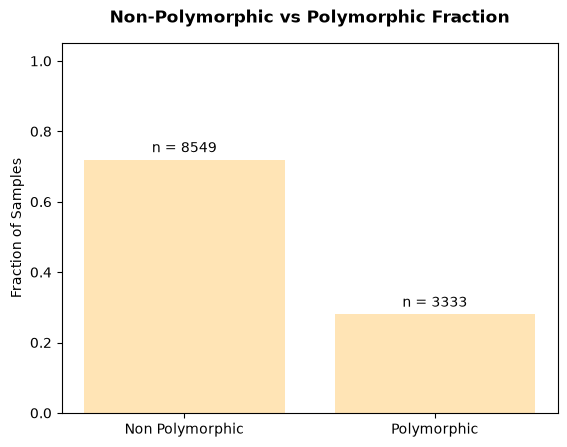

Polymorphic parameter sets:     28.05%  (3,333 of 11,882)
Non polymorphic parameter sets: 71.95%
Majority-class baseline accuracy: 0.719   (a "classifier" that always answers "not polymorphic")
PR AUC of a random classifier:    0.281   (= the prevalence)   |   chance-level ROC AUC: 0.500


In [95]:
### --- Class Balance of the Complete Data Set --- ###
barplot_polymorphic_or_not(df_sim, polymorph_threshold = POLYMORPH_THRESHOLD)

prevalence = (df_sim['frac_polymorphic'] > POLYMORPH_THRESHOLD).mean()
print(f'Polymorphic parameter sets:     {prevalence:.2%}  ({int((df_sim["frac_polymorphic"] > POLYMORPH_THRESHOLD).sum()):,} of {len(df_sim):,})')
print(f'Non polymorphic parameter sets: {1 - prevalence:.2%}')
print(f'Majority-class baseline accuracy: {max(prevalence, 1 - prevalence):.3f}   (a "classifier" that always answers "not polymorphic")')
print(f'PR AUC of a random classifier:    {prevalence:.3f}   (= the prevalence)   |   chance-level ROC AUC: 0.500')

> **Takeaway.** The classes are imbalanced, with polymorphism being the minority class. We deliberately **do not rebalance** the data. Removing part of the majority class would multiply the odds of polymorphism by a constant factor, so the predicted probabilities (and the SHAP baseline, and every "0.5" contour drawn later) would no longer be real probabilities of polymorphism. Instead we keep every row and
>
> 1. report the **majority-class accuracy** as the baseline to beat (a model has to do better than the number printed above);
> 2. report **ROC AUC next to accuracy**, because the AUC does not depend on a decision threshold or on the class prevalence;
> 3. check the **calibration** of the final model in Section 13.5.

### **4.4 Feature Distributions**

The figure below shows the distribution of each feature, separately for polymorphic and non polymorphic samples. As each parameter was drawn uniformly within its range, any visible difference between the two histograms points to a feature that influences polymorphism.

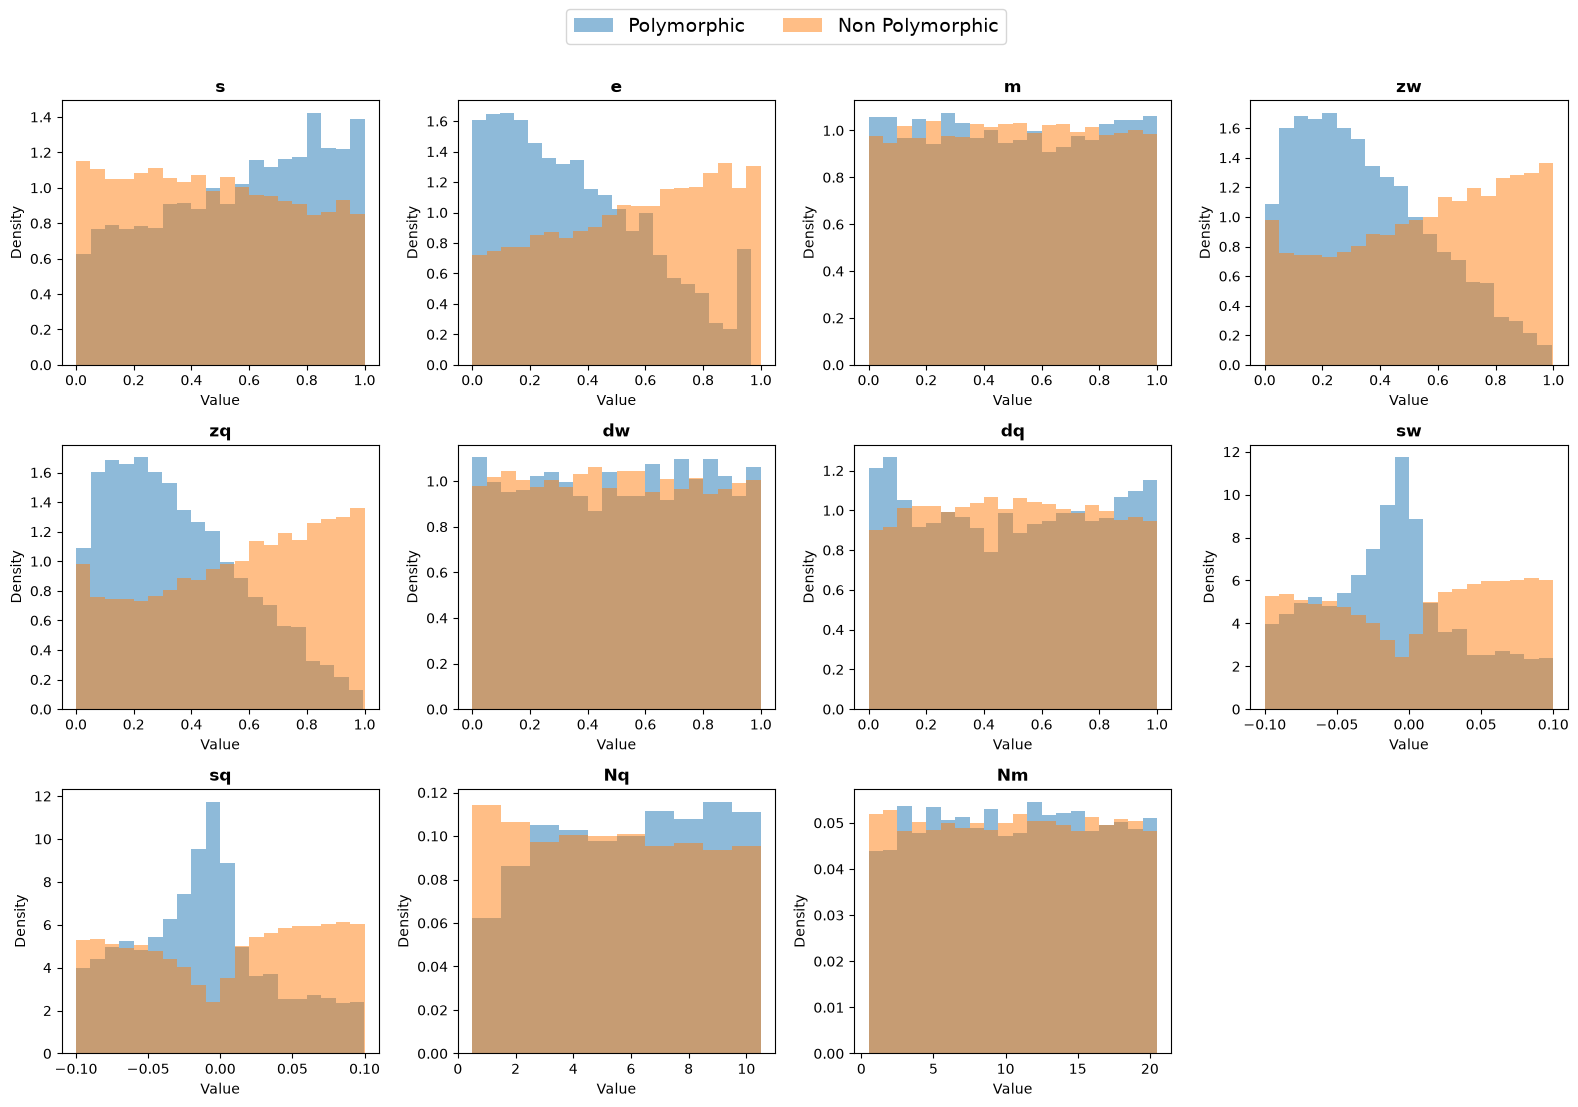

In [96]:
### --- Plotting Using the Helper plot_feature_distr --- ###
plot_feature_distr(df_sim, param_cols_all, polymorph_threshold = POLYMORPH_THRESHOLD)

### **4.5 Correlation Between Features**

The correlation matrix below includes all the parameters and the response variable. We want to **avoid strongly correlated features**, because they make models harder to interpret and make feature-importance measures unreliable. Some correlations are known in advance from the way the simulation is built.

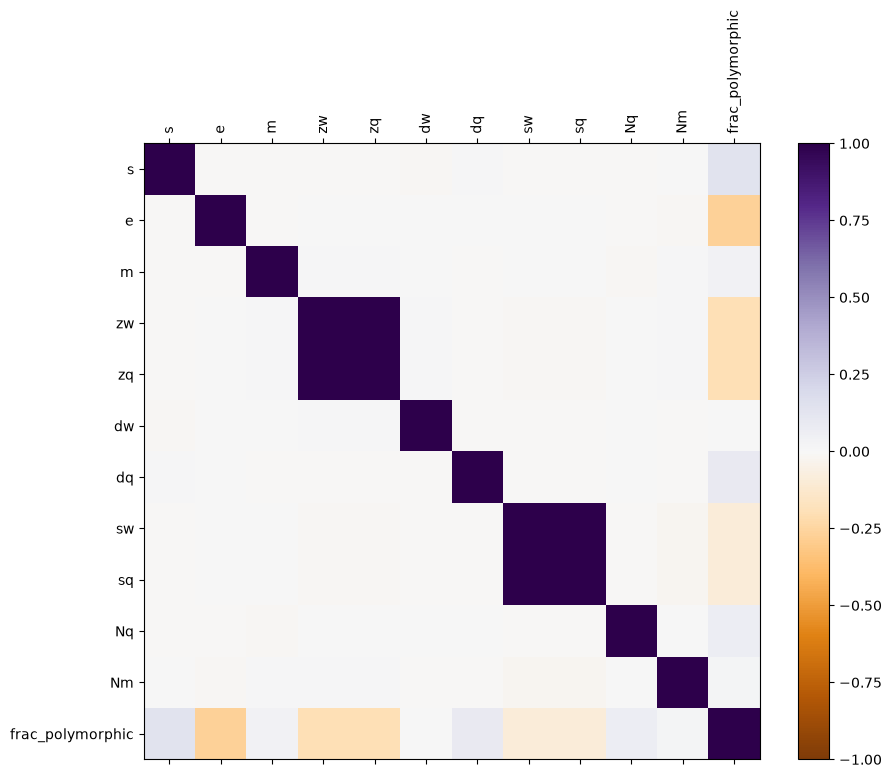

In [97]:
### --- Plotting Using the Helper plot_feature_pairwise_corr --- ###
plot_feature_pairwise_corr(df_sim)

> **Takeaway.** The only strongly correlated pairs are **`zq`/`zw`** and **`sq`/`sw`**, which are identical by design of the simulation. We keep one variable from each pair. Every other parameter is uncorrelated with the others because they were drawn **independently**. This matters later: explanation methods such as SHAP and partial dependence are most trustworthy when features are independent (Section 14).

## **5. Data Preparation**

### **5.1 Removing Redundant Features and Defining the Response**

Two operations are applied:

1. **Dropping duplicated features.** We remove `zw` and `sw`, which are identical to `zq` and `sq` (the cell checks it first).
2. **Binary response.** The response `polymorphic` is 1 if at least one replicate maintained the allele (`frac_polymorphic > POLYMORPH_THRESHOLD`) and 0 otherwise.

The continuous `frac_polymorphic` stays in `df_model` **only for analysis** (label noise in Sections 6.5, 13.6 and 13.7, and observed rates in Section 14). It is never used as a feature.

No rows are removed: the complete data is used.

In [98]:
### --- Redundant Features and Binary Response --- ###
# zw = zq and sw = sq by design of the simulation: verify it, then drop the duplicates.
assert np.allclose(df_sim['zq'], df_sim['zw']) and np.allclose(df_sim['sq'], df_sim['sw'])
feature_cols = [c for c in param_cols_all if c not in ('zw', 'sw')]   # The 9 features.
target_col = 'polymorphic'                                            # The response variable.

df_model = df_sim[feature_cols + ['frac_polymorphic']].copy()
df_model[target_col] = (df_model['frac_polymorphic'] > POLYMORPH_THRESHOLD).astype(int)

print('Features:', feature_cols)
print('Shape of the modelling table:', df_model.shape)
df_model.head(5)

Features: ['s', 'e', 'm', 'zq', 'dw', 'dq', 'sq', 'Nq', 'Nm']
Shape of the modelling table: (11882, 11)


,s,e,m,zq,dw,dq,sq,Nq,Nm,frac_polymorphic,polymorphic
0,0.357718,0.230921,0.483966,0.314324,0.806838,0.825209,0.065894,8,2,0.00,0
1,0.048572,0.359939,0.239023,0.591418,0.944899,0.173094,0.079700,1,3,0.00,0
2,0.892589,0.479211,0.830789,0.885811,0.740353,0.034923,-0.012227,3,7,0.00,0
3,0.072650,0.630431,0.530054,0.282026,0.443350,0.346804,0.040918,7,9,0.00,0
4,0.475356,0.660237,0.224082,0.257872,0.115671,0.831151,-0.058153,3,9,0.26,1


### **5.2 Train / Test Split**

The data is split **once**, with the same class proportions in both parts (stratified split):

| Set | Share | Role |
|---|---|---|
| **Train** | 90% | Fit the models and tune the hyperparameters by **5-fold cross-validation**. |
| **Validation** | (inside the train set) | Each fold of the cross-validation serves once as validation set. |
| **Test** | 10% | Used **once** per model, for the final evaluation. |

In [99]:
### --- Features / Response Separation and Train-Test Split --- ###
# Features are stored as floats (Nq and Nm are counts, but ordered numbers: see Section 5.3).
X = df_model[feature_cols].astype('float64')   # Features, in their original (biological) units.
y = df_model[target_col]                       # Response variable (a Series, not a one-column DataFrame).

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.1, stratify = y, random_state = random_seed)

print(f'Train: {len(X_train)} samples ({y_train.mean():.1%} polymorphic)')
print(f'Test:  {len(X_test)} samples ({y_test.mean():.1%} polymorphic)')

Train: 10693 samples (28.0% polymorphic)
Test:  1189 samples (28.1% polymorphic)


### **5.3 Feature Encoding**

All the models see the same nine features. What changes is how they are scaled:

| Models | Input | Why |
|---|---|---|
| Logistic Regression, MLP | All nine features **min-max scaled to [0, 1]**, inside a `Pipeline` | Regularisation and gradient descent are sensitive to the scale of the features. The scaler is fitted on the training folds only, inside each cross-validation split, so nothing leaks from the validation fold or the test set. |
| Decision Tree, Random Forest, XGBoost | **Raw features** | Trees are invariant to monotone rescaling. Keeping raw units means that thresholds, SHAP values and partial dependence plots are expressed in biological units. |

`Nq` (1 to 10 queens) and `Nm` (1 to 20 males) are counts with a natural order, so they are treated as **numeric** and not one-hot encoded. One-hot encoding would split their importance over 30 dummy columns and make the SHAP output much harder to read.

> **Takeaway.** The data is complete, free of redundant features and ready for machine learning. Before modelling, Section 6 asks how far the data can take us.

## **6. Data Analysis: Coverage of the Feature Space and Label Noise**

Two questions decide how far our conclusions can go.

1. **Coverage.** How well do 11,882 randomly drawn parameter sets cover the nine-dimensional feature space? A model, and any explanation of it, can only be trusted where there is data.
2. **Label noise.** Each label summarises only 100 stochastic replicates, so for some parameter sets it is close to a coin flip. This limits the accuracy that any model can reach.

### **6.1 Pairwise Coverage**

The figure shows a random subsample of 1,500 parameter sets projected on every pair of features. The diagonal shows the marginal distributions.

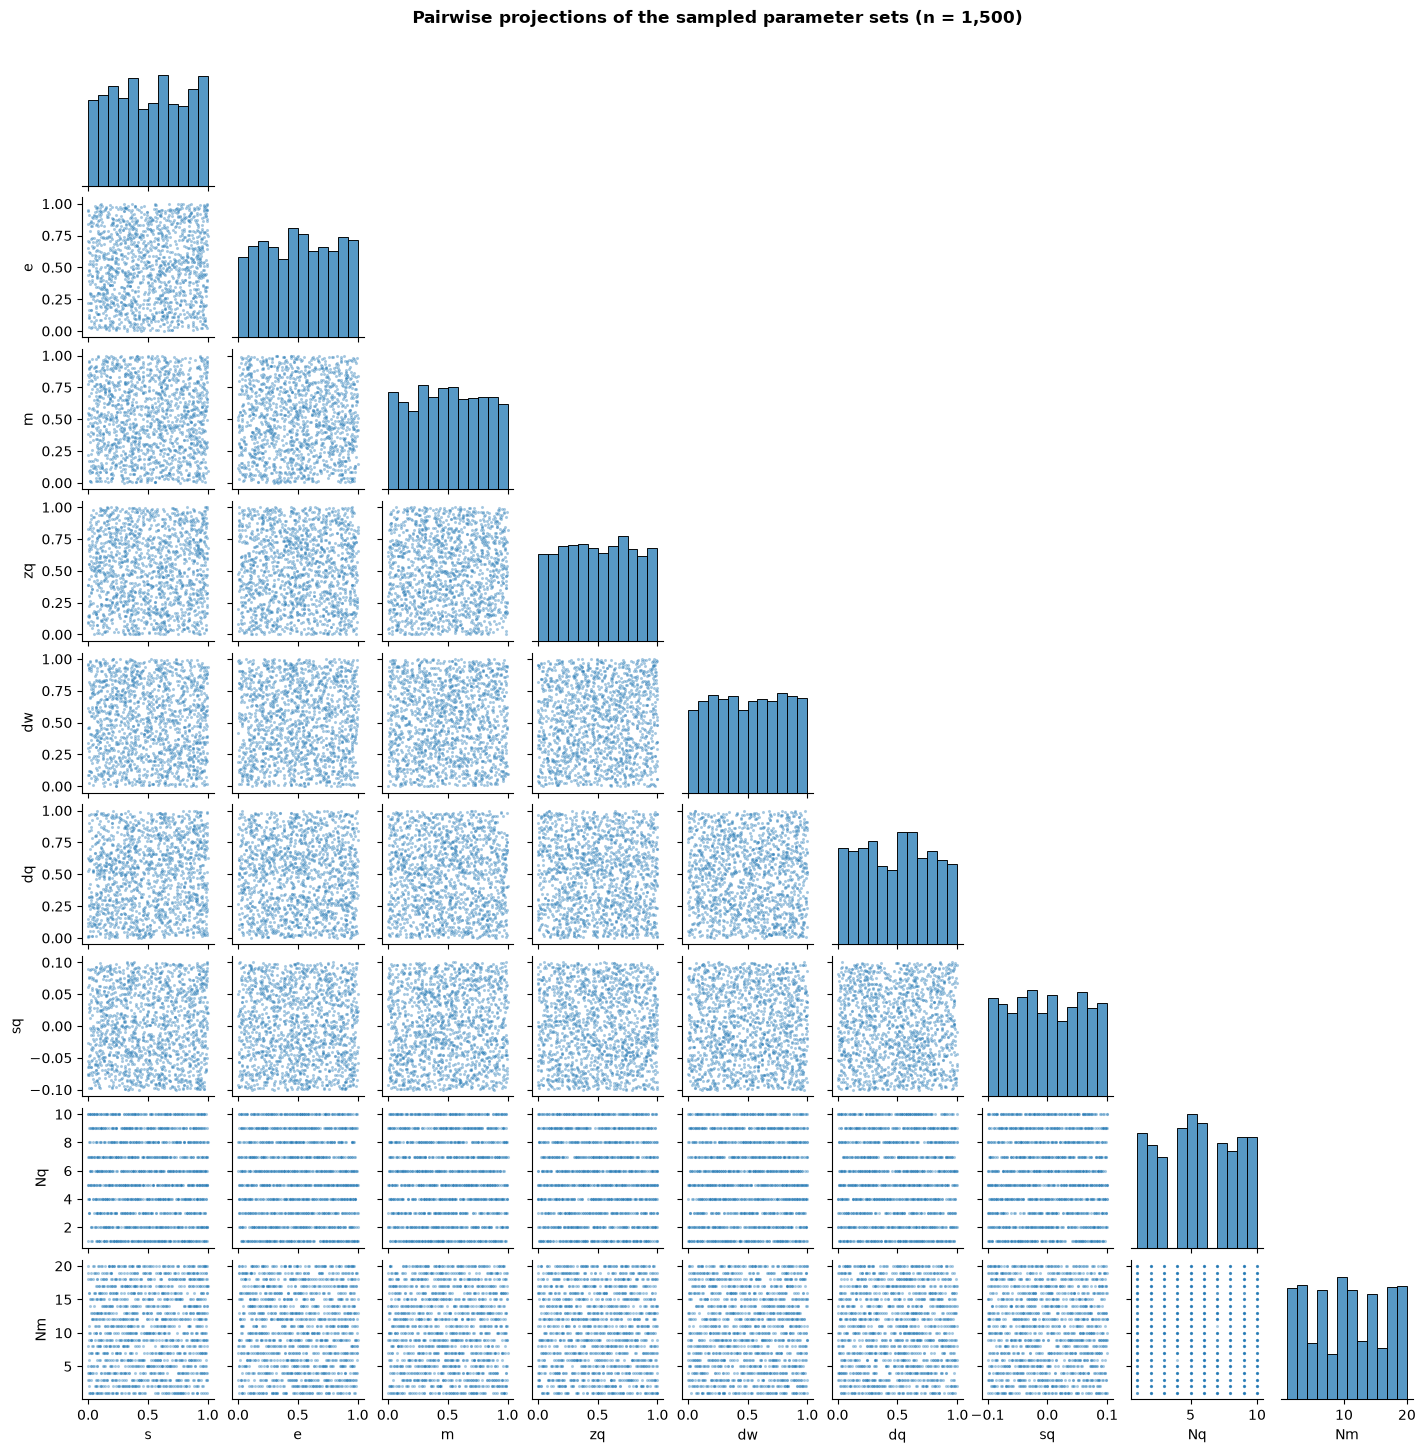

In [100]:
### --- Pairwise Coverage of the Feature Space --- ###
sample_for_pairplot = X.sample(n = 1500, random_state = random_seed)
g = sns.pairplot(sample_for_pairplot, corner = True, diag_kind = 'hist',
                 plot_kws = {'s': 5, 'alpha': 0.4}, height = 1.6)
g.figure.suptitle('Pairwise projections of the sampled parameter sets (n = 1,500)', y = 1.01, fontweight = 'bold')
plt.show()

> **Takeaway.** Every two-dimensional projection is filled evenly, with no empty region and no visible dependence between parameters. The stripes for `Nq` and `Nm` come from the fact that they are integer counts.

### **6.2 How Uniform Is the Design?**

Random sampling leaves gaps and clusters. The **centered discrepancy** quantifies this (lower means more uniform). We compare our design with three references of the same size in the seven continuous dimensions: independent random uniform draws, a Latin hypercube and a scrambled Sobol sequence. The last two are *space-filling* designs that could have been used to generate the parameter sets.

In [101]:
### --- Discrepancy of Our Design Versus Reference Designs --- ###
continuous_cols = [c for c in feature_cols if c not in ('Nq', 'Nm')]   # 7 continuous features.
lo = np.array([PARAM_RANGES[c][0] for c in continuous_cols])
hi = np.array([PARAM_RANGES[c][1] for c in continuous_cols])

def to_unit_cube(frame):
    """Rescale the continuous features to [0, 1] with the documented ranges."""
    return ((frame[continuous_cols].to_numpy() - lo) / (hi - lo))

n_design = min(8192, len(X))   # (the QUICK_RUN subsample can be smaller than 8192)
rng_design = np.random.default_rng(random_seed)
U_ours = to_unit_cube(X.sample(n = n_design, random_state = random_seed))

disc_random = [qmc.discrepancy(rng_design.random((n_design, len(continuous_cols)))) for _ in range(10)]
disc_table = pd.Series({
    'Our parameter sets (random subsample)': qmc.discrepancy(U_ours),
    'Independent uniform draws (mean of 10)': np.mean(disc_random),
    'Latin hypercube': qmc.discrepancy(qmc.LatinHypercube(d = len(continuous_cols), seed = random_seed).random(n_design)),
    'Scrambled Sobol sequence': qmc.discrepancy(qmc.Sobol(d = len(continuous_cols), scramble = True, seed = random_seed).random(n_design)),
}, name = 'Centered discrepancy')
display(disc_table.to_frame())

,Centered discrepancy
Our parameter sets (random subsample),0.000211
Independent uniform draws (mean of 10),0.000335
Latin hypercube,0.000146
Scrambled Sobol sequence,0.000004


> **Takeaway.** Our design is **somewhat more uniform than independent random draws** (centered discrepancy 0.00021 against 0.00034, mean of 10 draws), but less uniform than a Latin hypercube (0.00015) and far less than a scrambled Sobol sequence (0.000004, about 50 times lower). For the same number of simulations, a space-filling design would have left fewer gaps. This is useful to know when deciding how to spend further simulation time (Section 15).

### **6.3 How Far Apart Are the Points?**

In seven continuous dimensions, even thousands of points are sparse. The histogram shows, for every training point, the distance to its nearest neighbour in the unit cube. For reference, one cell of a grid with 10 bins per axis has a width of 0.1.

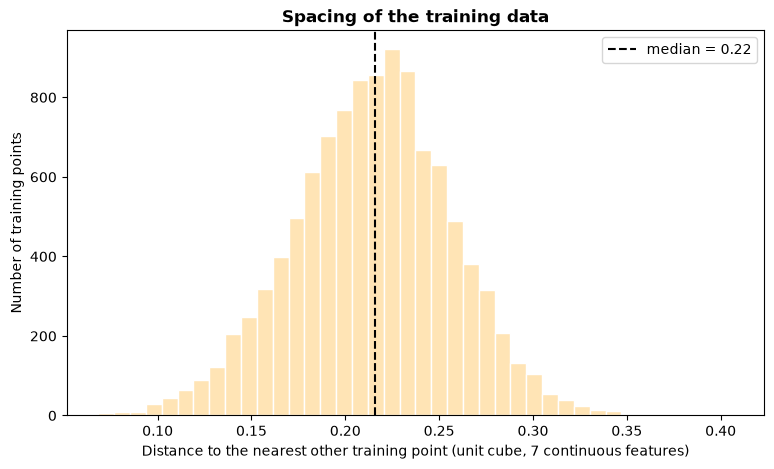

In [102]:
### --- Nearest-Neighbour Distances in the Training Set --- ###
U_train = to_unit_cube(X_train)
nn_dist = cKDTree(U_train).query(U_train, k = 2)[0][:, 1]   # k = 2: the first neighbour is the point itself.

plt.figure(figsize = (9, 5))
plt.hist(nn_dist, bins = 40, color = 'moccasin', edgecolor = 'white')
plt.axvline(np.median(nn_dist), color = 'black', linestyle = '--', label = f'median = {np.median(nn_dist):.2f}')
plt.xlabel('Distance to the nearest other training point (unit cube, 7 continuous features)')
plt.ylabel('Number of training points')
plt.title('Spacing of the training data', fontweight = 'bold')
plt.legend()
plt.show()

> **Takeaway.** One- and two-parameter effects are well supported by data, but fine structure involving many parameters at once is not: the median distance to the nearest neighbour is about 0.22 in the unit cube, more than twice the width of a 10-bin cell (0.1). This is why the later analyses (Section 14) concentrate on one or two parameters at a time and use bins that contain enough points.

### **6.4 Is the Test Set Drawn From the Same Region as the Training Set?**

**Adversarial validation** trains a classifier to tell training samples from test samples using only the features. If the two sets come from the same distribution, this is impossible and the cross-validated AUC stays near 0.5.

In [103]:
### --- Adversarial Validation: Train Versus Test --- ###
X_all = pd.concat([X_train, X_test])
is_test = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))].astype(int)

adv_scores = cross_val_score(
    RandomForestClassifier(n_estimators = 100, min_samples_leaf = 20, random_state = random_seed, n_jobs = -1),
    X_all, is_test, cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = random_seed), scoring = 'roc_auc')
print(f'Adversarial ROC AUC (train vs test): {adv_scores.mean():.3f} +/- {adv_scores.std():.3f}   (0.5 = indistinguishable)')

Adversarial ROC AUC (train vs test): 0.495 +/- 0.016   (0.5 = indistinguishable)


### **6.5 How Noisy Is the Label?**

A parameter set is called polymorphic if **one** replicate out of 100 kept the allele. A parameter set with `frac_polymorphic = 0.01` and one with `0.00` may differ only by chance. The table shows how many parameter sets would stay polymorphic under stricter thresholds, and the histogram shows how the positives are distributed.

,share of all parameter sets above the threshold,share of the current positives kept
threshold on frac_polymorphic,,
0.00,0.281,1.000
0.01,0.224,0.800
0.05,0.136,0.483
0.10,0.093,0.332
0.25,0.043,0.153
0.50,0.015,0.054


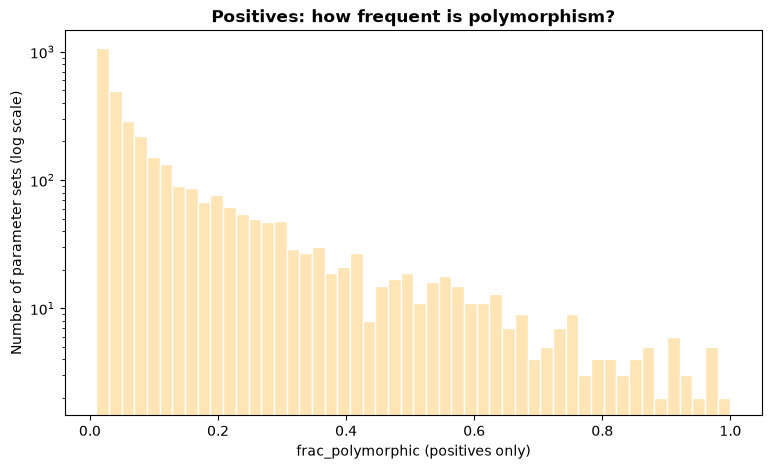

In [104]:
### --- Label Noise: How Many Positives Sit Close to the Threshold? --- ###
frac_all = df_model['frac_polymorphic']
label_noise = pd.DataFrame({
    'share of all parameter sets above the threshold': [(frac_all > t).mean() for t in [0.0, 0.01, 0.05, 0.10, 0.25, 0.50]],
    'share of the current positives kept': [(frac_all > t).sum() / (frac_all > 0).sum() for t in [0.0, 0.01, 0.05, 0.10, 0.25, 0.50]],
}, index = pd.Index([0.0, 0.01, 0.05, 0.10, 0.25, 0.50], name = 'threshold on frac_polymorphic'))
display(label_noise.round(3))

plt.figure(figsize = (9, 5))
plt.hist(frac_all[frac_all > 0], bins = 50, color = 'moccasin', edgecolor = 'white')
plt.yscale('log')
plt.xlabel('frac_polymorphic (positives only)')
plt.ylabel('Number of parameter sets (log scale)')
plt.title('Positives: how frequent is polymorphism?', fontweight = 'bold')
plt.show()

> **Takeaway.** The table tells us which share of the positive class is only weakly polymorphic. Those parameter sets sit close to the 0 / 1 boundary, where the label is partly decided by chance, so no classifier can be expected to reach 100% accuracy. Section 13.6 shows where the errors of the best model concentrate, and Section 13.7 repeats the analysis with stricter thresholds.

## **7. Modelling Strategy**

We train five classifiers in order of increasing flexibility, which also means decreasing interpretability. The goal is not only to reach a high accuracy but also to see **how much each additional level of complexity buys**, and what we lose in biological insight in exchange.

| Section | Model | Main strength |
|---|---|---|
| 8 | Logistic regression | Simple, linear baseline |
| 9 | Decision tree | Fully readable "white-box" rules |
| 10 | Random forest | Ensemble of trees, much more accurate |
| 11 | XGBoost | Gradient-boosted trees, usually the most accurate on tabular data |
| 12 | Multilayer perceptron | Neural network, can capture complex non-linearities |

### **7.1 Common Protocol**

Every model is tuned and evaluated in exactly the same way:

- **5-fold stratified cross-validation** on the training set, for every model. Each fold serves once as the **validation set**.
- **Three metrics, computed for every candidate configuration**: **Accuracy** (the share of correct predictions at a 0.5 threshold), **PR AUC** (precision recall curve) and **ROC AUC** (how well the predicted probabilities rank polymorphic above non polymorphic parameter sets, whatever the threshold). The **primary metric**, which selects the configuration that is refitted on the whole training set, is the ROC AUC, because later we interpret the *probabilities* of the model. The accuracy of the same configuration is always reported, and the notebook checks whether the configuration that would maximise accuracy is the same one (`PRIMARY_METRIC` can be switched to `'accuracy'` or `'pr_auc'` in one line).
- **Randomised search** (`RandomizedSearchCV`) for models with a large search space, **exhaustive grid search** (`GridSearchCV`) for the logistic regression, which has a single hyperparameter.
- **Reported numbers**, for the selected configuration:
  - **Train**: mean score over the five training folds.
  - **Validation**: mean score (and standard deviation) over the five validation folds.
  - **Test**: score on the held-out test set, computed once, after the tuning.

  A large gap between train and validation is a sign of overfitting. A validation score that is much lower than the test score, or a large standard deviation across folds, would signal an unstable model.
- A **confusion matrix**, **PR curve** and a **ROC curve** on the test set.
- A **hyperparameter table** per model: searched values, chosen value, whether the chosen value sits at the edge of the searched range, and the reason for that range. The tables are collected in Section 13.1.

Tree-based models and neural networks overfit easily, so the search spaces of the tree-based models were restricted to limit model complexity. When a chosen value equals the upper cap of its range, the cap is **binding** by design. The tables flag these cases explicitly.

The cell below defines the helpers that implement this protocol.

In [105]:
### --- Cross-Validation Protocol, Tuning Helper and Result Tables --- ###
CV = StratifiedKFold(n_splits = 5, shuffle = True, random_state = random_seed)    # Same 5 folds for every model.
SCORING = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'}                   # Both metrics, for every candidate.
PRIMARY_METRIC = 'roc_auc'                                                        # Metric used to pick the final configuration.
METRIC_LABEL = {'pr_auc': 'PR AUC', 'roc_auc': 'ROC AUC'}
SEARCH_ROWS = BUDGET['search_rows']                                               # Training rows used by the hyperparameter search.
RESULTS = {}                                                                      # Collects everything for the final tables.
prevalence_train = y_train.mean()                                                 # PR AUC of a random classifier.
majority_baseline = 1 - prevalence_train                                          # Accuracy of "always not polymorphic".

def _short(param_name):
    """Remove the pipeline prefix, e.g. 'clf__C' -> 'C'."""
    return param_name.split('__')[-1]

def f1_optimal_threshold(y_true, proba):
    """Probability threshold that maximises the F1 score of the positive class."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[int(np.argmax(f1))])

def threshold_metrics(y_true, proba, threshold):
    """Precision, recall, F1, MCC and balanced accuracy of the positive class at a given threshold."""
    pred = (np.asarray(proba) >= threshold).astype(int)
    return {'precision': precision_score(y_true, pred, zero_division = 0), 'recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred), 'MCC': matthews_corrcoef(y_true, pred),
            'balanced accuracy': balanced_accuracy_score(y_true, pred)}

def tune_model(name, estimator, param_space, rationale, n_iter = None):
    """Tune a model, evaluate it by 5-fold CV on the whole training set, refit it and store the results.

    Stage 1: hyperparameter search on a stratified subsample of SEARCH_ROWS training rows (selected on PRIMARY_METRIC).
    Stage 2: the selected configuration is cross-validated on ALL the training rows (train / validation scores,
             out-of-fold predictions for the F1-optimal threshold) and refitted on all of them.
    n_iter = None runs an exhaustive grid search, otherwise a randomised search with n_iter candidates.
    """
    if len(X_train) > SEARCH_ROWS:
        X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size = SEARCH_ROWS, stratify = y_train, random_state = random_seed)
    else:
        X_sub, y_sub = X_train, y_train

    common = dict(cv = CV, scoring = SCORING, refit = False, n_jobs = -1)
    if n_iter is None:
        search = GridSearchCV(estimator, param_space, **common)
    else:
        search = RandomizedSearchCV(estimator, param_space, n_iter = n_iter, random_state = random_seed, **common)
    search.fit(X_sub, y_sub)

    cv_res = pd.DataFrame(search.cv_results_)
    best = int(cv_res[f'rank_test_{PRIMARY_METRIC}'].idxmin())     # Configuration selected on the primary metric.
    best_params = cv_res.loc[best, 'params']
    same_config = {m: int(cv_res[f'rank_test_{m}'].idxmin()) == best for m in SCORING}

    def build():
        model = clone(estimator).set_params(**best_params)
        if 'n_jobs' in model.get_params():
            model.set_params(n_jobs = -1)                          # The search parallelises over candidates, this stage over trees.
        return model

    fold = {m: {'train': [], 'val': []} for m in SCORING}
    oof = np.zeros(len(X_train))                                   # Out-of-fold probability of every training row.
    for tr, va in CV.split(X_train, y_train):
        m = build().fit(X_train.iloc[tr], y_train.iloc[tr])
        p_tr, p_va = m.predict_proba(X_train.iloc[tr])[:, 1], m.predict_proba(X_train.iloc[va])[:, 1]
        oof[va] = p_va
        fold['pr_auc']['train'].append(average_precision_score(y_train.iloc[tr], p_tr))
        fold['pr_auc']['val'].append(average_precision_score(y_train.iloc[va], p_va))
        fold['roc_auc']['train'].append(roc_auc_score(y_train.iloc[tr], p_tr))
        fold['roc_auc']['val'].append(roc_auc_score(y_train.iloc[va], p_va))

    model = build().fit(X_train, y_train)
    p_test = model.predict_proba(X_test)[:, 1]
    metrics = {m: {'train': np.mean(fold[m]['train']), 'val': np.mean(fold[m]['val']), 'val_sd': np.std(fold[m]['val'])} for m in SCORING}
    metrics['pr_auc']['test'] = average_precision_score(y_test, p_test)
    metrics['roc_auc']['test'] = roc_auc_score(y_test, p_test)

    threshold = f1_optimal_threshold(y_train, oof)
    RESULTS[name] = dict(model = model, space = param_space, rationale = rationale, best_params = best_params, metrics = metrics,
                         search_cv = cv_res, search_rows = len(X_sub), same_config = same_config, threshold = threshold, oof = oof,
                         thr_oof = threshold_metrics(y_train, oof, threshold), thr_test = threshold_metrics(y_test, p_test, threshold))
    show_metrics(name)
    return model

def show_metrics(name):
    """Print the train / validation / test table of a tuned model, and its threshold-based metrics."""
    r = RESULTS[name]
    m = r['metrics']
    table = pd.DataFrame({
        'PR AUC':  [m['pr_auc']['train'], m['pr_auc']['val'], m['pr_auc']['val_sd'], m['pr_auc']['test']],
        'ROC AUC': [m['roc_auc']['train'], m['roc_auc']['val'], m['roc_auc']['val_sd'], m['roc_auc']['test']],
    }, index = ['Train (mean of the 5 training folds)', 'Validation (mean of the 5 validation folds)',
                'Validation (sd across the 5 folds)', 'Test (held-out set)'])
    print(f'--- {name}: {len(r["search_cv"])} configuration(s) x 5 folds searched on {r["search_rows"]:,} rows, '
          f'selected on {METRIC_LABEL[PRIMARY_METRIC]}; scores below: 5-fold CV on all {len(X_train):,} training rows ---')
    print('Selected hyperparameters:', {_short(k): v for k, v in r['best_params'].items()})
    display(table.round(4))
    print(f'Random classifier: PR AUC = {prevalence_train:.3f}  |  ROC AUC = 0.500')
    thr_table = pd.DataFrame({'out-of-fold (training rows)': r['thr_oof'], 'test set': r['thr_test']}).T
    print(f'Decision threshold maximising the F1 on the out-of-fold predictions: {r["threshold"]:.3f}')
    display(thr_table.round(3))
    for metric, same in r['same_config'].items():
        if not same:
            i = int(r['search_cv'][f'rank_test_{metric}'].idxmin())
            print(f'Note: the configuration with the best search {METRIC_LABEL[metric]} differs from the selected one: '
                  f'{ {_short(k): v for k, v in r["search_cv"].loc[i, "params"].items()} } '
                  f'(search PR AUC {r["search_cv"].loc[i, "mean_test_pr_auc"]:.4f}, search ROC AUC {r["search_cv"].loc[i, "mean_test_roc_auc"]:.4f}).')

def hyperparam_table(name):
    """Searched values, chosen value, edge-of-range flag and reason for every hyperparameter of a model."""
    r = RESULTS[name]
    chosen_all = {_short(k): v for k, v in r['best_params'].items()}
    rows = []
    for key, values in r['space'].items():
        p = _short(key)
        values = list(values)
        chosen = chosen_all[p]
        numeric = all(isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool) for v in values)
        edge = ''
        if numeric and len(values) > 1:
            if chosen == max(values):
                edge = 'at upper cap'
            elif chosen == min(values):
                edge = 'at lower bound'
        searched = f'{min(values)} to {max(values)} ({len(values)} values)' if numeric and len(values) > 6 else str(values)
        rows.append({'Model': name, 'Hyperparameter': p, 'Searched values': searched,
                     'Chosen': chosen, 'Edge of range': edge, 'Why this range': r['rationale'].get(p, '')})
    return pd.DataFrame(rows)

> **Note on the preprocessing.** Preprocessing is part of the model. The logistic regression and the MLP are `Pipeline` objects (min-max scaling, then the classifier), so the scaler is re-fitted on the training part of every fold. The tree-based models take the raw features directly.

## **8. Logistic Regression**

We start simple with a **logistic regression**. It is a linear model: it can only capture relationships in which each feature pushes the log-odds of polymorphism steadily in one direction, so it makes a good baseline.

Its only tunable hyperparameter is `C`, the inverse of the regularisation strength (a larger `C` means weaker regularisation). We search over six values on a logarithmic scale, from very strong shrinkage to almost none. With only six candidates, the search is **exhaustive** (`GridSearchCV`) and uses the common 5-fold protocol.

In [106]:
### --- Best Logistic Regression Model --- ###
lr_pipeline = Pipeline([
    ('scale', MinMaxScaler()),        # Fitted inside every CV training fold.
    ('clf', LogisticRegression(max_iter = 2000, random_state = random_seed)),
])
lr_space = {'clf__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}
lr_rationale = {
    'C': 'Inverse regularisation strength, on a log scale. 0.001 = very strong L2 shrinkage (underfitting risk), '
         '100 = almost none. Only 6 values, so every one is tried (grid search).',
}

best_log_reg_model = tune_model('Logistic Regression', lr_pipeline, lr_space, lr_rationale, n_iter = None)
display(hyperparam_table('Logistic Regression'))

--- Logistic Regression: 6 configuration(s) x 5 folds searched on 10,693 rows, selected on ROC AUC; scores below: 5-fold CV on all 10,693 training rows ---
Selected hyperparameters: {'C': 100.0}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.5734,0.8068
Validation (mean of the 5 validation folds),0.5741,0.8057
Validation (sd across the 5 folds),0.0250,0.0106
Test (held-out set),0.5839,0.8059


Random classifier: PR AUC = 0.280  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.313


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.541,0.709,0.613,0.442,0.737
test set,0.541,0.686,0.605,0.431,0.729


Note: the configuration with the best search PR AUC differs from the selected one: {'C': 0.001} (search PR AUC 0.5760, search ROC AUC 0.8048).


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,Logistic Regression,C,"[0.001, 0.01, 0.1, 1.0, 10.0, 100.0]",100.0,at upper cap,"Inverse regularisation strength, on a log scale. 0.001 = very strong L2 shrinkage (underfitting risk), 100 = almost ..."


Because the features were min-max scaled, the coefficients below are directly comparable: each one is the change in log-odds when the feature goes from the bottom to the top of its range, the other features being fixed. A linear model can only describe such monotone, additive effects.

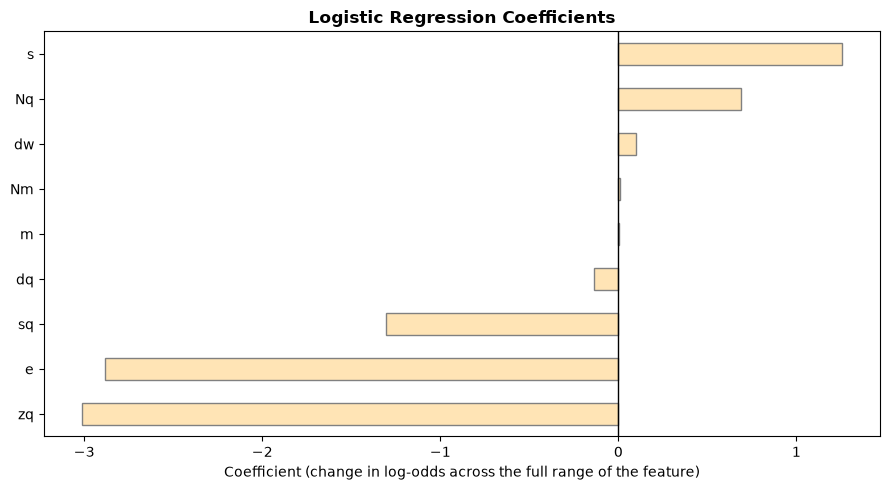

In [107]:
### --- Coefficients of the Logistic Regression (Scaled Features) --- ###
lr_coefs = pd.Series(best_log_reg_model.named_steps['clf'].coef_[0], index = feature_cols).sort_values()
plt.figure(figsize = (9, 5))
lr_coefs.plot(kind = 'barh', color = 'moccasin', edgecolor = 'gray')
plt.axvline(0, color = 'black', linewidth = 1)
plt.xlabel('Coefficient (change in log-odds across the full range of the feature)')
plt.title('Logistic Regression Coefficients', fontweight = 'bold')
plt.tight_layout()
plt.show()

The three accuracies and AUCs in the table above tell us whether the model overfits (train far above validation) and how far it is above the baseline. Here the three sets are very close together (accuracy 0.769 / 0.769 / 0.768, ROC AUC 0.807 / 0.806 / 0.806), so there is **no overfitting**. The model is, however, only about 5 points of accuracy above the majority-class baseline (0.720), with a ROC AUC of 0.81: the limit comes from the model, which is too simple, not from the data. The selected `C = 100` sits at the upper cap of the grid (almost no regularisation), but `C = 10` gives the same validation scores (accuracy 0.769, ROC AUC 0.806), so the exact value hardly matters.

### **8.1 Confusion Matrix**

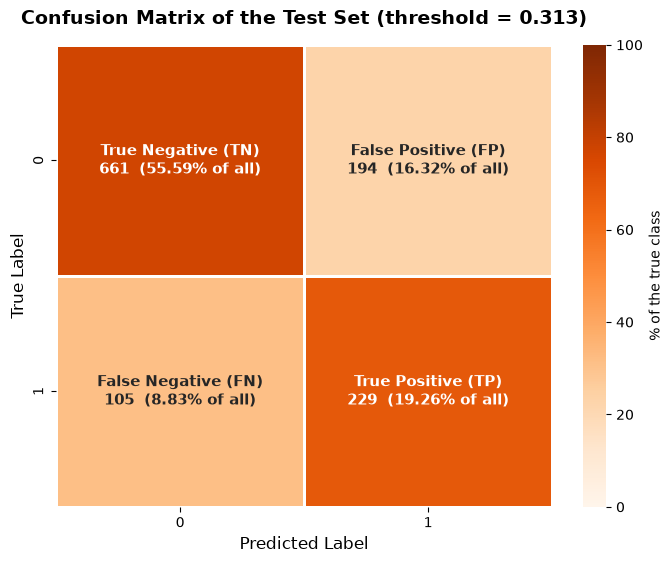

In [108]:
### --- Confusion Matrix for Logistic Regression --- ###
plot_confusion_matrix(model = best_log_reg_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Logistic Regression']['threshold'])

### **8.2 ROC Curve and PR Curve**

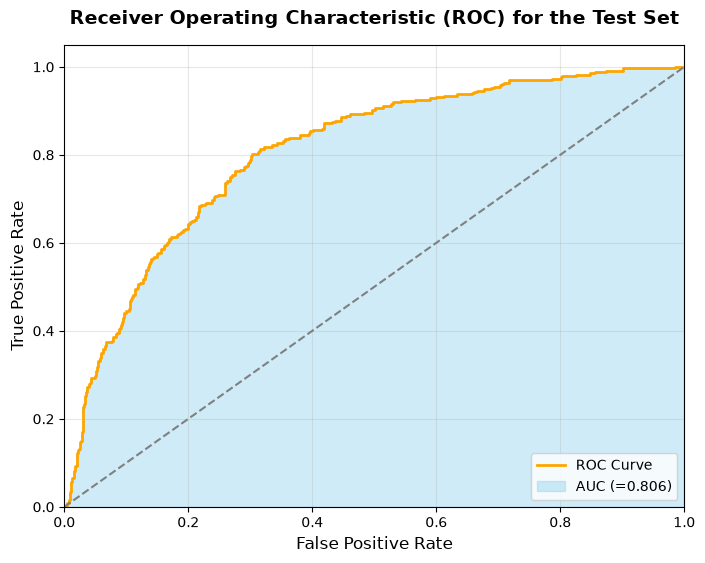

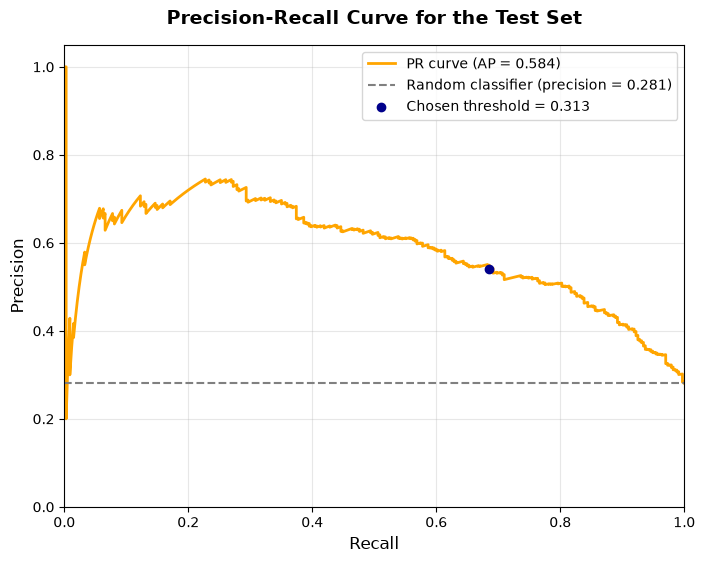

In [109]:
### --- ROC and PR Curve for Logistic Regression --- ###
plot_roc(model = best_log_reg_model, X_set = X_test, y_set = y_test, type_of_set = "Test")
plot_pr(model = best_log_reg_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Logistic Regression']['threshold'])

> **Takeaway.** The logistic regression is the linear baseline (test ROC AUC 0.806, test accuracy 0.768). As it cannot represent interactions or thresholds, any remaining error probably comes from **non-linear relationships** between the parameters and polymorphism. We explore this with a decision tree.

## **9. Decision Tree**

A **decision tree** repeatedly splits the data with simple threshold rules on one feature at a time, so it can capture non-linear effects and interactions. Trees tend to **overfit**: a default, unrestricted tree memorises the training set.

To limit this, the search combines two strategies:

- Limits on the **size of the tree** (depth, minimum leaf size) and on the number of features examined per split.
- **Cost-complexity pruning** (`ccp_alpha`), which removes branches that add little accuracy.

The search tests 60 random combinations with the common 5-fold protocol.

In [110]:
### --- Best Decision Tree --- ###
dt_space = {
    'max_depth': list(range(1, 10)),
    'min_samples_leaf': list(range(5, 20)),
    'max_features': [None, 'sqrt', 'log2'],
    'criterion': ['gini', 'entropy'],
    'ccp_alpha': [0.0, 0.001, 0.002, 0.003, 0.004, 0.006, 0.01],
}
dt_rationale = {
    'max_depth': 'Main complexity control: a tree of depth d can encode interactions of up to d features. 1 is a single split, '
                 '10 is deep enough to memorise the training set, so the search brackets the useful range.',
    'min_samples_leaf': 'Forbids leaves built on a handful of rows. Each label comes from only 100 replicates, so tiny leaves '
                        'would fit noise. 5 to 19 is the zone where a default tree stops memorising.',
    'max_features': 'Number of features examined at each split: all (None), sqrt or log2 of the number of features. '
                    'Fewer features add randomness and can reduce variance.',
    'criterion': 'Impurity measure for the splits. Gini and entropy usually give similar trees, both are tried.',
    'ccp_alpha': 'Cost-complexity pruning strength, from 0 (no pruning) to 0.01 (aggressive). Pruning removes branches '
                 'that add little, which also makes the tree easier to read.',
}

best_model_dt = tune_model('Decision Tree', DecisionTreeClassifier(random_state = random_seed),
                           dt_space, dt_rationale, n_iter = BUDGET['n_iter']['Decision Tree'])
display(hyperparam_table('Decision Tree'))
print(f'Selected tree: depth {best_model_dt.get_depth()}, {best_model_dt.get_n_leaves()} leaves.')

--- Decision Tree: 60 configuration(s) x 5 folds searched on 10,693 rows, selected on ROC AUC; scores below: 5-fold CV on all 10,693 training rows ---
Selected hyperparameters: {'min_samples_leaf': 12, 'max_features': 'sqrt', 'max_depth': 9, 'criterion': 'entropy', 'ccp_alpha': 0.001}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.8092,0.9229
Validation (mean of the 5 validation folds),0.7219,0.8787
Validation (sd across the 5 folds),0.0221,0.0125
Test (held-out set),0.7311,0.8797


Random classifier: PR AUC = 0.280  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.335


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.623,0.796,0.699,0.569,0.804
test set,0.665,0.707,0.685,0.557,0.784


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,Decision Tree,max_depth,1 to 9 (9 values),9,at upper cap,"Main complexity control: a tree of depth d can encode interactions of up to d features. 1 is a single split, 10 is d..."
1,Decision Tree,min_samples_leaf,5 to 19 (15 values),12,,"Forbids leaves built on a handful of rows. Each label comes from only 100 replicates, so tiny leaves would fit noise..."
2,Decision Tree,max_features,"[None, 'sqrt', 'log2']",sqrt,,"Number of features examined at each split: all (None), sqrt or log2 of the number of features. Fewer features add ra..."
3,Decision Tree,criterion,"['gini', 'entropy']",entropy,,"Impurity measure for the splits. Gini and entropy usually give similar trees, both are tried."
4,Decision Tree,ccp_alpha,0.0 to 0.01 (7 values),0.001,,"Cost-complexity pruning strength, from 0 (no pruning) to 0.01 (aggressive). Pruning removes branches that add little..."


Selected tree: depth 9, 94 leaves.


### **9.1 The Tree Itself**

Each box shows a rule, the number of samples, the class distribution and the majority class (colour). Reading the tree from the root to a leaf gives a set of conditions under which polymorphism is, or is not, predicted. Only the first four levels are drawn, to keep the figure readable.

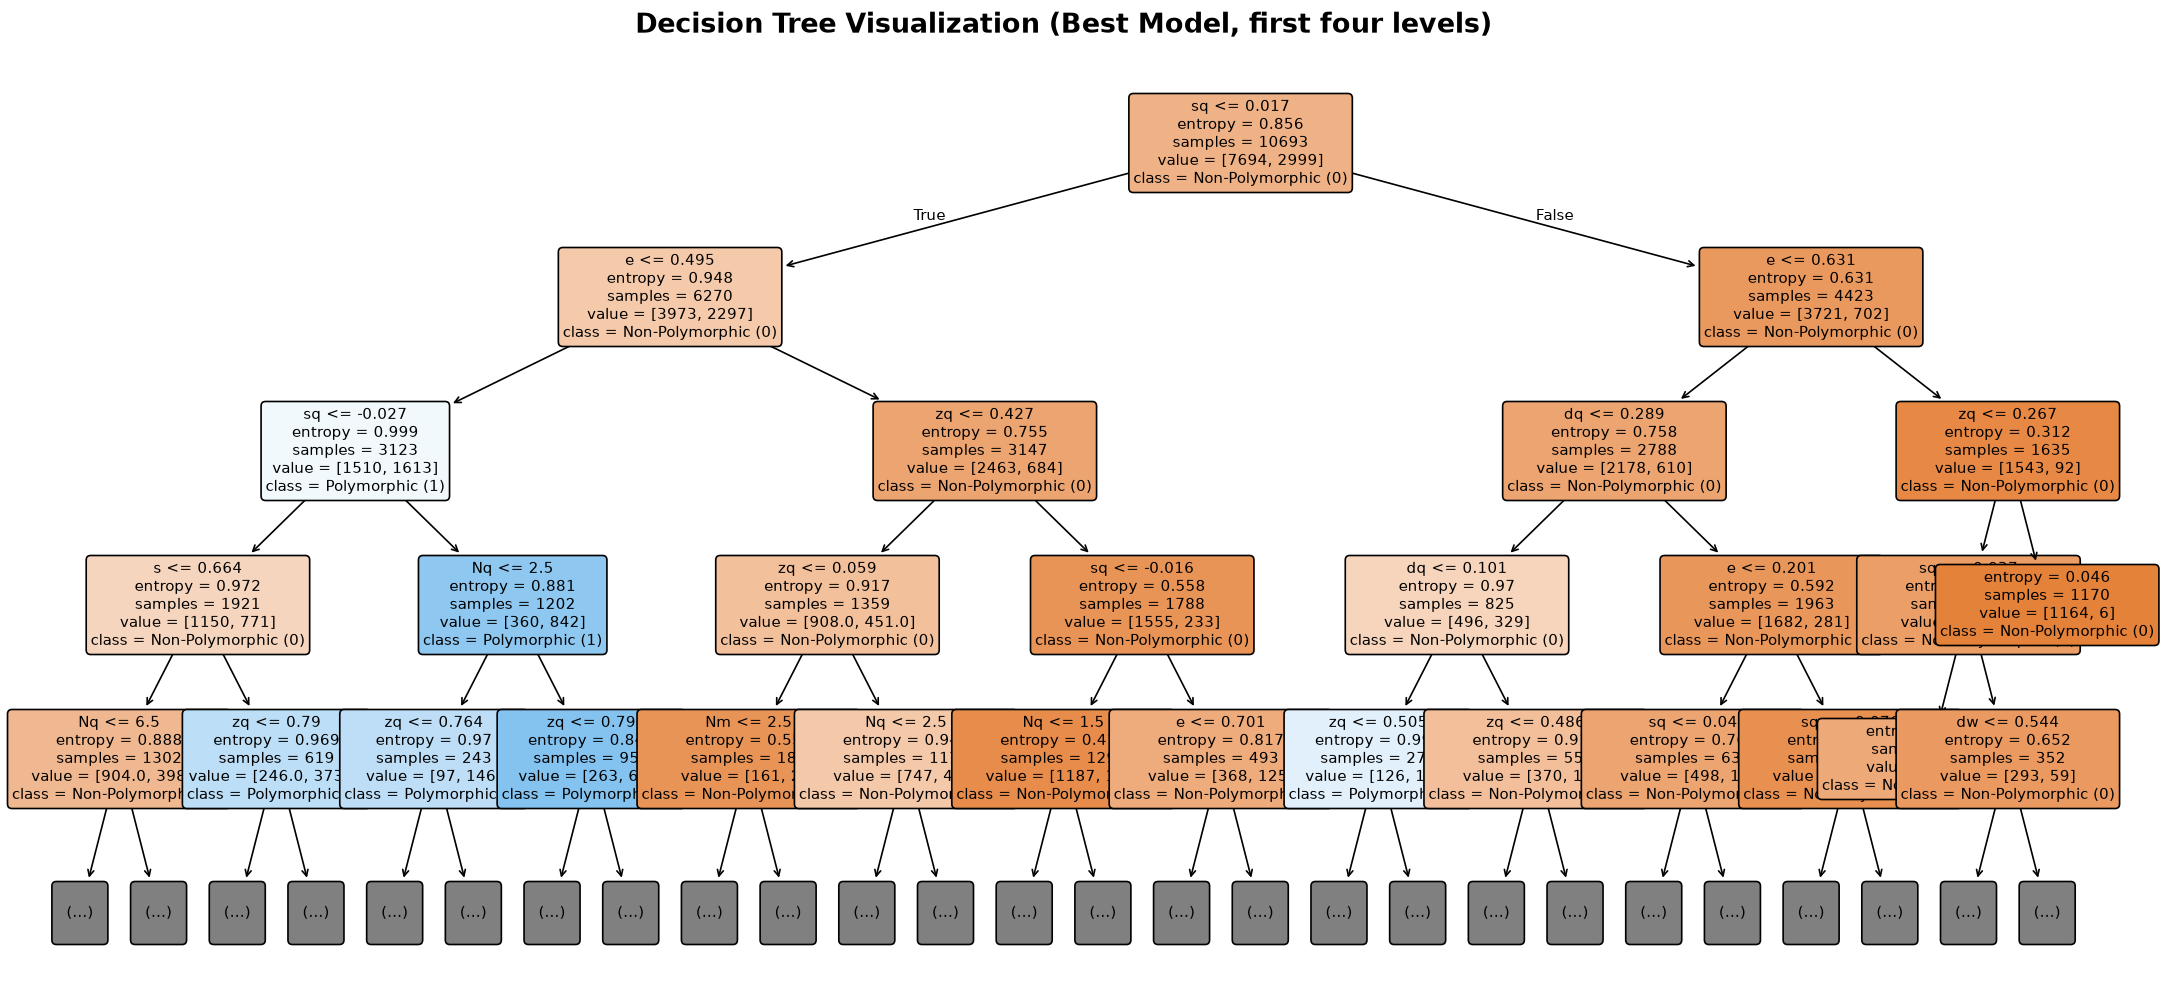

In [111]:
### --- Plot the Decision Tree (first four levels) --- ###
plt.figure(figsize = (22, 10), dpi = 120)
plot_tree(
    best_model_dt,
    feature_names = feature_cols,
    class_names = ['Non-Polymorphic (0)', 'Polymorphic (1)'],
    filled = True,          # Colors nodes by majority class.
    rounded = True,         # Rounds the node boxes for a clean look.
    max_depth = 4,          # Draw only the first four levels.
    fontsize = 9,
)
plt.title("Decision Tree Visualization (Best Model, first four levels)", fontsize = 16, fontweight = 'bold', pad = 20)
plt.show()

The selected tree is not tiny: it has depth 9 (the **upper cap** of the search) and 94 leaves, and only its first four levels are drawn. Those first levels are readable and show which parameters and thresholds are used first, but the full tree is too large to be read as a set of biological rules. It overfits a little: accuracy 0.857 / 0.826 / 0.814 and ROC AUC 0.923 / 0.879 / 0.880 on train / validation / test. It nonetheless improves clearly on the logistic regression, so we keep going to see how much more accuracy more complex models can add.

### **9.2 Confusion Matrix**

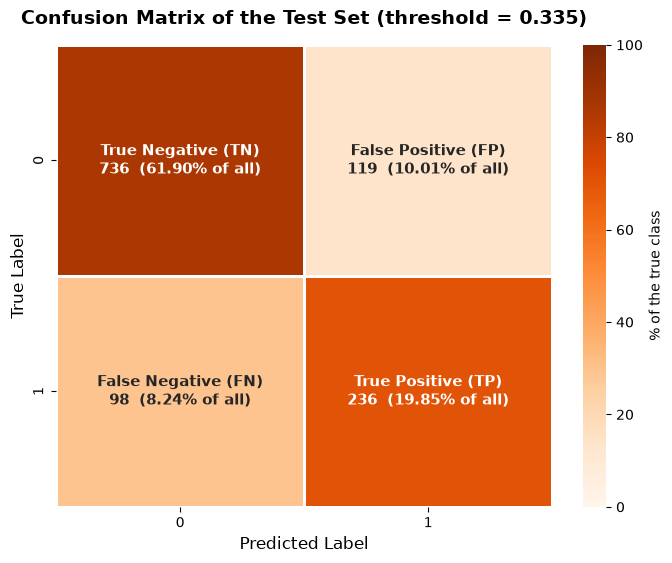

In [112]:
### --- Confusion Matrix for Decision Tree --- ###
plot_confusion_matrix(model = best_model_dt, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Decision Tree']['threshold'])

### **9.3 ROC Curve and PR Curve**

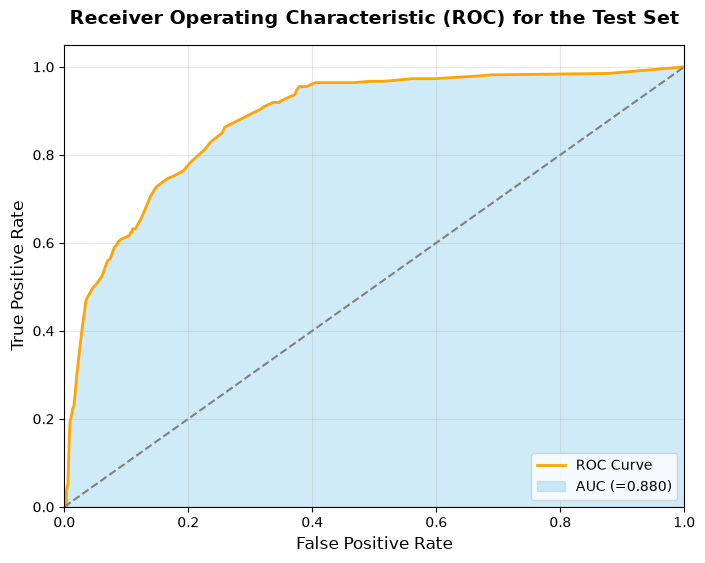

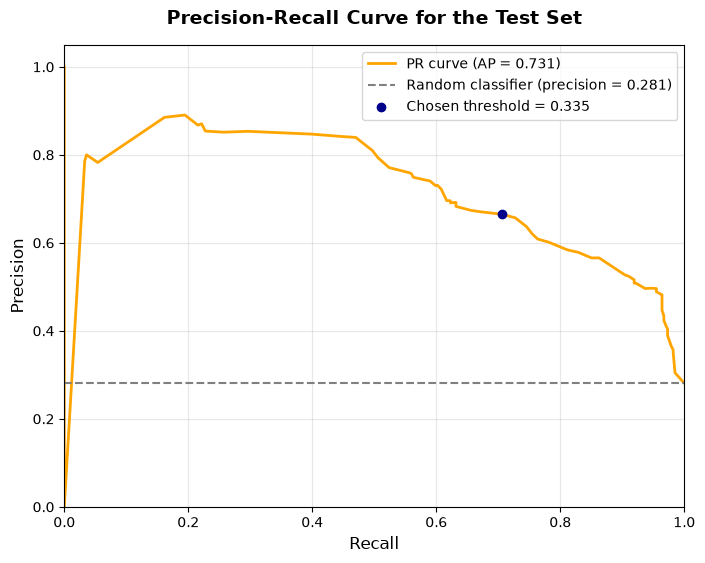

In [113]:
### --- ROC and PR Curve for Decision Tree --- ###
plot_roc(model = best_model_dt, X_set = X_test, y_set = y_test, type_of_set = "Test")
plot_pr(model = best_model_dt, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Decision Tree']['threshold'])

> **Takeaway.** The decision tree can use thresholds and interactions, and is also a **white-box model**: its rules can be read and translated into biological statements. Compared with the logistic regression, it gains 0.07 of test ROC AUC (0.880 against 0.806) and 4.6 points of test accuracy (0.814 against 0.768), so a good part of the signal is non-linear. Its accuracy can still be improved with ensembles, at the price of this readability.

## **10. Random Forest**

A **random forest** is an ensemble of decision trees. Each tree is trained on a bootstrap sample of the data and considers only a random subset of the features at each split, and the final prediction is the **average vote** of all the trees. Averaging many different trees reduces the variance of a single tree and usually gives a more accurate and stable model.

Random forests can overfit too (a default forest memorises the training set), so the search space limits the complexity of the trees:

- **Shallow trees** (`max_depth` from 1 to 7), which stops them from memorising the data. This cap is a **deliberate regularisation choice**: if the selected depth equals 7, the cap is binding and the table says so.
- **Large leaves and splits** (`min_samples_split`, `min_samples_leaf`), which prevent tiny, hyper-specific groups.
- **Feature subsampling** (`max_features`), which adds diversity between the trees.

The search uses 40 random combinations and the common 5-fold protocol.

In [114]:
### --- Best Random Forest --- ###
rf_space = {
    'n_estimators': [50, 100, 200, 300],
    'max_depth': list(range(1, 7)),
    'min_samples_split': [10, 20, 50],
    'min_samples_leaf': [5, 10, 20],
    'max_features': ['sqrt', 'log2', 0.5],
}
rf_rationale = {
    'n_estimators': 'Number of trees. Averaging more trees lowers the variance with diminishing returns; 50 to 300 covers the plateau at a reasonable cost.',
    'max_depth': 'Capped at 6 on purpose: a default forest memorised the training set. Shallow trees act as weak learners, '
                 'which suits averaging. If the chosen value is 6, the cap is binding.',
    'min_samples_split': 'Minimum samples needed to split a node. Larger values force coarser, more stable splits.',
    'min_samples_leaf': 'Minimum samples per leaf. Prevents leaves built on a handful of noisy labels.',
    'max_features': 'Share of features tried at each split (sqrt and log2 of 9 features = 3, 0.5 = 4 or 5). '
                    'Fewer features decorrelate the trees.',
}

best_rf_model = tune_model('Random Forest', RandomForestClassifier(random_state = random_seed, n_jobs = 1),
                           rf_space, rf_rationale, n_iter = BUDGET['n_iter']['Random Forest'])
display(hyperparam_table('Random Forest'))

--- Random Forest: 40 configuration(s) x 5 folds searched on 10,693 rows, selected on ROC AUC; scores below: 5-fold CV on all 10,693 training rows ---
Selected hyperparameters: {'n_estimators': 100, 'min_samples_split': 20, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 6}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.8751,0.9497
Validation (mean of the 5 validation folds),0.8314,0.9283
Validation (sd across the 5 folds),0.0097,0.0042
Test (held-out set),0.8125,0.9201


Random classifier: PR AUC = 0.280  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.366


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.704,0.811,0.754,0.652,0.839
test set,0.695,0.799,0.744,0.637,0.831


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,Random Forest,n_estimators,"[50, 100, 200, 300]",100.0,,Number of trees. Averaging more trees lowers the variance with diminishing returns; 50 to 300 covers the plateau at ...
1,Random Forest,max_depth,"[1, 2, 3, 4, 5, 6]",6.0,at upper cap,"Capped at 6 on purpose: a default forest memorised the training set. Shallow trees act as weak learners, which suits..."
2,Random Forest,min_samples_split,"[10, 20, 50]",20.0,,"Minimum samples needed to split a node. Larger values force coarser, more stable splits."
3,Random Forest,min_samples_leaf,"[5, 10, 20]",5.0,at lower bound,Minimum samples per leaf. Prevents leaves built on a handful of noisy labels.
4,Random Forest,max_features,"['sqrt', 'log2', 0.5]",0.5,,"Share of features tried at each split (sqrt and log2 of 9 features = 3, 0.5 = 4 or 5). Fewer features decorrelate th..."


Compare train and validation in the table above: some overfitting remains even though the search was restricted (accuracy 0.873 / 0.853 / 0.852 and ROC AUC 0.950 / 0.928 / 0.920 on train / validation / test). Validation and test agree closely on accuracy, and the test AUC is slightly lower than the validation AUC, which is within what a 1,189-sample test set can produce. `max_depth = 6` is at its cap and `min_samples_leaf = 5` at its lower bound: these limits are binding by design (see the hyperparameter table). The forest gains about 0.04 of test ROC AUC over the single tree.

### **10.1 Confusion Matrix**

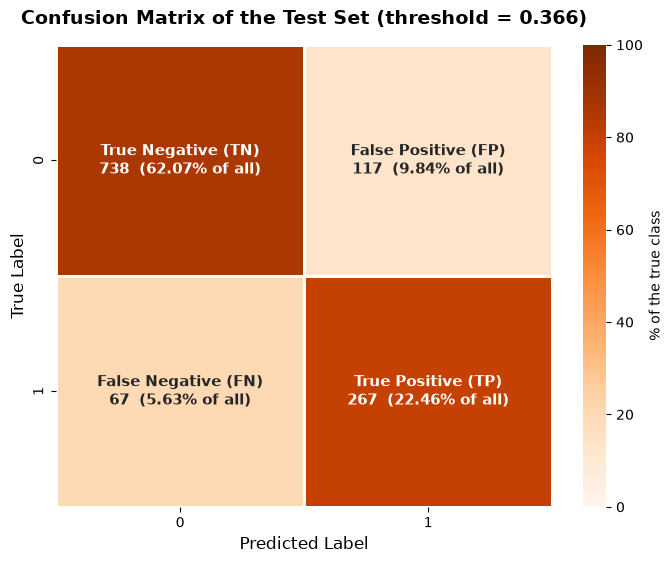

In [115]:
### --- Confusion Matrix for Random Forest --- ###
plot_confusion_matrix(model = best_rf_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Random Forest']['threshold'])

### **10.2 ROC Curve and PR Curve**

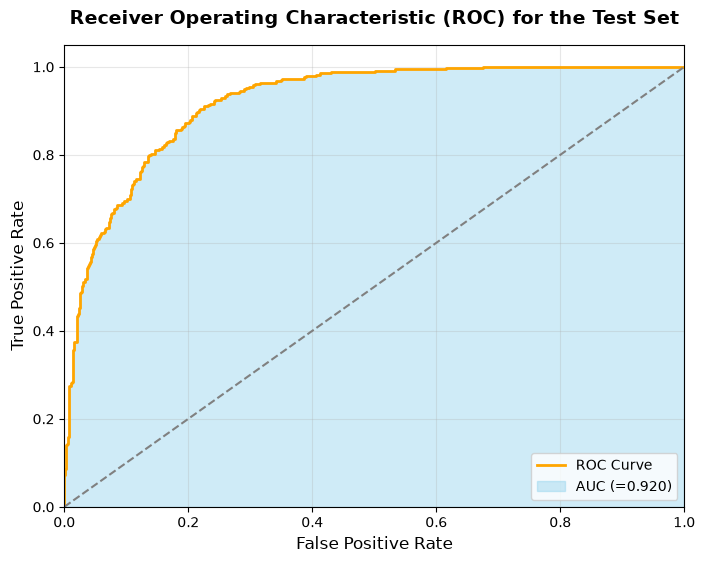

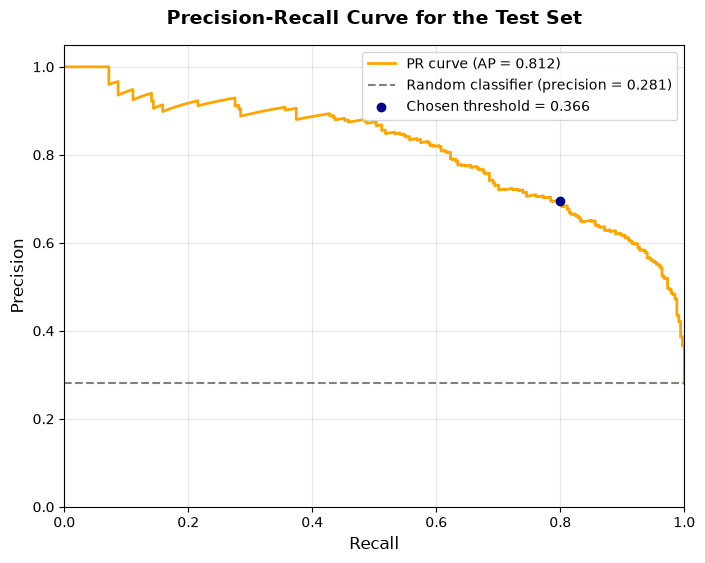

In [116]:
### --- ROC and PR Curve for Random Forest --- ###
plot_roc(model = best_rf_model, X_set = X_test, y_set = y_test, type_of_set = "Test")
plot_pr(model = best_rf_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Random Forest']['threshold'])

### **10.3 Feature Importance**

The plot below ranks the features by their contribution to the splits of the forest. It tells us **which features the model relies on** to classify. Such a plot is reliable here because the features are uncorrelated by design (Section 4.5), and because all of them are numeric (impurity-based importances favour features with many distinct values, which is not an issue when every feature is continuous or counts).

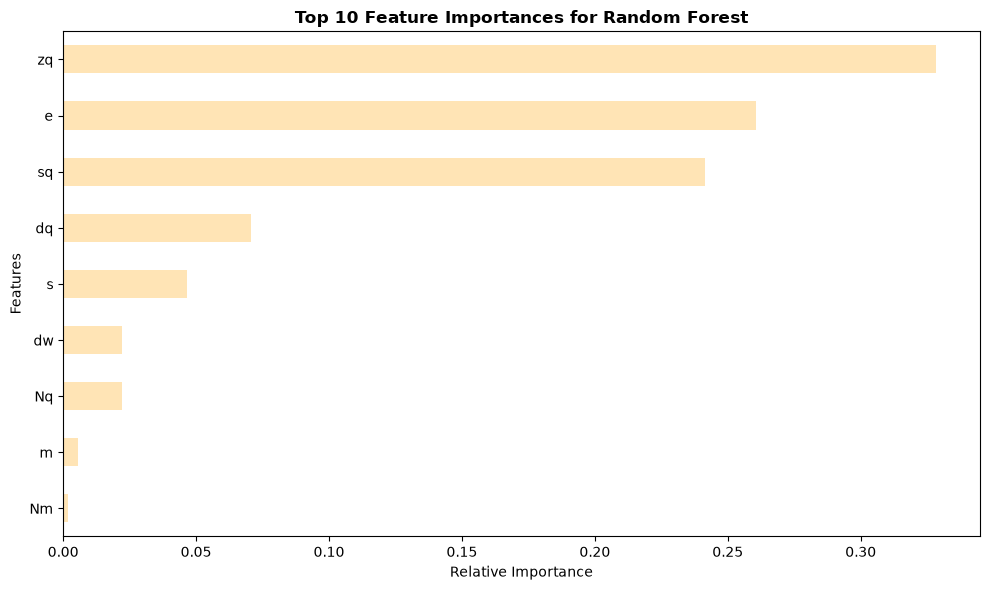

In [117]:
### --- Feature Importance Plot for Random Forest --- ###
feat_imp_plot(model = best_rf_model, feature_names = feature_cols, model_name = 'Random Forest')

> **Takeaway.** The importance plot says *which* features matter, not *how* they act, nor whether they interact. Both questions come back in Section 14.

## **11. XGBoost**

**XGBoost** (eXtreme Gradient Boosting) also builds an ensemble of trees, but in a different way from the random forest. The trees are trained **sequentially**, each one correcting the errors of the previous ones (**gradient boosting**). It often outperforms a random forest on tabular data.

Boosting overfits easily, so the search space contains several regularisation levers: a small learning rate (step-size shrinkage), subsampling of the rows and columns for every tree, a minimum child weight, and L1 (`reg_alpha`) and L2 (`reg_lambda`) penalties. Ranges are deliberately kept in a conservative zone; when a chosen value sits at the edge of its range, the table flags it. The search uses 40 random combinations and the common 5-fold protocol.

In [118]:
### --- Best eXtreme Gradient Boosting --- ###
xgb_space = {
    'n_estimators': [300, 500, 1000],
    'max_depth': list(range(1, 7)),
    'learning_rate': [0.01, 0.02, 0.03],
    'subsample': [0.5, 0.6, 0.7],
    'colsample_bytree': [0.5, 0.6, 0.7],
    'min_child_weight': [10, 11, 12],
    'reg_alpha': list(range(5, 10)),
    'reg_lambda': list(range(5, 10)),
}
xgb_rationale = {
    'n_estimators': 'Number of boosting rounds. With a small learning rate many rounds are needed; 300 to 1000 covers the useful range.',
    'max_depth': 'Depth of each tree = the order of interactions it can capture. Capped at 6 to limit overfitting.',
    'learning_rate': 'Step-size shrinkage. Small values (0.01 to 0.03) make each tree contribute little, which regularises. They need many rounds.',
    'subsample': 'Share of the rows used by each tree (50 to 70%): stochastic boosting, which reduces overfitting.',
    'colsample_bytree': 'Share of the features used by each tree (50 to 70%): decorrelates the trees.',
    'min_child_weight': 'Minimum total weight needed in a leaf. High values (10, 11, 12) forbid leaves built on a few noisy labels.',
    'reg_alpha': 'L1 penalty on the leaf weights (0 = none). Encourages sparse, smaller leaf values.',
    'reg_lambda': 'L2 penalty on the leaf weights (0 = none). Smooths the leaf values.',
}

best_xgb_model = tune_model('XGBoost', XGBClassifier(random_state = random_seed, eval_metric = 'logloss', n_jobs = 1),
                            xgb_space, xgb_rationale, n_iter = BUDGET['n_iter']['XGBoost'])
display(hyperparam_table('XGBoost'))

--- XGBoost: 40 configuration(s) x 5 folds searched on 10,693 rows, selected on ROC AUC; scores below: 5-fold CV on all 10,693 training rows ---
Selected hyperparameters: {'subsample': 0.6, 'reg_lambda': 9, 'reg_alpha': 6, 'n_estimators': 1000, 'min_child_weight': 10, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.9704,0.9877
Validation (mean of the 5 validation folds),0.9173,0.9650
Validation (sd across the 5 folds),0.0069,0.0026
Test (held-out set),0.9092,0.9625


Random classifier: PR AUC = 0.280  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.383


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.804,0.866,0.834,0.766,0.892
test set,0.801,0.868,0.833,0.766,0.892


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,XGBoost,n_estimators,"[300, 500, 1000]",1000.00,at upper cap,Number of boosting rounds. With a small learning rate many rounds are needed; 300 to 1000 covers the useful range.
1,XGBoost,max_depth,"[1, 2, 3, 4, 5, 6]",6.00,at upper cap,Depth of each tree = the order of interactions it can capture. Capped at 6 to limit overfitting.
2,XGBoost,learning_rate,"[0.01, 0.02, 0.03]",0.03,at upper cap,"Step-size shrinkage. Small values (0.01 to 0.03) make each tree contribute little, which regularises. They need many..."
3,XGBoost,subsample,"[0.5, 0.6, 0.7]",0.60,,"Share of the rows used by each tree (50 to 70%): stochastic boosting, which reduces overfitting."
4,XGBoost,colsample_bytree,"[0.5, 0.6, 0.7]",0.70,at upper cap,Share of the features used by each tree (50 to 70%): decorrelates the trees.
5,XGBoost,min_child_weight,"[10, 11, 12]",10.00,at lower bound,"Minimum total weight needed in a leaf. High values (10, 11, 12) forbid leaves built on a few noisy labels."
6,XGBoost,reg_alpha,"[5, 6, 7, 8, 9]",6.00,,"L1 penalty on the leaf weights (0 = none). Encourages sparse, smaller leaf values."
7,XGBoost,reg_lambda,"[5, 6, 7, 8, 9]",9.00,at upper cap,L2 penalty on the leaf weights (0 = none). Smooths the leaf values.


**Reading the results.** XGBoost reaches a validation ROC AUC of 0.965 (accuracy 0.905) and a test ROC AUC of 0.963 (accuracy 0.898), a clear step above the random forest (0.928 and 0.920). Validation and test agree and the standard deviation across folds is small (0.003), so the model is stable. The training scores are higher (ROC AUC 0.988, accuracy 0.949), so some overfitting remains despite the regularisation. Several hyperparameters sit at the edge of their range (`n_estimators`, `max_depth`, `learning_rate`, `colsample_bytree` and `reg_lambda` at the upper cap, `min_child_weight` at the lower bound). The ranges were kept narrow on purpose, so these caps are binding by design.

### **11.1 Confusion Matrix**

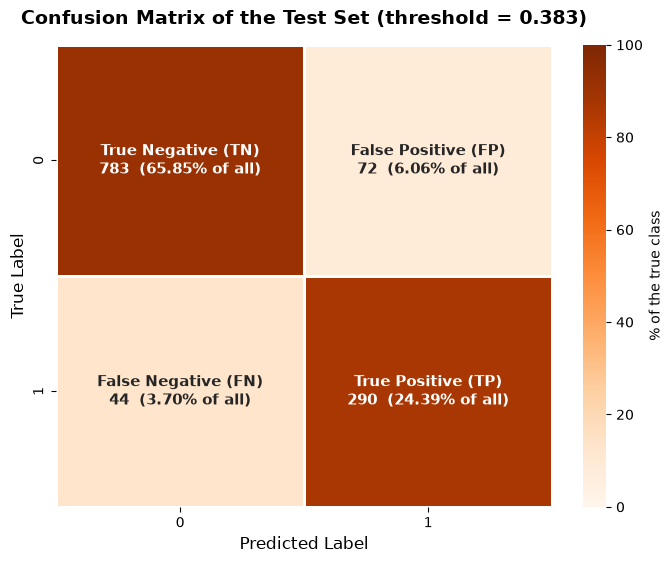

In [119]:
### --- Confusion Matrix for XGBoost --- ###
plot_confusion_matrix(model = best_xgb_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['XGBoost']['threshold'])

### **11.2 ROC Curve and PR Curve**

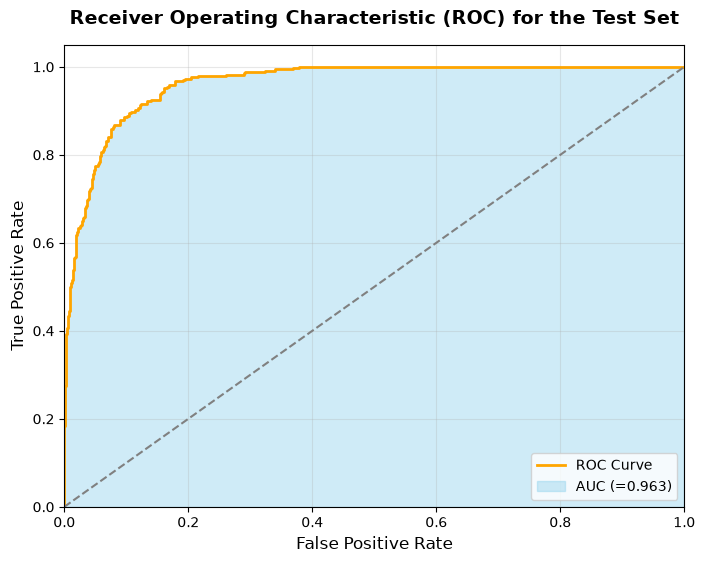

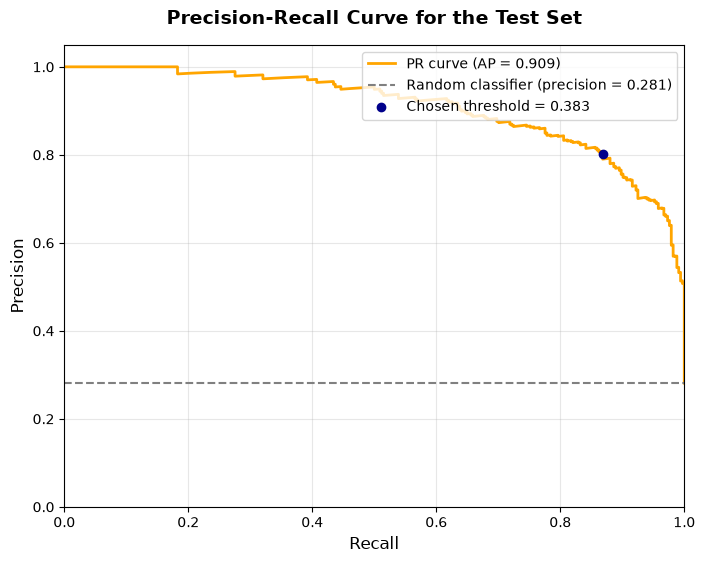

In [120]:
### --- ROC and PR Curve for XGBoost --- ###
plot_roc(model = best_xgb_model, X_set = X_test, y_set = y_test, type_of_set = "Test")
plot_pr(model = best_xgb_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['XGBoost']['threshold'])

### **11.3 Feature Importance**

As for the random forest, the features are uncorrelated, so this ranking is reliable. It is the importance used by XGBoost itself (how much each feature contributes to the splits); Section 14 gives importances that also tell the *direction* of each effect.

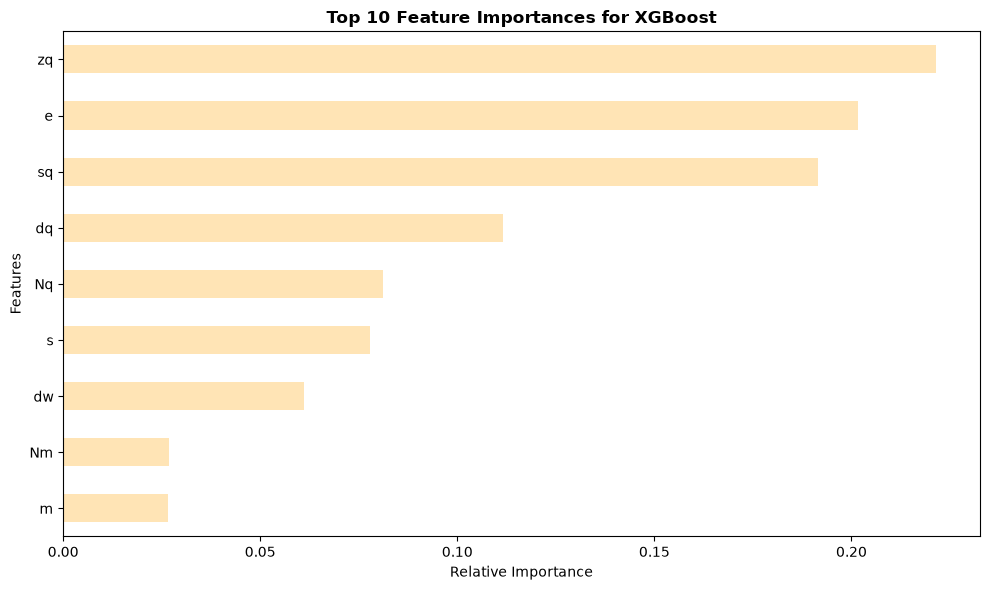

In [121]:
### --- Feature Importance Plot for XGBoost --- ###
feat_imp_plot(model = best_xgb_model, feature_names = feature_cols, model_name = 'XGBoost')

## **12. Multilayer Perceptron**

As a last model, we train a **multilayer perceptron** (MLP), a feed-forward neural network. It can represent very flexible non-linear relationships, but it needs more data than tree ensembles to shine and is the hardest to interpret.

 Overfitting is controlled by **early stopping** (10% of every training fold is held out internally, training stops after 20 epochs without improvement) and by the L2 penalty being part of the search. Only the **Adam** optimiser is used: plain SGD needs its momentum and learning-rate schedule tuned and was unstable under early stopping. Features are min-max scaled inside a `Pipeline`. The search uses 50 random combinations and the common 5-fold protocol.

> **Note.** Some candidates in a randomised search may not converge within `max_iter`. These candidates simply obtain a low validation score and are not selected, so the `ConvergenceWarning` messages that may appear are expected. A large **standard deviation across folds** in the table below would reveal an unstable network.

In [122]:
### --- Best Multilayer Perceptron --- ###
mlp_pipeline = Pipeline([
    ('scale', MinMaxScaler()),
    ('clf', MLPClassifier(solver = 'adam', early_stopping = True, validation_fraction = 0.1,
                          n_iter_no_change = 20, random_state = random_seed)),
])
mlp_space = {
    'clf__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64), (128, 128), (64, 64, 32)],
    'clf__activation': ['relu', 'tanh'],
    'clf__alpha': [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    'clf__learning_rate_init': [1e-4, 1e-3, 3e-3, 1e-2, 3e-2],
    'clf__batch_size': [64, 128, 256],
    'clf__max_iter': [500, 1000],
}
mlp_rationale = {
    'hidden_layer_sizes': 'Architecture, from one layer of 32 neurons to three layers (128, 128 or 64, 64, 32). '
                          'Wide enough to model interactions between nine inputs without hand-limiting the capacity.',
    'activation': 'ReLU (default, fast) versus tanh (smooth, often better on small tabular data).',
    'alpha': 'L2 penalty on the weights, on a log scale from almost none (1e-6) to strong (0.1). Controls overfitting together with early stopping.',
    'learning_rate_init': 'Initial step of Adam, on a log-like scale. Too small learns slowly, too large is unstable.',
    'batch_size': 'Mini-batch size. Smaller batches add noise that can help generalisation; larger ones are more stable.',
    'max_iter': 'Maximum number of epochs. Early stopping normally ends training before this limit.',
}

best_mlp_model = tune_model('Multilayer Perceptron', mlp_pipeline, mlp_space, mlp_rationale, n_iter = BUDGET['n_iter']['Multilayer Perceptron'])
display(hyperparam_table('Multilayer Perceptron'))

--- Multilayer Perceptron: 50 configuration(s) x 5 folds searched on 10,693 rows, selected on ROC AUC; scores below: 5-fold CV on all 10,693 training rows ---
Selected hyperparameters: {'max_iter': 1000, 'learning_rate_init': 0.003, 'hidden_layer_sizes': (128, 128), 'batch_size': 64, 'alpha': 0.0001, 'activation': 'relu'}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.9590,0.9818
Validation (mean of the 5 validation folds),0.9267,0.9666
Validation (sd across the 5 folds),0.0074,0.0024
Test (held-out set),0.9179,0.9594


Random classifier: PR AUC = 0.280  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.488


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.845,0.843,0.844,0.783,0.891
test set,0.812,0.853,0.832,0.765,0.888


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,Multilayer Perceptron,hidden_layer_sizes,"[(32,), (64,), (128,), (64, 32), (128, 64), (128, 128), (64, 64, 32)]","(128, 128)",,"Architecture, from one layer of 32 neurons to three layers (128, 128 or 64, 64, 32). Wide enough to model interactio..."
1,Multilayer Perceptron,activation,"['relu', 'tanh']",relu,,"ReLU (default, fast) versus tanh (smooth, often better on small tabular data)."
2,Multilayer Perceptron,alpha,"[1e-06, 1e-05, 0.0001, 0.001, 0.01, 0.1]",0.0001,,"L2 penalty on the weights, on a log scale from almost none (1e-6) to strong (0.1). Controls overfitting together wit..."
3,Multilayer Perceptron,learning_rate_init,"[0.0001, 0.001, 0.003, 0.01, 0.03]",0.003,,"Initial step of Adam, on a log-like scale. Too small learns slowly, too large is unstable."
4,Multilayer Perceptron,batch_size,"[64, 128, 256]",64,at lower bound,Mini-batch size. Smaller batches add noise that can help generalisation; larger ones are more stable.
5,Multilayer Perceptron,max_iter,"[500, 1000]",1000,at upper cap,Maximum number of epochs. Early stopping normally ends training before this limit.


**Reading the results.** The selected network has two hidden layers of 128 neurons (ReLU activation). Its validation ROC AUC is 0.967 (accuracy 0.912), nominally the best of all models on the validation folds, and its test ROC AUC is 0.959 (accuracy 0.903), level with XGBoost (Section 13.4 tests the difference). The train-validation gap is similar to that of XGBoost (ROC AUC 0.982 against 0.967) and the standard deviation across folds is small (0.002), so the network is stable. The configuration with the best validation accuracy is a slightly different one (two layers of 128 and 64 neurons, `alpha = 0.01`), but its accuracy (0.9119) is the same as the selected one (0.9117). `batch_size = 64` is at the lower bound and `max_iter = 1000` at the upper cap of their ranges.

### **12.1 Confusion Matrix**

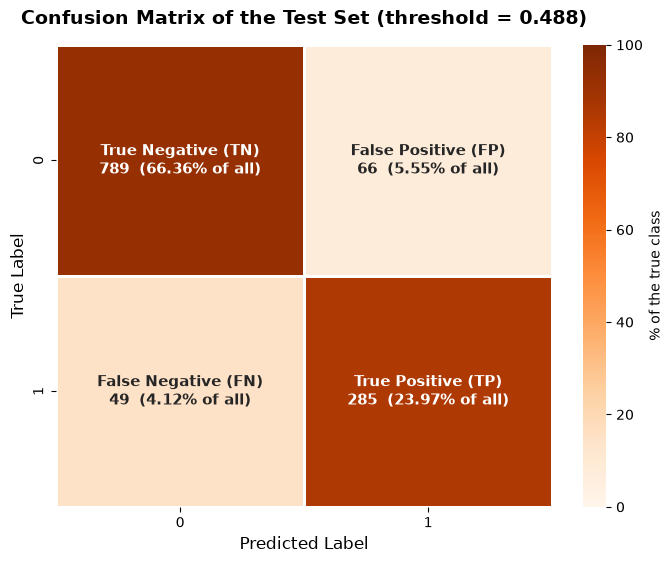

In [123]:
### --- Confusion Matrix for Multilayer Perceptron --- ###
plot_confusion_matrix(model = best_mlp_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Multilayer Perceptron']['threshold'])

### **12.2 ROC Curve and PR Curve**

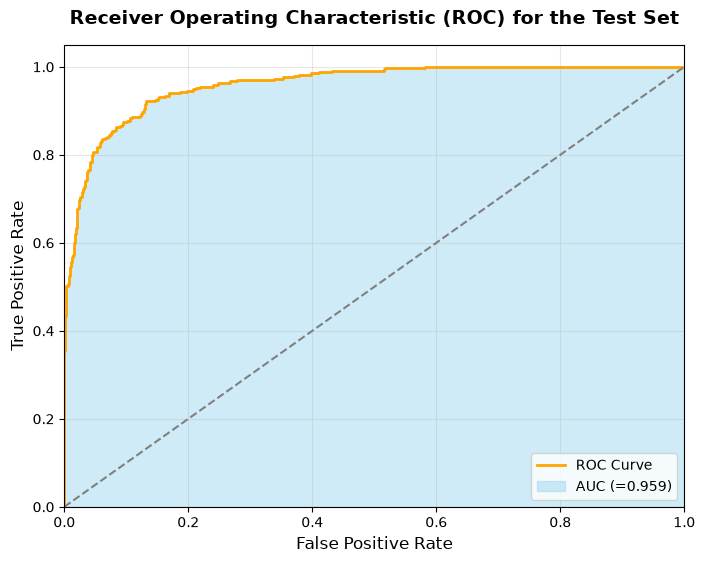

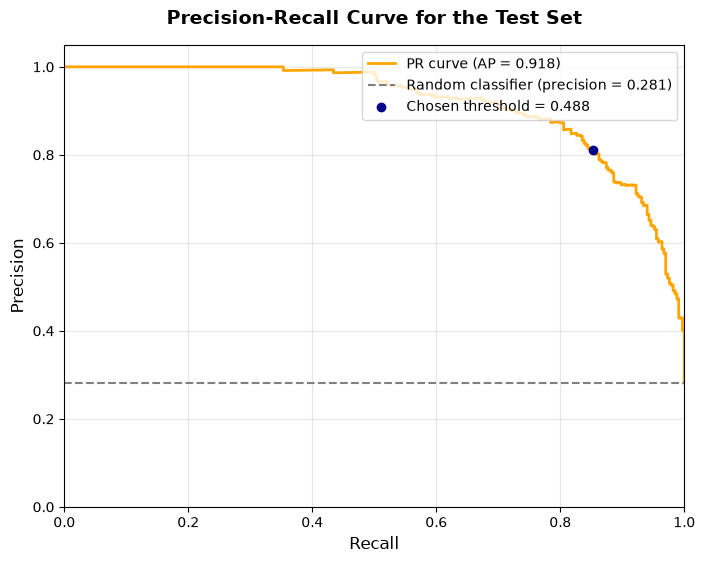

In [124]:
### --- ROC and PR Curve for Multilayer Perceptron --- ###
plot_roc(model = best_mlp_model, X_set = X_test, y_set = y_test, type_of_set = "Test")
plot_pr(model = best_mlp_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Multilayer Perceptron']['threshold'])

### **12.3 Permutation Importance**

An MLP has no built-in feature importance. **Permutation importance** provides an equivalent: each feature is shuffled in turn on the test set, and the **drop in ROC AUC** measures how much the model relied on it. The model is a `Pipeline`, so the shuffling happens on the raw features, before the scaler.

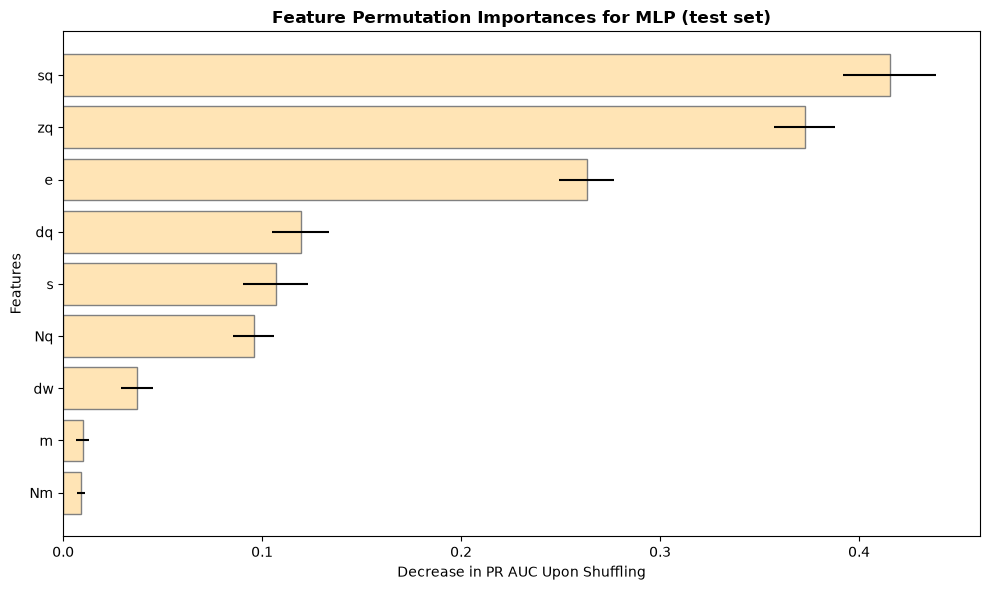

In [125]:
### --- Feature Permutation Importance Plot for Multilayer Perceptron --- ###
perm = permutation_importance(
    best_mlp_model, X_test, y_test,
    scoring = 'average_precision', n_repeats = BUDGET['perm_repeats_mlp'], random_state = random_seed, n_jobs = -1)

perm_importances = pd.Series(perm.importances_mean, index = feature_cols)
perm_sd = pd.Series(perm.importances_std, index = feature_cols)
order = perm_importances.sort_values().index
plt.figure(figsize = (10, 6))
plt.barh(order, perm_importances[order], xerr = perm_sd[order], color = 'moccasin', edgecolor = 'gray')
plt.title('Feature Permutation Importances for MLP (test set)', fontweight = 'bold')
plt.xlabel('Decrease in PR AUC Upon Shuffling')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## **13. Model Comparison and Diagnostics**

### **13.1 Table 1: Hyperparameter Search and Chosen Values**

The table collects, for every model, the searched values, the chosen value, whether it sits at the edge of the range, and the reason for the range. It is also saved as `table1_hyperparameters.csv`, ready to be turned into the hyperparameter table of the report.

In [126]:
### --- Table 1: Hyperparameters of All the Models --- ###
table1 = pd.concat([hyperparam_table(n) for n in RESULTS], ignore_index = True)
table1.to_csv('table1_hyperparameters.csv', index = False)
pd.set_option('display.max_colwidth', 120)
display(table1)

,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,Logistic Regression,C,"[0.001, 0.01, 0.1, 1.0, 10.0, 100.0]",100.0,at upper cap,"Inverse regularisation strength, on a log scale. 0.001 = very strong L2 shrinkage (underfitting risk), 100 = almost ..."
1,Decision Tree,max_depth,1 to 9 (9 values),9,at upper cap,"Main complexity control: a tree of depth d can encode interactions of up to d features. 1 is a single split, 10 is d..."
2,Decision Tree,min_samples_leaf,5 to 19 (15 values),12,,"Forbids leaves built on a handful of rows. Each label comes from only 100 replicates, so tiny leaves would fit noise..."
3,Decision Tree,max_features,"[None, 'sqrt', 'log2']",sqrt,,"Number of features examined at each split: all (None), sqrt or log2 of the number of features. Fewer features add ra..."
4,Decision Tree,criterion,"['gini', 'entropy']",entropy,,"Impurity measure for the splits. Gini and entropy usually give similar trees, both are tried."
5,Decision Tree,ccp_alpha,0.0 to 0.01 (7 values),0.001,,"Cost-complexity pruning strength, from 0 (no pruning) to 0.01 (aggressive). Pruning removes branches that add little..."
6,Random Forest,n_estimators,"[50, 100, 200, 300]",100.0,,Number of trees. Averaging more trees lowers the variance with diminishing returns; 50 to 300 covers the plateau at ...
7,Random Forest,max_depth,"[1, 2, 3, 4, 5, 6]",6.0,at upper cap,"Capped at 6 on purpose: a default forest memorised the training set. Shallow trees act as weak learners, which suits..."
8,Random Forest,min_samples_split,"[10, 20, 50]",20.0,,"Minimum samples needed to split a node. Larger values force coarser, more stable splits."
9,Random Forest,min_samples_leaf,"[5, 10, 20]",5.0,at lower bound,Minimum samples per leaf. Prevents leaves built on a handful of noisy labels.


### **13.2 Table 2: Performance on Train, Validation and Test Sets**

Two metrics are reported for every model: **PR AUC** and **ROC AUC**. *Train* is the mean over the five training folds, *Validation* the mean over the five validation folds (with its standard deviation across folds), and *Test* the score on the held-out test set. The table is saved as `table2_metrics.csv`.

In [127]:
### --- Table 2: Metrics of All the Models --- ###
columns = pd.MultiIndex.from_tuples([(lab, part) for lab in ('PR AUC', 'ROC AUC') for part in ('Train', 'Validation', 'Val. sd', 'Test')])
table2 = pd.DataFrame(
    [[RESULTS[n]['metrics'][metric][k] for metric in ('pr_auc', 'roc_auc') for k in ('train', 'val', 'val_sd', 'test')] for n in RESULTS],
    index = list(RESULTS), columns = columns)
table2.index.name = 'Model'
table2.round(4).to_csv('table2_metrics.csv')
display(table2.round(3))
print(f'Random classifier: PR AUC = {prevalence_train:.3f}  |  ROC AUC = 0.500')

ref_name = max(RESULTS, key = lambda n: RESULTS[n]['metrics'][PRIMARY_METRIC]['val'])
print(f'Best model on the validation {METRIC_LABEL[PRIMARY_METRIC]}: {ref_name}')

### --- Table 3: Threshold-Based Metrics on the Test Set --- ###
table3 = pd.DataFrame({n: {'threshold (F1-optimal, out-of-fold)': r['threshold'], **r['thr_test']} for n, r in RESULTS.items()}).T
table3.index.name = 'Model'
table3.round(4).to_csv('table3_threshold_metrics.csv')
display(table3.round(3))
print('The always-negative classifier has recall 0, precision undefined (0 by convention), F1 = 0, MCC = 0 and balanced accuracy 0.5.')

PR AUC                           ROC AUC             \
                       Train Validation Val. sd   Test   Train Validation   
Model                                                                       
Logistic Regression    0.573      0.574   0.025  0.584   0.807      0.806   
Decision Tree          0.809      0.722   0.022  0.731   0.923      0.879   
Random Forest          0.875      0.831   0.010  0.812   0.950      0.928   
XGBoost                0.970      0.917   0.007  0.909   0.988      0.965   
Multilayer Perceptron  0.959      0.927   0.007  0.918   0.982      0.967   

                                      
                      Val. sd   Test  
Model                                 
Logistic Regression     0.011  0.806  
Decision Tree           0.013  0.880  
Random Forest           0.004  0.920  
XGBoost                 0.003  0.963  
Multilayer Perceptron   0.002  0.959

Random classifier: PR AUC = 0.280  |  ROC AUC = 0.500
Best model on the validation ROC AUC: Multilayer Perceptron


,"threshold (F1-optimal, out-of-fold)",precision,recall,F1,MCC,balanced accuracy
Model,,,,,,
Logistic Regression,0.313,0.541,0.686,0.605,0.431,0.729
Decision Tree,0.335,0.665,0.707,0.685,0.557,0.784
Random Forest,0.366,0.695,0.799,0.744,0.637,0.831
XGBoost,0.383,0.801,0.868,0.833,0.766,0.892
Multilayer Perceptron,0.488,0.812,0.853,0.832,0.765,0.888


The always-negative classifier has recall 0, precision undefined (0 by convention), F1 = 0, MCC = 0 and balanced accuracy 0.5.


### **13.3 ROC Curves and PR AUC of All the Models**

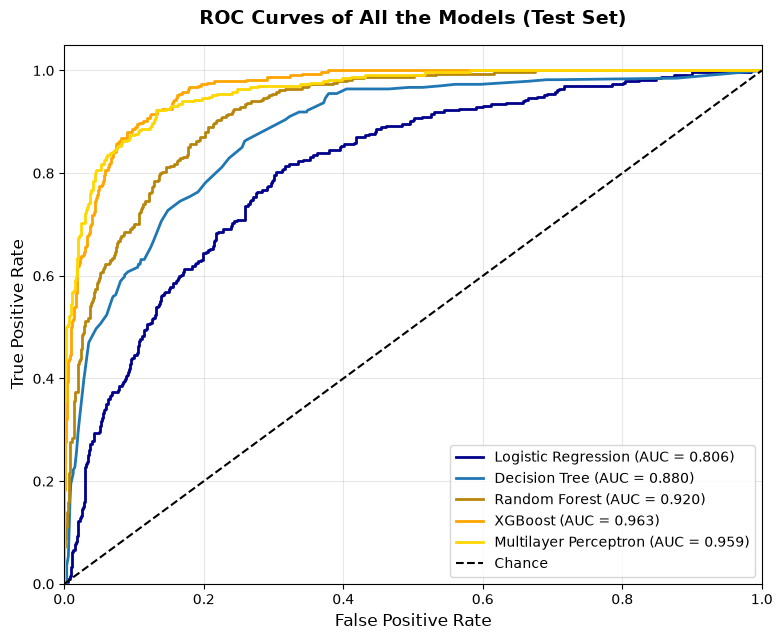

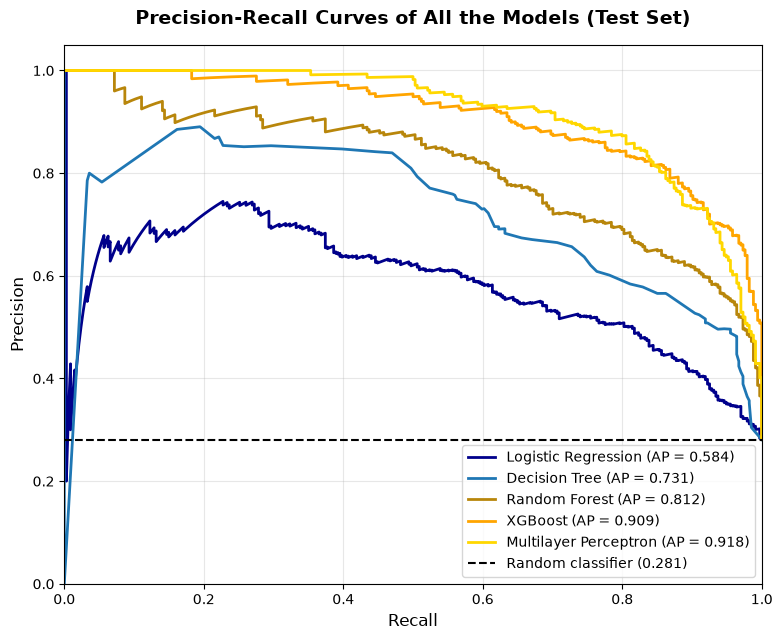

In [156]:
### --- Combined ROC and PR Curves of All the Models --- ###
colors = ['darkblue', 'tab:blue', 'darkgoldenrod', 'orange', 'gold']
test_proba = {n: r['model'].predict_proba(X_test)[:, 1] for n, r in RESULTS.items()}

plt.figure(figsize = (9, 7))
for (name, proba), color in zip(test_proba.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, color = color, lw = 2, label = f'{name} (AUC = {roc_auc_score(y_test, proba):.3f})')

plt.plot([0, 1], [0, 1], color = 'black', linestyle = '--', label = 'Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.title('ROC Curves of All the Models (Test Set)', fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel('False Positive Rate', fontsize = 12)
plt.ylabel('True Positive Rate', fontsize = 12)
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.3)
plt.show()

### --- Combined Precision-Recall Curves of All the Models --- ###
plt.figure(figsize = (9, 7))
for (name, proba), color in zip(test_proba.items(), colors):
    precision, recall, _ = precision_recall_curve(y_test, proba)
    plt.plot(recall, precision, color = color, lw = 2, label = f'{name} (AP = {average_precision_score(y_test, proba):.3f})')
plt.axhline(y_test.mean(), color = 'black', linestyle = '--', label = f'Random classifier ({y_test.mean():.3f})')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.title('Precision-Recall Curves of All the Models (Test Set)', fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel('Recall', fontsize = 12)
plt.ylabel('Precision', fontsize = 12)
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.3)
plt.show()

### **13.4 How Much Do the Differences Matter? Bootstrap Confidence Intervals**

A single test set gives a single, noisy number. We resample the test set 1,000 times (with replacement) to obtain **95% confidence intervals** for the test accuracy and the test ROC AUC, and, for the AUC, the interval of the **paired difference** with the model that is best on the validation folds. If the interval of a difference contains 0, the test set cannot tell the two models apart.

In [129]:
### --- Bootstrap Confidence Intervals on the Test Set --- ###
rng = np.random.default_rng(random_seed)
y_test_arr = y_test.to_numpy()
n_boot = BUDGET['n_boot']
boot_idx = rng.integers(0, len(y_test_arr), size = (n_boot, len(y_test_arr)))

boot = {n: {k: np.empty(n_boot) for k in ('pr_auc', 'roc_auc', 'f1')} for n in RESULTS}
for b in range(n_boot):
    y_b = y_test_arr[boot_idx[b]]
    for n, proba in test_proba.items():
        p_b = proba[boot_idx[b]]
        boot[n]['pr_auc'][b] = average_precision_score(y_b, p_b)
        boot[n]['roc_auc'][b] = roc_auc_score(y_b, p_b)
        boot[n]['f1'][b] = f1_score(y_b, (p_b >= RESULTS[n]['threshold']).astype(int))

def fmt_ci(point, draws):
    low, high = np.percentile(draws, [2.5, 97.5])
    return f'{point:.3f} [{low:.3f}, {high:.3f}]'

def fmt_diff(n, metric):
    """Paired bootstrap difference between a model and the reference model (same resamples), with its 95% interval."""
    if n == ref_name:
        return '-'
    diff = boot[n][metric] - boot[ref_name][metric]
    return f'{np.mean(diff):+.3f} [{np.percentile(diff, 2.5):+.3f}, {np.percentile(diff, 97.5):+.3f}]'

rows = []
for n in RESULTS:
    rows.append({
        'Model': n,
        'Test ROC AUC [95% CI]': fmt_ci(RESULTS[n]['metrics']['roc_auc']['test'], boot[n]['roc_auc']),
        'Test PR AUC [95% CI]': fmt_ci(RESULTS[n]['metrics']['pr_auc']['test'], boot[n]['pr_auc']),
        'Test F1 [95% CI]': fmt_ci(RESULTS[n]['thr_test']['F1'], boot[n]['f1']),
        f'ROC AUC difference vs {ref_name} [95% CI]': fmt_diff(n, 'roc_auc'),
        f'PR AUC difference vs {ref_name} [95% CI]': fmt_diff(n, 'pr_auc'),
    })
display(pd.DataFrame(rows).set_index('Model'))

,Test ROC AUC [95% CI],Test PR AUC [95% CI],Test F1 [95% CI],ROC AUC difference vs Multilayer Perceptron [95% CI],PR AUC difference vs Multilayer Perceptron [95% CI]
Model,,,,,
Logistic Regression,"0.806 [0.779, 0.830]","0.584 [0.530, 0.640]","0.605 [0.565, 0.642]","-0.154 [-0.178, -0.130]","-0.331 [-0.378, -0.282]"
Decision Tree,"0.880 [0.858, 0.899]","0.731 [0.677, 0.783]","0.685 [0.643, 0.724]","-0.080 [-0.100, -0.061]","-0.185 [-0.231, -0.140]"
Random Forest,"0.920 [0.903, 0.935]","0.812 [0.769, 0.851]","0.744 [0.708, 0.778]","-0.039 [-0.051, -0.028]","-0.105 [-0.138, -0.074]"
XGBoost,"0.963 [0.953, 0.971]","0.909 [0.881, 0.932]","0.833 [0.800, 0.864]","+0.003 [-0.003, +0.010]","-0.009 [-0.025, +0.007]"
Multilayer Perceptron,"0.959 [0.948, 0.970]","0.918 [0.896, 0.938]","0.832 [0.802, 0.862]",-,-


### **13.5 Are the Predicted Probabilities Real Probabilities? Calibration**

Because the data was **not rebalanced**, the predicted probabilities should match observed frequencies: among parameter sets with a predicted probability near 0.3, about 30% should be polymorphic. The reliability diagram compares predicted and observed frequencies in ten bins of equal size. The Brier score and the log loss summarise the quality of the probabilities (lower is better).

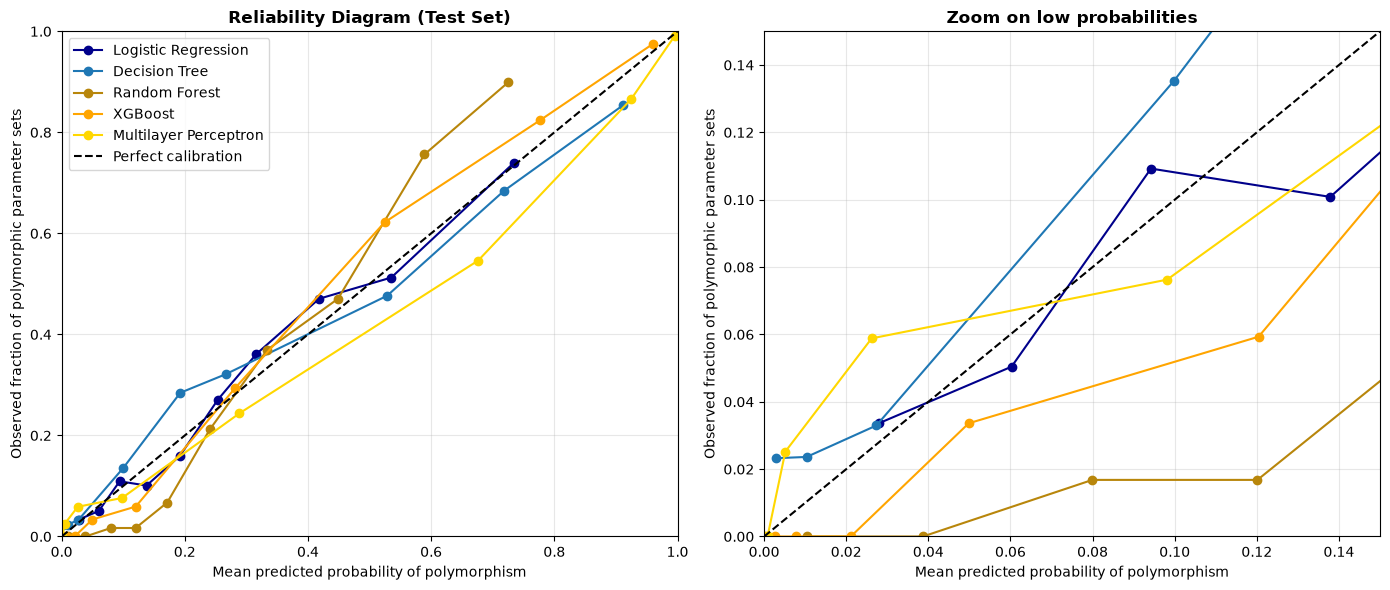

,Brier score,Log loss
Model,,
Logistic Regression,0.1542,0.4719
Decision Tree,0.1239,0.6009
Random Forest,0.1101,0.3519
XGBoost,0.0707,0.2271
Multilayer Perceptron,0.0706,0.2337
Constant prediction (prevalence),0.2020,0.5938


In [130]:
### --- Calibration (Reliability) Diagram and Probability Scores --- ###
fig, axes = plt.subplots(1, 2, figsize = (14, 6))
calib_rows = []
for (name, proba), color in zip(test_proba.items(), colors):
    frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins = 10, strategy = 'quantile')
    for ax in axes:
        ax.plot(mean_pred, frac_pos, marker = 'o', color = color, label = name)
    calib_rows.append({'Model': name, 'Brier score': brier_score_loss(y_test, proba), 'Log loss': log_loss(y_test, proba)})
for ax, limit in zip(axes, [1.0, 0.15]):
    ax.plot([0, limit], [0, limit], 'k--', label = 'Perfect calibration')
    ax.set_xlim(0, limit); ax.set_ylim(0, limit)
    ax.set_xlabel('Mean predicted probability of polymorphism')
    ax.set_ylabel('Observed fraction of polymorphic parameter sets')
    ax.grid(alpha = 0.3)
axes[0].set_title('Reliability Diagram (Test Set)', fontweight = 'bold')
axes[1].set_title('Zoom on low probabilities', fontweight = 'bold')
axes[0].legend(loc = 'upper left')
plt.tight_layout()
plt.show()

base_p = np.full(len(y_test), y_train.mean())
calib_rows.append({'Model': 'Constant prediction (prevalence)', 'Brier score': brier_score_loss(y_test, base_p), 'Log loss': log_loss(y_test, base_p)})
display(pd.DataFrame(calib_rows).set_index('Model').round(4))

### **13.6 Where Does the Best Model Make Errors? Label Noise**

If part of the errors comes from label noise (Section 6.5), the error rate should be highest for parameter sets whose `frac_polymorphic` is small but non-zero: those are the ones that are more likely to be positive only by chance. The table groups the test samples by `frac_polymorphic` and reports the error rate of XGBoost in each group.

,n,error_rate,mean_predicted_probability
group,,,
"(0, 0.05]",174,0.241,0.589
"(0.05, 0.2]",94,0.000,0.850
"(0.2, 0.5]",44,0.045,0.845
"(0.5, 1]",22,0.000,0.870
0 (not polymorphic),855,0.084,0.103


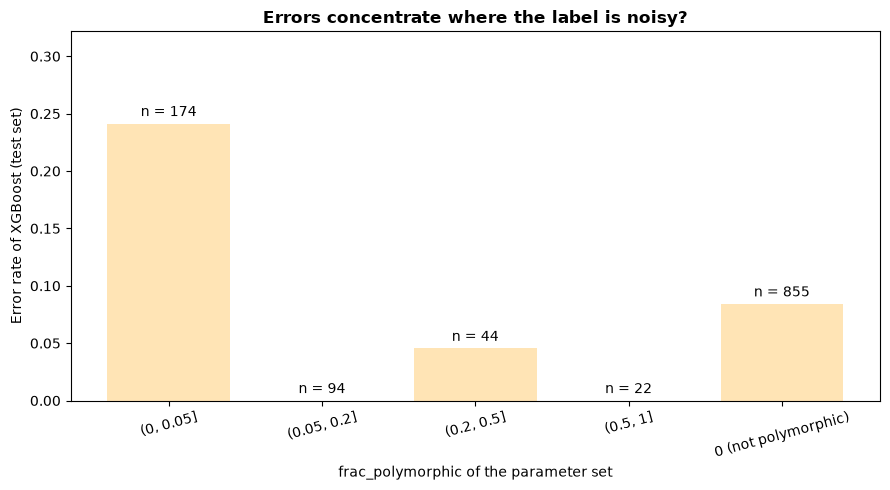

In [131]:
### --- Error Rate of XGBoost as a Function of frac_polymorphic --- ###
xgb_model = RESULTS['XGBoost']['model']
p_xgb = xgb_model.predict_proba(X_test)[:, 1]
frac_test = df_model.loc[X_test.index, 'frac_polymorphic']      # Exact look-up: the row index of df_model is unique (Section 3).
assert ((frac_test > POLYMORPH_THRESHOLD).astype(int).to_numpy() == y_test.to_numpy()).all()   # Same rows, same labels as y_test.

bins = [-0.001, 0.0, 0.05, 0.2, 0.5, 1.0]
labels = ['0 (not polymorphic)', '(0, 0.05]', '(0.05, 0.2]', '(0.2, 0.5]', '(0.5, 1]']
err_df = pd.DataFrame({
    'group': pd.cut(frac_test, bins = bins, labels = labels).to_numpy(),
    'error': ((p_xgb >= RESULTS['XGBoost']['threshold']).astype(int) != y_test.to_numpy()).astype(int),
    'p': p_xgb,
})
err_table = err_df.groupby('group', observed = True).agg(
    n = ('error', 'size'), error_rate = ('error', 'mean'), mean_predicted_probability = ('p', 'mean'))
display(err_table.round(3))

plt.figure(figsize = (9, 5))
bars = plt.bar(err_table.index.astype(str), err_table['error_rate'], color = 'moccasin')
plt.bar_label(bars, labels = [f'n = {n}' for n in err_table['n']], padding = 3)
plt.ylabel('Error rate of XGBoost (test set)')
plt.xlabel('frac_polymorphic of the parameter set')
plt.title('Errors concentrate where the label is noisy?', fontweight = 'bold')
plt.xticks(rotation = 15)
plt.ylim(0, min(1.0, err_table['error_rate'].max() * 1.25 + 0.02))
plt.tight_layout()
plt.show()

### **13.7 Does the Definition of "Polymorphic" Matter? Threshold Sensitivity**

The same XGBoost configuration (hyperparameters **not** re-tuned) is trained with stricter definitions of the positive class. If the performance rises with the threshold, part of the error of the original task was due to label noise near the boundary. Accuracy values must be read against the majority-class baseline of each row, since the class balance changes with the threshold.

In [132]:
### --- Threshold Sensitivity of the Polymorphic Label --- ###
sens_rows = []
for thr in [0.0, 0.01, 0.05, 0.10, 0.25]:
    y_tr_thr = (df_model.loc[X_train.index, 'frac_polymorphic'] > thr).astype(int)
    y_te_thr = (df_model.loc[X_test.index, 'frac_polymorphic'] > thr).astype(int)
    
    model_thr = clone(xgb_model).fit(X_train, y_tr_thr)
    proba_thr = model_thr.predict_proba(X_test)[:, 1]
    
    sens_rows.append({
        'threshold': thr,
        'share polymorphic (test)': y_te_thr.mean(),
        'test PR AUC': average_precision_score(y_te_thr, proba_thr),
        'PR AUC / share (lift over random)': average_precision_score(y_te_thr, proba_thr) / y_te_thr.mean(),
        'test ROC AUC': roc_auc_score(y_te_thr, proba_thr),
    })

display(pd.DataFrame(sens_rows).set_index('threshold').round(3))

,share polymorphic (test),test PR AUC,PR AUC / share (lift over random),test ROC AUC
threshold,,,,
0.00,0.281,0.909,3.237,0.963
0.01,0.225,0.890,3.961,0.962
0.05,0.135,0.875,6.504,0.976
0.10,0.094,0.820,8.702,0.976
0.25,0.046,0.716,15.487,0.974


### **13.8 Would More Simulations Help? Learning Curve**

Each parameter set is expensive to simulate. The learning curve trains XGBoost on increasing fractions of the training set and shows the validation ROC AUC (5-fold CV). If the validation curve has flattened, more simulations of the same kind would add little. If it is still rising, more data would help.

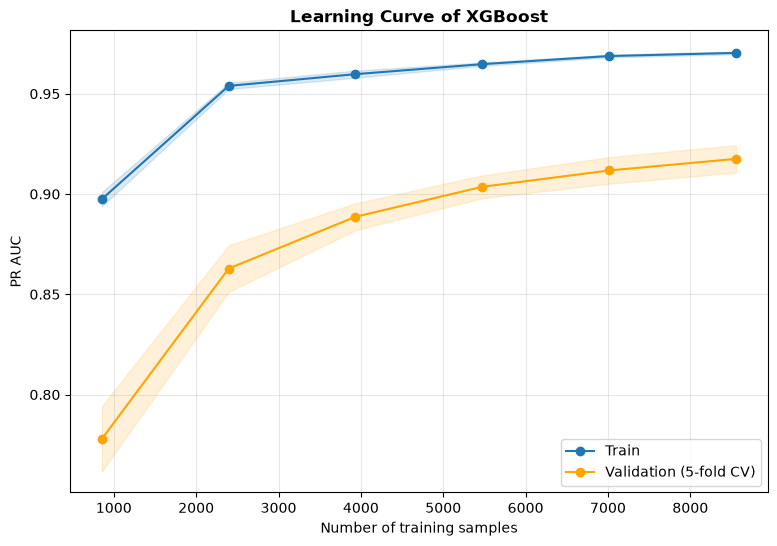

In [133]:
### --- Learning Curve of XGBoost --- ###
sizes, train_sc, val_sc = learning_curve(
    clone(xgb_model).set_params(n_jobs = 1), X_train, y_train, train_sizes = BUDGET['lc_sizes'],
    cv = CV, scoring = 'average_precision', n_jobs = -1)

plt.figure(figsize = (9, 6))
for scores, label, color in [(train_sc, 'Train', 'tab:blue'), (val_sc, 'Validation (5-fold CV)', 'orange')]:
    plt.plot(sizes, scores.mean(axis = 1), marker = 'o', color = color, label = label)
    plt.fill_between(sizes, scores.mean(axis = 1) - scores.std(axis = 1),
                     scores.mean(axis = 1) + scores.std(axis = 1), color = color, alpha = 0.15)
plt.xlabel('Number of training samples')
plt.ylabel('PR AUC')
plt.title('Learning Curve of XGBoost', fontweight = 'bold')
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.3)
plt.show()

> **Takeaway.** Tables 1 and 2 are the summary of the modelling. Performance rises with flexibility: the test ROC AUC goes from 0.806 (logistic regression) to 0.880 (tree), 0.920 (forest), 0.963 (XGBoost) and 0.959 (MLP). The bootstrap intervals show that **XGBoost and the MLP cannot be told apart** (AUC difference +0.003, 95% CI -0.003 to +0.010), while every simpler model is clearly worse (-0.039 for the forest, -0.080 for the tree and -0.154 for the logistic regression, all intervals far from 0). Both also have the lowest Brier scores (0.071) and log losses (0.227 and 0.234). In the reliability diagram XGBoost stays closest to the diagonal, the MLP over-predicts somewhat in the middle of the range and the forest is the least well calibrated, but each bin holds only about 119 test samples, so the curves are noisy. The learning curve (Section 13.8) is **still rising** at the full training size: the validation ROC AUC grows from about 0.95 with 4,000 samples to 0.965 with 8,500, and a gap of about 0.02 with the training curve remains, so more simulations would still help, with diminishing returns. The explanation below is applied to **XGBoost**, because TreeSHAP is exact and fast for tree ensembles and because it is statistically tied with the best model of Table 2.

## **14. Interpreting XGBoost**

XGBoost is a black box. Before opening it, a word on what an explanation can and cannot tell us.

**What SHAP assumes.** SHAP borrows from cooperative game theory: the features are the *players*, the *payout* is the prediction minus the average prediction, and Shapley values share the payout according to fairness axioms. This needs

1. a rule for what *removing* a feature means. `TreeExplainer` integrates a feature out using the training data seen by each tree, which is only harmless if features are not strongly dependent. **Here they are independent by design** (Section 4.5), which is a real strength of this data set;
2. an additive decomposition **in log-odds**, not in probability;
3. the acceptance of the Shapley axioms as the *definition* of a feature's contribution.

Above all, SHAP values explain **the model, not the simulator**. They are only as good as the model's fit (Section 13).

**What we deliberately do not use.** SHAP *interaction* values add another layer: a second-order Shapley index, split symmetrically between two features, which is then read as a biological interaction. On top of an approximate model, this stacks assumption on assumption. We therefore keep SHAP simple (global importance, direction of the effects, dependence plots) and study interactions with tools that need fewer assumptions:

- **ICE curves and partial dependence plots** (model-based, but each curve answers one clear question: *what does the model predict if I change only this parameter?*);
- **jointplots and observed rates in bins** (no model at all).

Because the parameters are independent and uniformly distributed, the partial dependence of the *true* process equals the observed polymorphism rate in a bin. This gives us an independent check of the model, which a SHAP-only analysis cannot offer (Sections 14.5 and 14.6).

The analysis is organised as follows:

| Section | Question |
|---|---|
| 14.1 to 14.3 | SHAP: which parameters drive the predictions, and in which direction? |
| 14.4 | PDP and ICE: what is the shape of each effect? |
| 14.5 | Which parameters interact? Look at the data, then compare with the model. |
| 14.6 | A specific hypothesis: dominance in queens and workers. |
| 14.7 | Distillation: can a small readable model reproduce the black box? |
| 14.8 | Why did distillation struggle, and which student fits better? |
| 14.9 | Is there a readable model that matches the black box? (Explainable Boosting Machine) |
| 14.10 | Which pairs of parameters interact? A screen without SHAP interaction values. |

### **14.1 Computing the SHAP Values**

SHAP values are computed on the **test set**: it shows how the model behaves on parameter sets it did not train on, which is where the model is actually used. Each value is in **log-odds** units. The baseline (`expected value`) is the model's average output; converted to a probability it should be close to the real share of polymorphic parameter sets, since the data was not rebalanced. The last line checks the **local accuracy** property of SHAP: baseline plus the sum of the SHAP values of a sample must reproduce the model's output for that sample.

In [134]:
### --- SHAP Values on the Test Set --- ###
best_xgb = RESULTS['XGBoost']['model']
X_explain = X_test.copy()

explainer = shap.TreeExplainer(best_xgb)      # Exact for tree ensembles (tree-path-dependent, see the text above).
shap_expl = explainer(X_explain)

shap_vals = np.asarray(shap_expl.values)
if shap_vals.ndim == 3:                       # Some SHAP versions return one slice per class.
    shap_vals = shap_vals[:, :, 1]
base_value = float(np.ravel(shap_expl.base_values)[0])

print('SHAP array shape:', shap_vals.shape, '(samples x features)')
print(f'Baseline (expected value): {base_value:.3f} log-odds = {1 / (1 + np.exp(-base_value)):.1%} probability of polymorphism')
print(f'Share of polymorphic parameter sets in the training data: {y_train.mean():.1%}')

# Local accuracy: baseline + sum of SHAP values should equal the model output (log-odds).
margin = best_xgb.predict(X_explain, output_margin = True)
print(f'Local accuracy check: max |baseline + sum(SHAP) - model output| = {np.abs(base_value + shap_vals.sum(axis = 1) - margin).max():.2e}')

SHAP array shape: (1189, 9) (samples x features)
Baseline (expected value): -0.938 log-odds = 28.1% probability of polymorphism
Share of polymorphic parameter sets in the training data: 28.0%
Local accuracy check: max |baseline + sum(SHAP) - model output| = 1.05e-05


### **14.2 Global Explanation: Beeswarm and Importance**

**Beeswarm plot.** Every dot is one test sample. Its horizontal position is the SHAP value of the feature (how much it pushes the prediction, in log-odds), and its colour is the value of the feature (red is high, blue is low). Features are sorted from the most to the least influential. Read the plot feature by feature: *which colour is on the right?* tells the direction of the effect, and a mix of colours at a given position hints that other features modulate the effect.

**Global importance.** Averaging the absolute SHAP values over the samples gives a single ranking of the features. `Nq` and `Nm` are represented as single numeric columns, their thus this avoids that their importance is spread over multiple dummy variables and can be compared directly with the others.

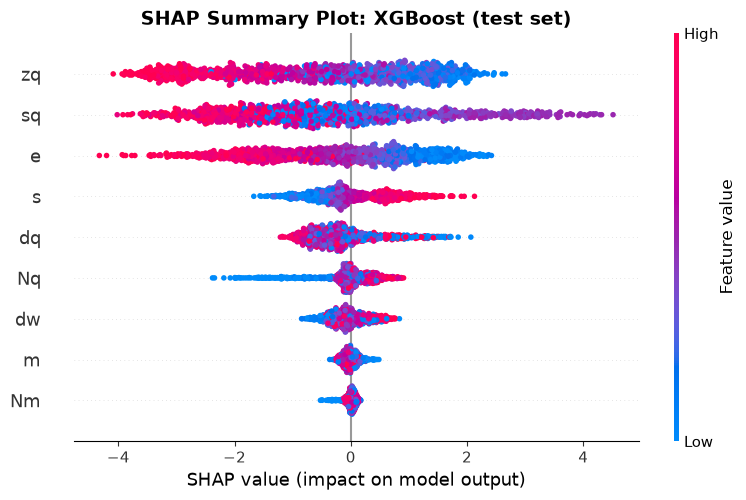

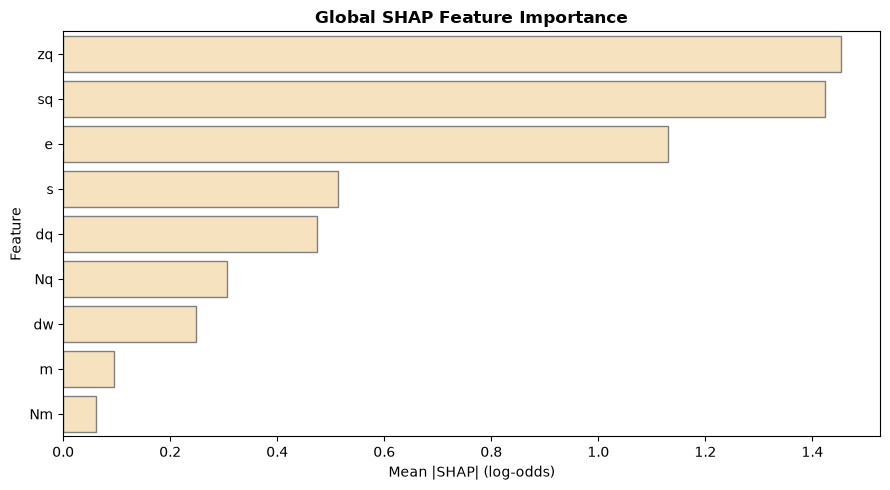

,Feature,Mean |SHAP| (log-odds)
0,zq,1.454
1,sq,1.423
2,e,1.130
3,s,0.514
4,dq,0.475
5,Nq,0.307
6,dw,0.248
7,m,0.095
8,Nm,0.061


In [135]:
### --- SHAP Summary Plot (Beeswarm) --- ###
plt.figure(figsize = (10, 6))
shap.summary_plot(shap_vals, X_explain, show = False)
plt.title('SHAP Summary Plot: XGBoost (test set)', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

### --- Global SHAP Feature Importance --- ###
shap_importance = pd.DataFrame({
    'Feature': X_explain.columns,
    'Mean |SHAP| (log-odds)': np.abs(shap_vals).mean(axis = 0),
}).sort_values('Mean |SHAP| (log-odds)', ascending = False).reset_index(drop = True)

plt.figure(figsize = (9, 5))
sns.barplot(data = shap_importance, x = 'Mean |SHAP| (log-odds)', y = 'Feature', color = 'moccasin', edgecolor = 'gray')
plt.title('Global SHAP Feature Importance', fontweight = 'bold')
plt.tight_layout()
plt.show()
display(shap_importance.round(3))

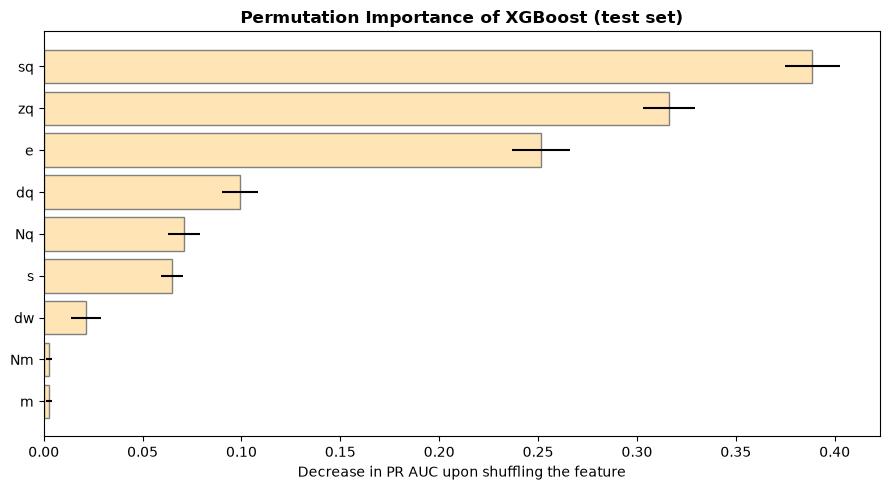

,Feature,Drop in PR AUC,sd
0,sq,0.3888,0.0140
1,zq,0.3163,0.0131
2,e,0.2514,0.0148
3,dq,0.0993,0.0092
4,Nq,0.0709,0.0079
5,s,0.0648,0.0054
6,dw,0.0213,0.0076
7,Nm,0.0028,0.0015
8,m,0.0027,0.0016


In [136]:
### --- Permutation Importance of XGBoost on the PR AUC (test set) --- ###
perm_xgb = permutation_importance(best_xgb, X_test, y_test, scoring = 'average_precision', n_repeats = BUDGET['perm_repeats_xgb'],
                                  random_state = random_seed, n_jobs = 1)
perm_table = pd.DataFrame({'Feature': X_test.columns, 'Drop in PR AUC': perm_xgb.importances_mean,
                           'sd': perm_xgb.importances_std}).sort_values('Drop in PR AUC', ascending = False).reset_index(drop = True)
plt.figure(figsize = (9, 5))
order_p = perm_table.iloc[::-1]
plt.barh(order_p['Feature'], order_p['Drop in PR AUC'], xerr = order_p['sd'], color = 'moccasin', edgecolor = 'gray')
plt.xlabel('Decrease in PR AUC upon shuffling the feature')
plt.title('Permutation Importance of XGBoost (test set)', fontweight = 'bold')
plt.tight_layout()
plt.show()
display(perm_table.round(4))

### **14.3 Direction and Shape of the Effects: SHAP Dependence Plots**

One panel per parameter, ordered by importance. Each dot is a test sample: its horizontal position is the value of the parameter, its vertical position is its SHAP value (the push on the log-odds of polymorphism, above 0 favours polymorphism). The **black line is the average effect**: a flat line means that the parameter does nothing on average. The **colour is the value of the parameter that best explains the vertical spread of the dots** (`shap.approximate_interactions`, a quick heuristic on the ordinary SHAP values; no SHAP interaction values are computed). A clean separation of colours at a given x means that the effect of the parameter depends on that partner.

The table below the figure turns each panel into a verdict: **clear effect** (the average curve spans more than 0.5 log-odds), **only through a partner** (flat on average, but the dots spread widely around the curve), or **little or no effect**.

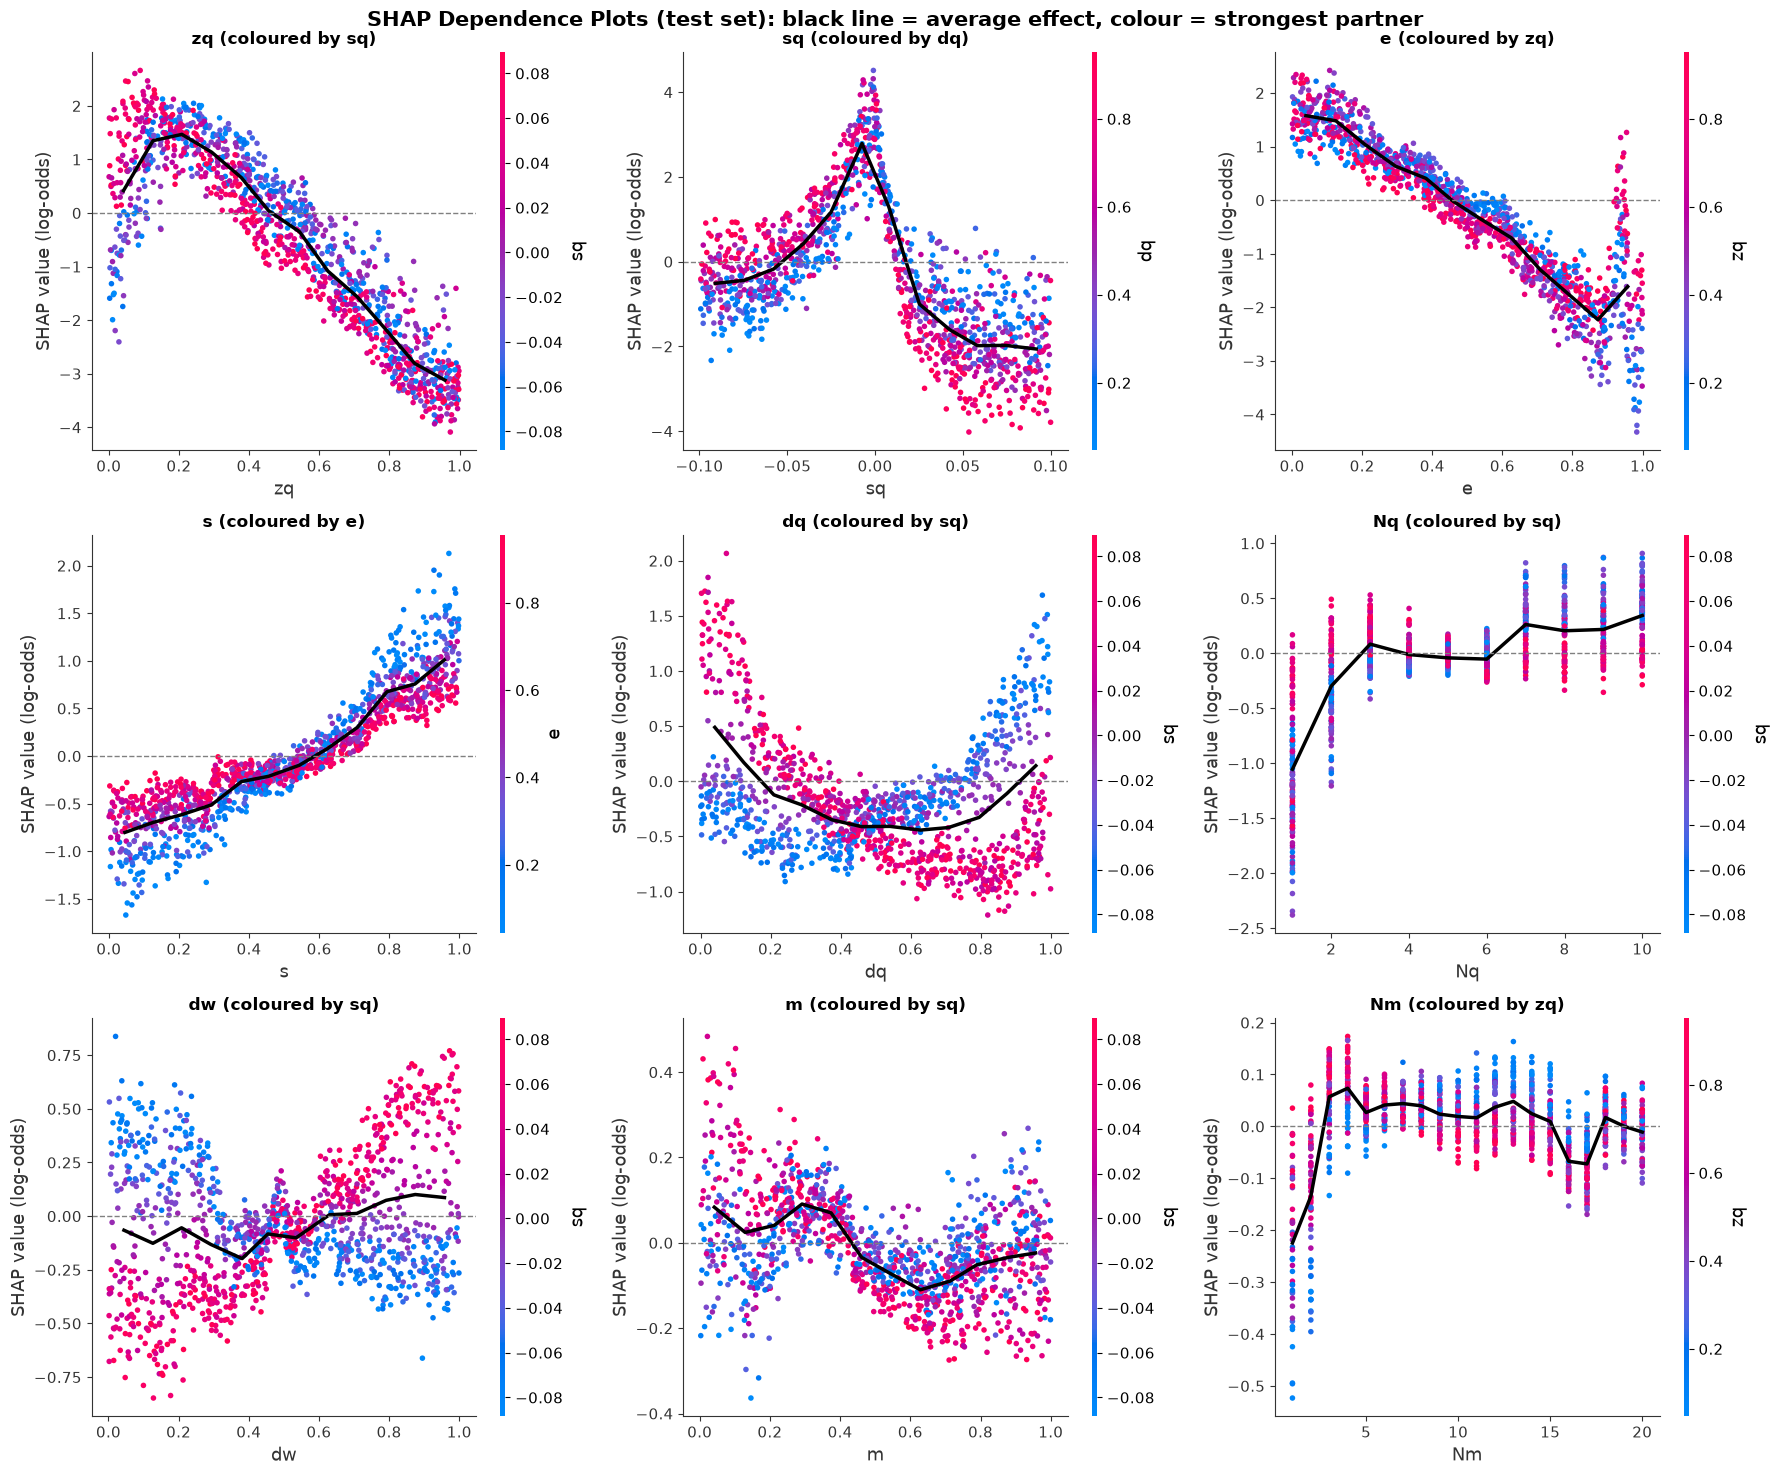

,mean |SHAP|,span of average curve,shape,spread around the curve,strongest partner,verdict
parameter,,,,,,
zq,1.454,4.589,decreases,0.601,sq,clear effect
sq,1.423,4.848,non-monotone,0.788,dq,clear effect
e,1.130,3.808,decreases,0.520,zq,clear effect
s,0.514,1.812,increases,0.231,e,clear effect
dq,0.475,0.932,non-monotone,0.479,sq,clear effect
Nq,0.307,1.398,increases,0.285,sq,clear effect
dw,0.248,0.299,non-monotone,0.289,sq,clear effect
m,0.095,0.201,flat,0.099,sq,little or no effect
Nm,0.061,0.298,non-monotone,0.058,zq,clear effect


In [137]:
### --- SHAP Dependence Plots: Every Parameter, Coloured by Its Strongest Partner --- ###
# The colour feature is the one that best explains the vertical spread of the SHAP values (shap.approximate_interactions).
# This is a cheap heuristic on the ordinary SHAP values: it does NOT compute SHAP interaction values.
EFFECT_THRESHOLD = 0.25    # A parameter has a visible effect if its average curve spans more than this (log-odds).
SPREAD_THRESHOLD = 0.7   # ... or only through a partner if the dots spread around a flat curve by more than this.

effect_rows, partner_of = [], {}
fig, axes = plt.subplots(3, 3, figsize = (18, 15))
for ax, feat in zip(axes.ravel(), shap_importance['Feature']):
    j = list(X_explain.columns).index(feat)
    partner = X_explain.columns[shap.approximate_interactions(j, shap_vals, X_explain)[0]]
    partner_of[feat] = partner
    shap.dependence_plot(j, shap_vals, X_explain, interaction_index = partner, ax = ax, show = False)

    # Average SHAP value per integer (counts) or per bin (continuous features): the black line.
    x, y_s = X_explain[feat].to_numpy(), shap_vals[:, j]
    if len(np.unique(x)) <= 20:
        avg = pd.Series(y_s).groupby(x).mean()
        curve_x, curve_y = avg.index.to_numpy(), avg.to_numpy()
    else:
        binned = pd.DataFrame({'x': x, 'y': y_s, 'bin': pd.cut(x, 12)}).groupby('bin', observed = True).mean()
        curve_x, curve_y = binned['x'].to_numpy(), binned['y'].to_numpy()
    ax.plot(curve_x, curve_y, color = 'black', linewidth = 2.5)
    ax.axhline(0, color = 'gray', linestyle = '--', linewidth = 1)
    ax.set_title(f'{feat} (coloured by {partner})', fontweight = 'bold')
    ax.set_ylabel('SHAP value (log-odds)')

    span = curve_y.max() - curve_y.min()
    spread = np.std(y_s - np.interp(x, curve_x, curve_y))
    rho = stats.spearmanr(curve_x, curve_y).correlation
    shape = 'increases' if rho > 0.8 else 'decreases' if rho < -0.8 else 'non-monotone'
    effect_rows.append({'parameter': feat, 'mean |SHAP|': np.abs(y_s).mean(), 'span of average curve': span,
                        'shape': shape if span > EFFECT_THRESHOLD else 'flat',
                        'spread around the curve': spread, 'strongest partner': partner,
                        'verdict': 'clear effect' if span > EFFECT_THRESHOLD
                                   else f'only through {partner}' if spread > SPREAD_THRESHOLD else 'little or no effect'})
fig.suptitle('SHAP Dependence Plots (test set): black line = average effect, colour = strongest partner', fontsize = 15, fontweight = 'bold')
plt.tight_layout()
plt.show()

display(pd.DataFrame(effect_rows).set_index('parameter').round(3))

### **14.4 Partial Dependence and ICE Curves**

A **partial dependence plot** (PDP) shows the *average* predicted probability of polymorphism when one parameter is set to each value of its range, all the other parameters keeping the values observed in the data. An **ICE curve** (individual conditional expectation) draws the same thing for a single parameter set. The thick line is the PDP, the thin lines are ICE curves of 150 parameter sets.

- If all ICE curves are parallel, the effect of the parameter is the same whatever the other parameters are.
- If they fan out or cross, the effect **depends on the other parameters**: there is an interaction, and the PDP, being an average, hides it.

PDPs assume that the feature of interest is independent of the others, so that setting it to any value produces a realistic parameter set. This holds here by design. The probabilities are on a real probability scale, because the data was not rebalanced.

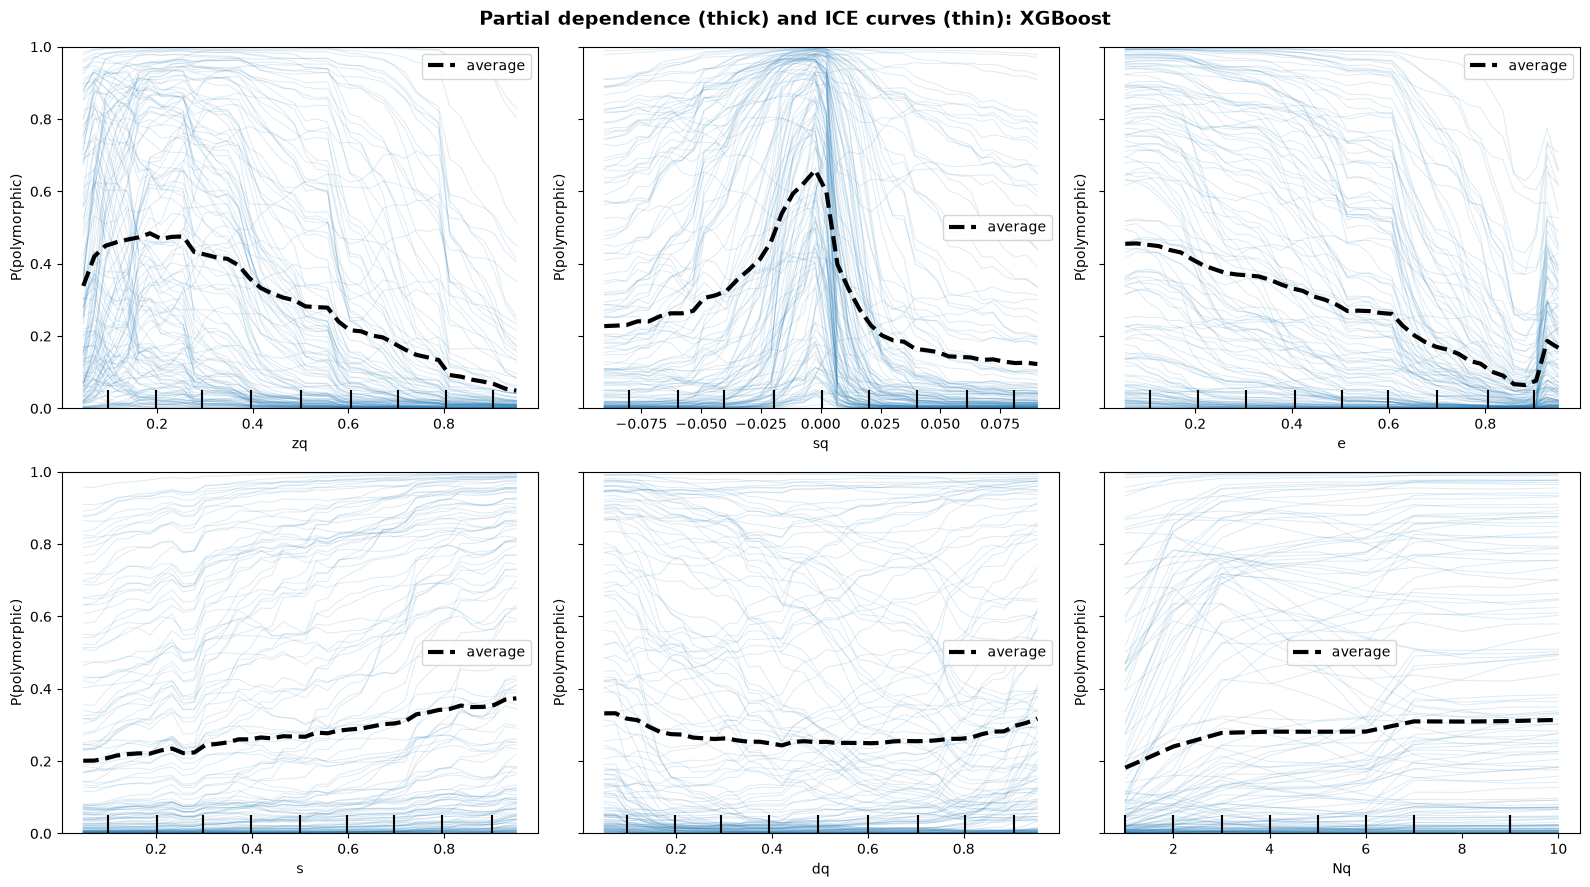

In [138]:
### --- 1D Partial Dependence and ICE Curves for the Six Most Important Features --- ###
top_features = list(shap_importance['Feature'].head(6))
fig, axes = plt.subplots(2, 3, figsize = (16, 9))
PartialDependenceDisplay.from_estimator(
    best_xgb, X_train.sample(min(5000, len(X_train)), random_state = random_seed), features = top_features, kind = 'both',
    subsample = 150, grid_resolution = 40, random_state = random_seed,
    ice_lines_kw = {'color': 'tab:blue', 'alpha': 0.15, 'linewidth': 0.7},
    pd_line_kw = {'color': 'black', 'linewidth': 3},
    ax = axes)
for ax in axes.ravel():
    ax.set_ylim(0, 1)
    ax.set_ylabel('P(polymorphic)')
fig.suptitle('Partial dependence (thick) and ICE curves (thin): XGBoost', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

### **14.5 Which Parameters Interact? Look at the Data First**

We focus on the three most important parameters and look at each pair in two ways:

1. **Jointplots of the raw data** (no model): each dot is a simulated parameter set, coloured by outcome. The marginal curves show how the two classes differ along each axis, and the scatter shows where in the plane the classes separate.
2. **Observed polymorphism rate in bins, compared with the model's 2D partial dependence.** Because the parameters are independent, the two should agree if the model is good. Where they disagree, the model, not the biology, is to blame.

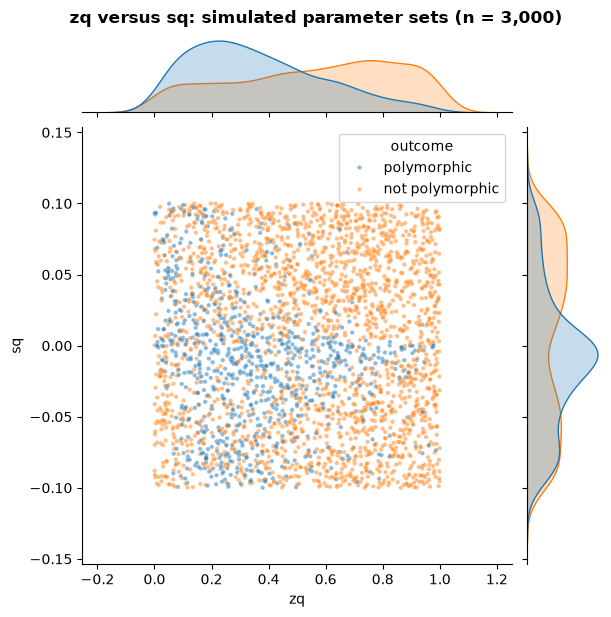

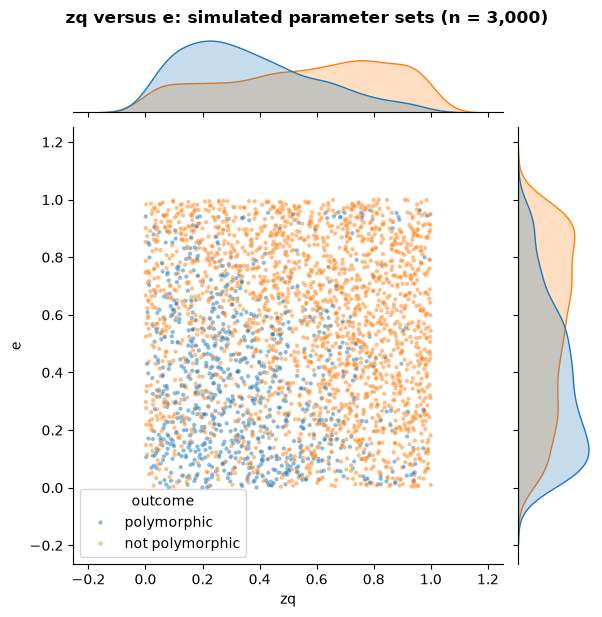

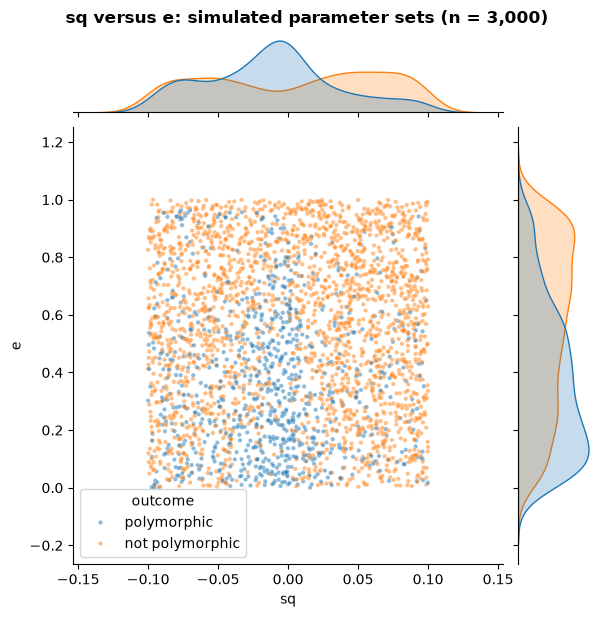

In [139]:
### --- Jointplots of the Top Pairs of Features (raw data, no model) --- ###
top3 = list(shap_importance['Feature'].head(3))
n_joint = min(3000, len(df_model))
plot_data = df_model.assign(outcome = df_model[target_col].map({0: 'not polymorphic', 1: 'polymorphic'})).sample(n_joint, random_state = random_seed)

for f1, f2 in itertools.combinations(top3, 2):
    g = sns.jointplot(data = plot_data, x = f1, y = f2, hue = 'outcome', kind = 'scatter',
                      s = 10, alpha = 0.5, height = 6, marginal_kws = {'common_norm': False})
    g.figure.suptitle(f'{f1} versus {f2}: simulated parameter sets (n = {n_joint:,})', y = 1.02, fontweight = 'bold')
    plt.show()

In [140]:
### --- Helpers: Binning, Observed Rates and 2D Partial Dependence --- ###
def bin_centers(feature, n_bins):
    """Centres of the bins of a feature (one value per integer for the counts Nq and Nm)."""
    lo_, hi_ = PARAM_RANGES[feature]
    if feature in ('Nq', 'Nm'):
        return np.arange(lo_, hi_ + 1, dtype = float)
    edges = np.linspace(lo_, hi_, n_bins + 1)
    return (edges[:-1] + edges[1:]) / 2

def bin_index(values, feature, n_bins):
    """Index of the bin of every value."""
    lo_, hi_ = PARAM_RANGES[feature]
    if feature in ('Nq', 'Nm'):
        return (np.rint(np.asarray(values)) - lo_).astype(int)
    edges = np.linspace(lo_, hi_, n_bins + 1)
    return np.clip(np.digitize(values, edges[1:-1]), 0, n_bins - 1)

def axis_extent(feature, n_bins):
    """Plot extent (left, right) of a feature axis."""
    lo_, hi_ = PARAM_RANGES[feature]
    return (lo_ - 0.5, hi_ + 0.5) if feature in ('Nq', 'Nm') else (lo_, hi_)

def empirical_rate_grid(data, f1, f2, n_bins):
    """Observed share of polymorphic parameter sets in every (f1, f2) cell. Rows follow f2, columns follow f1."""
    n1, n2 = len(bin_centers(f1, n_bins)), len(bin_centers(f2, n_bins))
    i = bin_index(data[f1].to_numpy(), f1, n_bins)
    j = bin_index(data[f2].to_numpy(), f2, n_bins)
    positives = np.zeros((n2, n1))
    counts = np.zeros((n2, n1))
    np.add.at(positives, (j, i), data[target_col].to_numpy())
    np.add.at(counts, (j, i), 1)
    return np.where(counts > 0, positives / np.maximum(counts, 1), np.nan), counts

def pdp_2d(model, background, f1, f2, grid1, grid2):
    """2D partial dependence: average predicted probability when (f1, f2) are set to every grid combination.

    All the other features keep the values of the `background` rows. Rows follow f2, columns follow f1.
    """
    out = np.zeros((len(grid2), len(grid1)))
    modified = background.copy()
    for a, v1 in enumerate(grid1):
        for b, v2 in enumerate(grid2):
            modified[f1] = v1
            modified[f2] = v2
            out[b, a] = model.predict_proba(modified)[:, 1].mean()
    return out

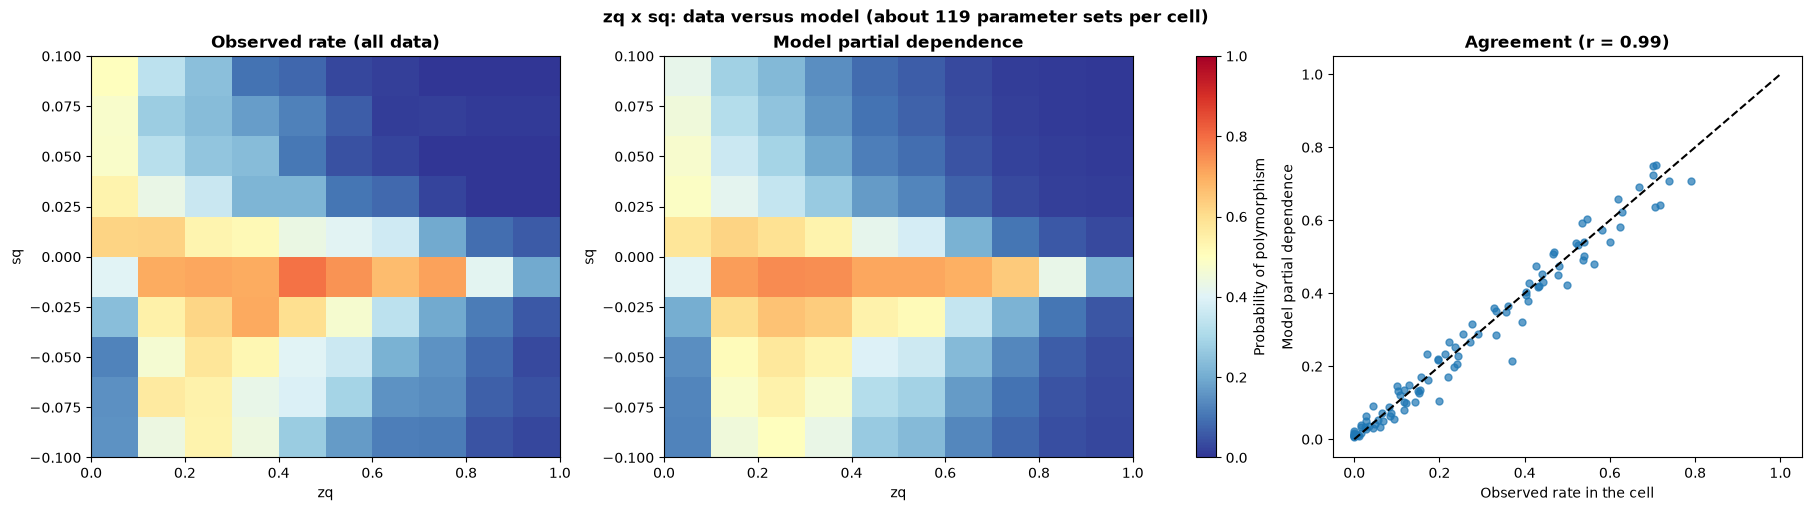

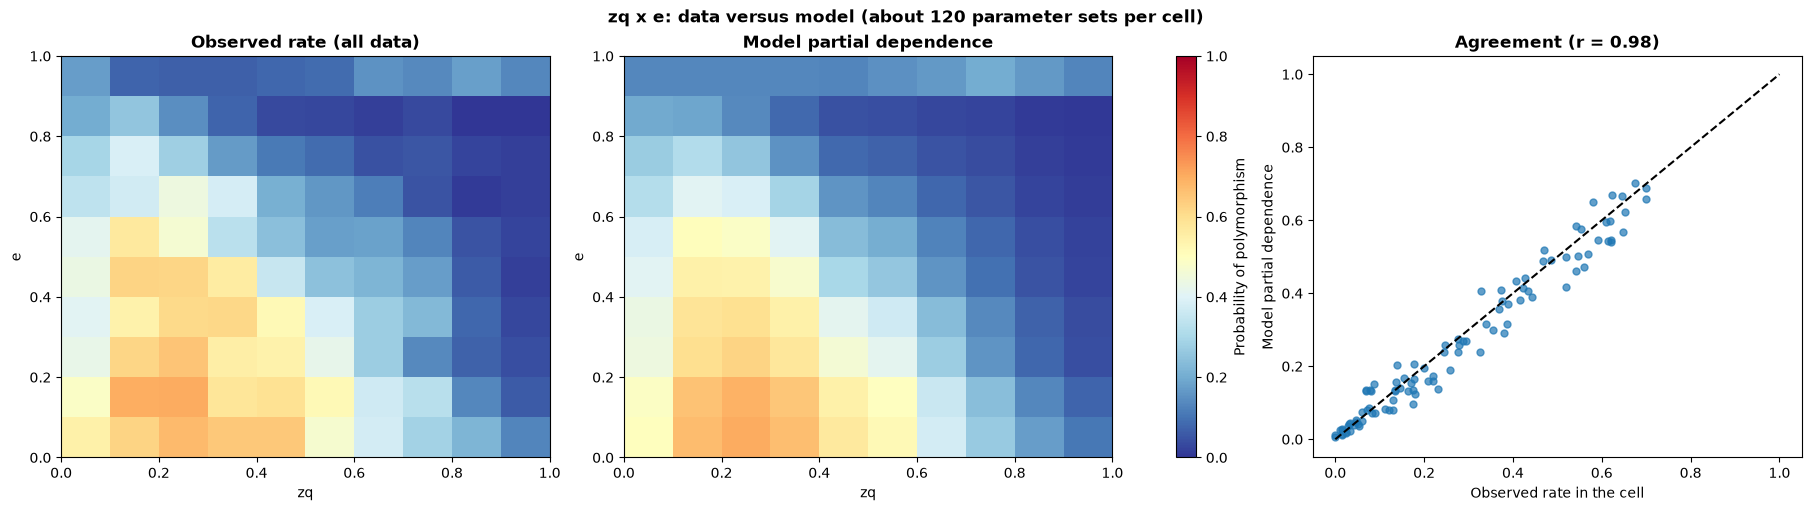

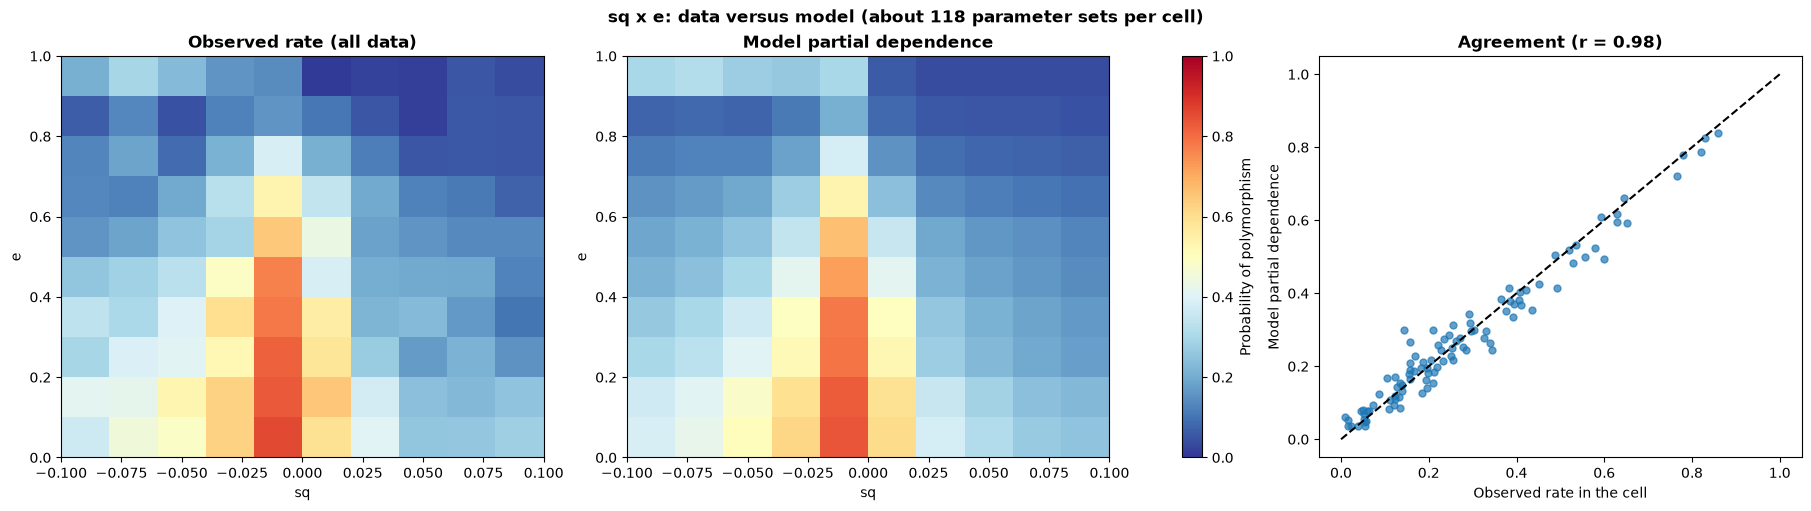

In [141]:
### --- Observed Rate Versus Model Partial Dependence for the Top Pairs --- ###
n_bins_pair = 10
background_pairs = X_train.sample(n = 300, random_state = random_seed)

for f1, f2 in itertools.combinations(top3, 2):
    g1, g2 = bin_centers(f1, n_bins_pair), bin_centers(f2, n_bins_pair)
    emp, counts = empirical_rate_grid(df_model, f1, f2, n_bins_pair)
    pdp = pdp_2d(best_xgb, background_pairs, f1, f2, g1, g2)

    fig, axes = plt.subplots(1, 3, figsize = (18, 5), layout = 'constrained')
    extent = [*axis_extent(f1, n_bins_pair), *axis_extent(f2, n_bins_pair)]
    for ax, arr, title in [(axes[0], emp, 'Observed rate (all data)'), (axes[1], pdp, 'Model partial dependence')]:
        im = ax.imshow(arr, origin = 'lower', extent = extent, aspect = 'auto', vmin = 0, vmax = 1, cmap = 'RdYlBu_r')
        ax.set_xlabel(f1); ax.set_ylabel(f2); ax.set_title(title, fontweight = 'bold')
    fig.colorbar(im, ax = axes[:2], label = 'Probability of polymorphism')

    ok = ~np.isnan(emp)
    axes[2].scatter(emp[ok], pdp[ok], s = 25, alpha = 0.7)
    axes[2].plot([0, 1], [0, 1], 'k--')
    axes[2].set_xlabel('Observed rate in the cell'); axes[2].set_ylabel('Model partial dependence')
    axes[2].set_title(f'Agreement (r = {np.corrcoef(emp[ok], pdp[ok])[0, 1]:.2f})', fontweight = 'bold')
    fig.suptitle(f'{f1} x {f2}: data versus model (about {int(np.median(counts[counts > 0]))} parameter sets per cell)', fontweight = 'bold')
    plt.show()

> **Takeaway.** A pair of parameters interacts when the picture along one of them changes with the value of the other, which appears as a *diagonal* or *curved* boundary in the maps instead of straight horizontal or vertical bands. The scatter on the right shows whether the model reproduces what the data shows: points on the dashed line mean that the model, and hence the analyses based on it, can be trusted for that pair. Cell counts are modest, so differences of a few percentage points between data and model are within sampling noise.

### **14.6 A Specific Hypothesis: Dominance in Queens and Workers**

**The expectation.** If an allele is good for one caste and bad for the other, theory on antagonistic selection suggests that polymorphism is easiest to maintain when the allele is **dominant in the caste that it benefits** and **recessive in the caste that it harms** (*dominance reversal*). Applied to our model:

| Sign of `sq` | Allele favours | Expected relation for polymorphism | Where it lies in the (`dq`, `dw`) map |
|---|---|---|---|
| **Negative** | Workers | polymorphism more frequent when `dq < dw` | above the diagonal |
| **Positive** | Queens | polymorphism more frequent when `dq > dw` | below the diagonal |

**The approach.** We answer in three steps, from the fewest to the most assumptions:

1. **Directly on the simulation data.** The parameters were drawn independently of each other, so the dominance relation is **not confounded** with any other parameter: a difference in the observed polymorphism rate between `dq < dw` and `dq > dw`, within a sign of `sq`, can be attributed to the dominance relation. This uses all the simulated parameter sets and no model. We test the association of the relation with the **outcome** (polymorphism), not with the other inputs, which are independent by construction.
2. **With the model.** A 2D partial dependence in the (`dq`, `dw`) plane, computed separately for each sign of `sq`, on the **same grid** so that the two maps can be subtracted.
3. **Agreement** between the two.

**Step 1a. Observed rates, with confidence intervals.** For each sign of `sq`, the observed polymorphism rate when `dq < dw` and when `dq > dw`, with 95% Wilson intervals, and the difference between the two with a 95% bootstrap interval.

In [142]:
### --- Observed Polymorphism Rates by Sign of sq and dq / dw Relation (all data) --- ###
# Expected relation under dominance reversal, from the generator's fecundity max(0, (1 - queen phenotype) x worker phenotype):
# sq < 0 favours queens (dominant in queens, recessive in workers: dq > dw), sq > 0 favours workers (dq < dw).
EXPECTED_RELATION = {'sq < 0': 'dq > dw', 'sq > 0': 'dq < dw'}

dom = df_model.assign(
    sq_sign = np.where(df_model['sq'] < 0, 'sq < 0', 'sq > 0'),
    relation = np.where(df_model['dq'] < df_model['dw'], 'dq < dw', 'dq > dw'))

rng_dom = np.random.default_rng(random_seed)
rate_rows = []
for sign, expected in EXPECTED_RELATION.items():
    counts_ = {}
    for rel in ['dq < dw', 'dq > dw']:
        subset = dom[(dom['sq_sign'] == sign) & (dom['relation'] == rel)][target_col]
        k, n = int(subset.sum()), len(subset)
        low, high = wilson_ci(k, n)
        counts_[rel] = (n, k / n)
        rate_rows.append({'sq': sign, 'relation': rel, 'n': n, 'observed rate': k / n,
                          '95% CI low': low, '95% CI high': high})
    # Difference rate(dq < dw) - rate(dq > dw), with a parametric bootstrap interval.
    (n_lt, p_lt), (n_gt, p_gt) = counts_['dq < dw'], counts_['dq > dw']
    diff = p_lt - p_gt
    draws = rng_dom.binomial(n_lt, p_lt, 5000) / n_lt - rng_dom.binomial(n_gt, p_gt, 5000) / n_gt
    d_low, d_high = np.percentile(draws, [2.5, 97.5])
    expected_sign = +1 if expected == 'dq < dw' else -1
    if d_low > 0 or d_high < 0:
        verdict = 'consistent with dominance reversal' if np.sign(diff) == expected_sign else 'OPPOSITE to dominance reversal'
    else:
        verdict = 'inconclusive (the interval contains 0)'
    print(f'{sign}: rate(dq<dw) - rate(dq>dw) = {diff:+.3f}  [95% CI {d_low:+.3f}, {d_high:+.3f}]  ->  {verdict}')

display(pd.DataFrame(rate_rows).set_index(['sq', 'relation']).round(3))

sq < 0: rate(dq<dw) - rate(dq>dw) = -0.143  [95% CI -0.166, -0.119]  ->  consistent with dominance reversal
sq > 0: rate(dq<dw) - rate(dq>dw) = +0.171  [95% CI +0.151, +0.191]  ->  consistent with dominance reversal


n  observed rate  95% CI low  95% CI high
sq     relation                                              
sq < 0 dq < dw   2934          0.287       0.271        0.303
       dq > dw   2996          0.430       0.412        0.447
sq > 0 dq < dw   2993          0.288       0.272        0.304
       dq > dw   2959          0.116       0.105        0.128

**Step 1b. The whole picture along `dq - dw`.** The same observed rates, now along the *difference* `D = dq - dw` (bins of width 0.2) instead of just its sign, with 95% Wilson intervals. Under dominance reversal, the rate for negative `sq` should **decrease** with `D` and the rate for positive `sq` should **increase**.

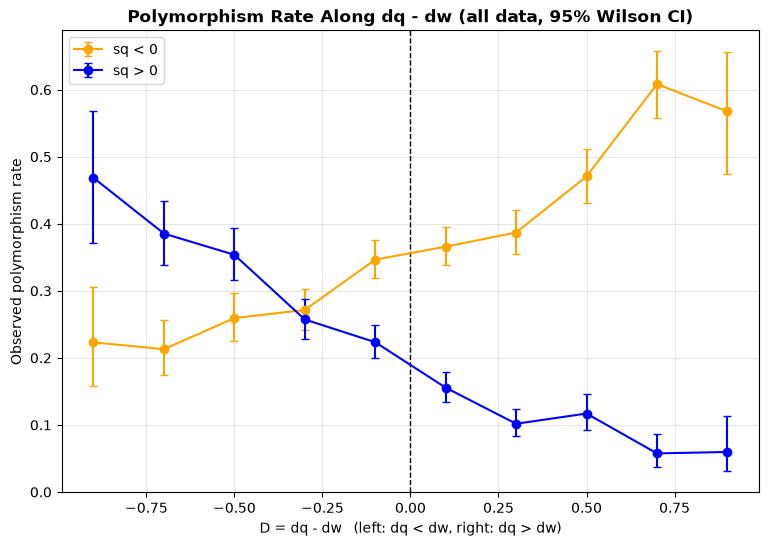

In [157]:
### --- Observed Polymorphism Rate Along D = dq - dw, by Sign of sq --- ###
dom['D'] = dom['dq'] - dom['dw']
dom['D_bin'] = pd.cut(dom['D'], np.linspace(-1, 1, 11), include_lowest = True)

fig, ax = plt.subplots(figsize = (9, 6))
for sign, color in [('sq < 0', 'orange'), ('sq > 0', 'blue')]:
    g = dom[dom['sq_sign'] == sign].groupby('D_bin', observed = True)[target_col].agg(['sum', 'count'])
    centers = np.array([iv.mid for iv in g.index])
    rate = (g['sum'] / g['count']).to_numpy()
    ci = np.array([wilson_ci(k, n) for k, n in zip(g['sum'], g['count'])])
    ax.errorbar(centers, rate, yerr = [rate - ci[:, 0], ci[:, 1] - rate], marker = 'o', capsize = 3, color = color, label = sign)
ax.axvline(0, color = 'black', linestyle = '--', linewidth = 1)
ax.set_xlabel('D = dq - dw   (left: dq < dw, right: dq > dw)')
ax.set_ylabel('Observed polymorphism rate')
ax.set_title('Polymorphism Rate Along dq - dw (all data, 95% Wilson CI)', fontweight = 'bold')
ax.legend()
ax.grid(alpha = 0.3)
plt.show()

**Step 2. Maps in the (`dq`, `dw`) plane.** Top row: observed rates in 8 x 8 bins (all data). Bottom row: the model's partial dependence on the same grid, with 300 background parameter sets of the matching sign of `sq`. The dashed line is `dq = dw`. The right column is the difference *positive `sq` minus negative `sq`* (red: positive `sq` makes polymorphism more likely). The observed maps are noisy cell by cell; the model map is their smoothed version.

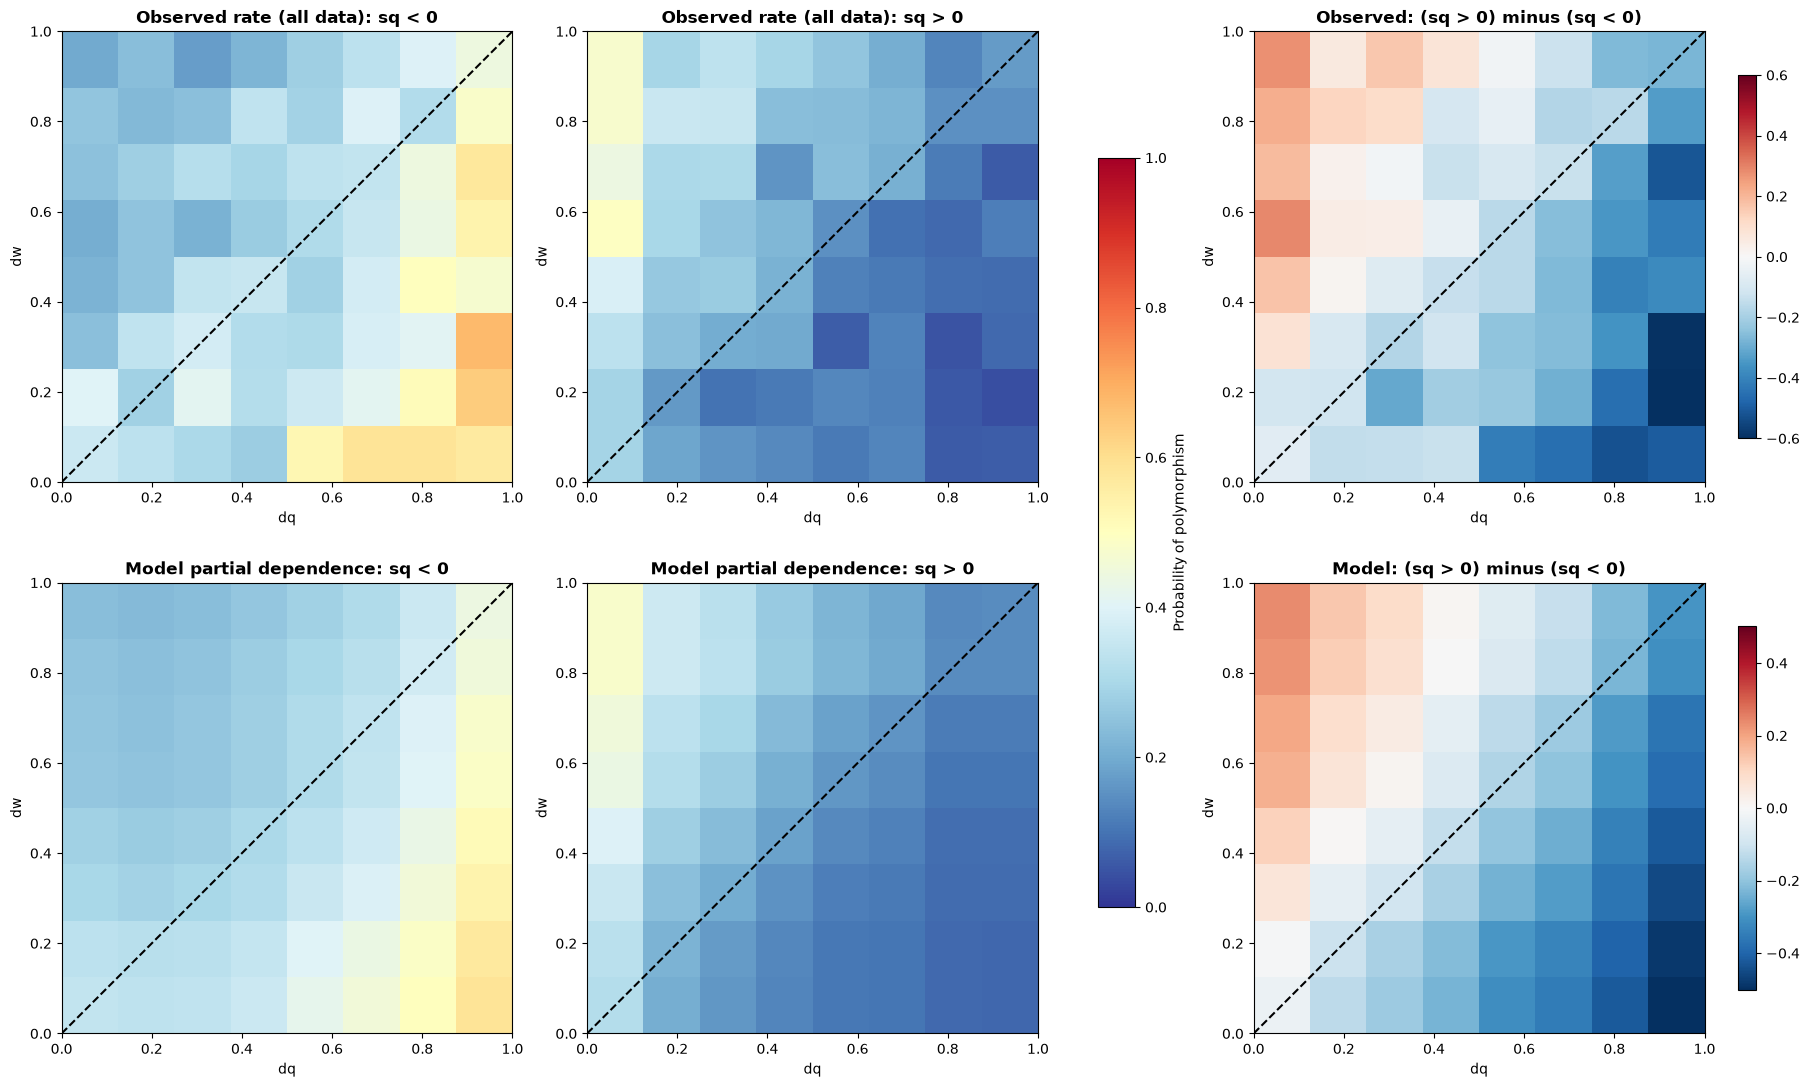

sq < 0: correlation between observed and model cells = 0.91, mean absolute difference = 0.041, median parameter sets per cell = 92
sq > 0: correlation between observed and model cells = 0.96, mean absolute difference = 0.024, median parameter sets per cell = 93


In [144]:
### --- Observed and Model-Based Maps in the (dq, dw) Plane --- ###
n_bins_dom = 8
grid_dom = bin_centers('dq', n_bins_dom)       # dq and dw share the same range, hence the same grid.
maps = {}
for sign, test_cond, all_cond in [('sq < 0', X_train['sq'] < 0, df_model['sq'] < 0),
                                  ('sq > 0', X_train['sq'] > 0, df_model['sq'] > 0)]:
    emp, counts = empirical_rate_grid(df_model[all_cond], 'dq', 'dw', n_bins_dom)
    background = X_train[test_cond].sample(n = 300, random_state = random_seed)
    maps[sign] = (emp, counts, pdp_2d(best_xgb, background, 'dq', 'dw', grid_dom, grid_dom))

fig, axes = plt.subplots(2, 3, figsize = (18, 11), layout = 'constrained')
for col, sign in enumerate(['sq < 0', 'sq > 0']):
    emp, counts, pdp = maps[sign]
    for row, (arr, name) in enumerate([(emp, 'Observed rate (all data)'), (pdp, 'Model partial dependence')]):
        ax = axes[row, col]
        im = ax.imshow(arr, origin = 'lower', extent = [0, 1, 0, 1], aspect = 'equal', vmin = 0, vmax = 1, cmap = 'RdYlBu_r')
        ax.plot([0, 1], [0, 1], 'k--')
        ax.set_title(f'{name}: {sign}', fontweight = 'bold')
        ax.set_xlabel('dq'); ax.set_ylabel('dw')
fig.colorbar(im, ax = axes[:, :2], shrink = 0.7, label = 'Probability of polymorphism')

for row, idx, name in [(0, 0, 'Observed'), (1, 2, 'Model')]:
    difference = maps['sq > 0'][idx] - maps['sq < 0'][idx]
    limit = np.nanmax(np.abs(difference))
    ax = axes[row, 2]
    im2 = ax.imshow(difference, origin = 'lower', extent = [0, 1, 0, 1], aspect = 'equal', vmin = -limit, vmax = limit, cmap = 'RdBu_r')
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_title(f'{name}: (sq > 0) minus (sq < 0)', fontweight = 'bold')
    ax.set_xlabel('dq'); ax.set_ylabel('dw')
    fig.colorbar(im2, ax = ax, shrink = 0.7)
plt.show()

### --- Step 3: Agreement Between the Observed Maps and the Model --- ###
for sign in ['sq < 0', 'sq > 0']:
    emp, counts, pdp = maps[sign]
    ok = ~np.isnan(emp)
    print(f'{sign}: correlation between observed and model cells = {np.corrcoef(emp[ok], pdp[ok])[0, 1]:.2f}, '
          f'mean absolute difference = {np.abs(emp[ok] - pdp[ok]).mean():.3f}, '
          f'median parameter sets per cell = {int(np.median(counts[counts > 0]))}')

> **Takeaway (dominance).** Read the three results together. (1) In the raw data, the effect of the relation between `dq` and `dw` **changes sign with the sign of `sq`**. For negative `sq`, polymorphism is more frequent when `dq > dw` (0.430 against 0.287); for positive `sq`, it is more frequent when `dq < dw` (0.288 against 0.116). The differences `rate(dq<dw) - rate(dq>dw)` are -0.143 (95% CI -0.166 to -0.119) and +0.171 (+0.151 to +0.191): neither interval contains 0. The printed verdicts read **opposite** because Step 1a tests the expectation of the table above (negative `sq` favours workers); the check in the next block shows that this assignment is reversed in the generator, in which case both signs are consistent with dominance reversal. (2) The curve along `D = dq - dw` shows the *shape* of the effect. (3) The maps show whether the pattern is the same over the whole (`dq`, `dw`) plane, and whether the model reproduces the observed one: it does (correlation between observed and model cells 0.91 for negative `sq` and 0.96 for positive `sq`, mean absolute difference 0.041 and 0.024, about 92 parameter sets per cell). A conclusion that holds in the raw data **and** in the model is much stronger than one that appears in the model alone. If the observed pattern is opposite to the expectation, the next question is whether the expectation itself fits this model (for instance, because the optima, `zq` and the ecological parameters change which caste the allele really favours), which would be a question for new, targeted simulations (Section 15).

### **14.7 Distillation: Can a Small Model Reproduce the Black Box?**

SHAP and PDPs describe XGBoost one feature or one pair at a time. **Distillation** takes another route: train a small, readable **student** model to imitate the **teacher** (XGBoost). The student is a decision tree trained on the teacher's *predicted probabilities* (soft labels). It can see as many examples as we want, because querying XGBoost is almost free, while a new simulation takes minutes. We draw 200,000 new parameter sets uniformly from the documented ranges (the same distribution as the original design), label them with the teacher, and fit trees of increasing depth.

Two things are measured for every depth:

- **Fidelity**: how well the student reproduces the **teacher** on 50,000 held-out synthetic parameter sets (R^2 of the probabilities, and share of identical 0/1 decisions).
- **Accuracy and AUC on the real test labels**, compared with a tree of the same depth trained **directly** on the real training labels. This tells whether distillation actually helps.

> **Caveat.** The student explains the *teacher*, not the simulator. High fidelity means the rules describe XGBoost well; the rules are only as true as XGBoost is. Any rule that matters biologically should be checked with fresh simulations.

,model,depth,leaves,fidelity R2,agreement with teacher,test PR AUC,test ROC AUC,direct tree: test PR AUC,direct tree: test ROC AUC
0,Teacher (XGBoost),NaN,NaN,1.000,1.000,0.909,0.963,NaN,NaN
1,Distilled tree,2.0,4.0,0.293,0.755,0.471,0.758,0.463,0.754
2,Distilled tree,3.0,8.0,0.397,0.785,0.554,0.802,0.544,0.797
3,Distilled tree,4.0,16.0,0.506,0.819,0.617,0.834,0.590,0.824
4,Distilled tree,5.0,32.0,0.598,0.842,0.675,0.868,0.659,0.860
5,Distilled tree,6.0,64.0,0.674,0.855,0.728,0.889,0.697,0.873
6,Distilled tree,8.0,250.0,0.778,0.892,0.780,0.910,0.731,0.891
7,Distilled tree,10.0,742.0,0.848,0.912,0.830,0.931,0.752,0.893


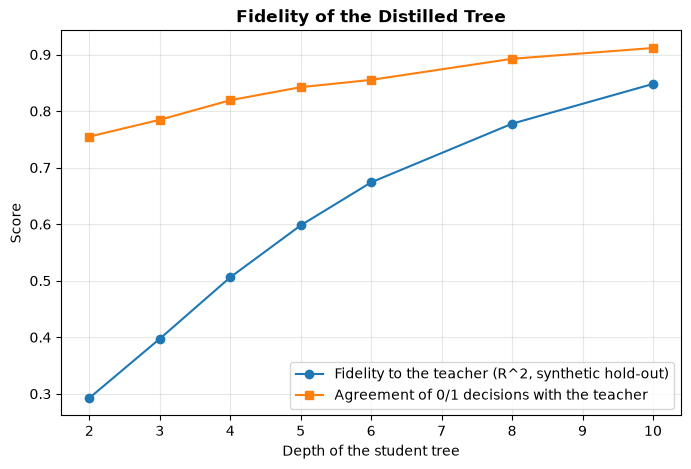

In [145]:
### --- Distillation: Student Trees Trained on the Teacher's Probabilities --- ###
def sample_parameter_space(n, rng):
    """Draw n parameter sets uniformly within the documented ranges (integers for Nq and Nm)."""
    columns = {}
    for f in feature_cols:
        lo_, hi_ = PARAM_RANGES[f]
        columns[f] = rng.integers(lo_, hi_ + 1, n).astype(float) if f in ('Nq', 'Nm') else rng.uniform(lo_, hi_, n)
    return pd.DataFrame(columns)[feature_cols]

thr_teacher = RESULTS['XGBoost']['threshold']      # F1-optimal threshold of the teacher, used for the 0/1 agreement.
rng_syn = np.random.default_rng(random_seed)
N_SYN = BUDGET['n_syn']                            # Synthetic parameter sets (three quarters to train the students, one quarter to test them).
N_SYN_TRAIN = int(0.75 * N_SYN)
X_syn = sample_parameter_space(N_SYN, rng_syn)
p_syn = best_xgb.predict_proba(X_syn)[:, 1]        # Teacher's soft labels.
X_syn_tr, X_syn_ho = X_syn.iloc[:N_SYN_TRAIN], X_syn.iloc[N_SYN_TRAIN:]
p_syn_tr, p_syn_ho = p_syn[:N_SYN_TRAIN], p_syn[N_SYN_TRAIN:]

teacher_test_proba = best_xgb.predict_proba(X_test)[:, 1]
rows = [{'model': 'Teacher (XGBoost)', 'depth': np.nan, 'leaves': np.nan, 'fidelity R2': 1.0, 'agreement with teacher': 1.0,
         'test PR AUC': average_precision_score(y_test, teacher_test_proba), 'test ROC AUC': roc_auc_score(y_test, teacher_test_proba),
         'direct tree: test PR AUC': np.nan, 'direct tree: test ROC AUC': np.nan}]

for depth in [2, 3, 4, 5, 6, 8, 10]:
    student = DecisionTreeRegressor(max_depth = depth, min_samples_leaf = 50, random_state = random_seed).fit(X_syn_tr, p_syn_tr)
    p_ho = student.predict(X_syn_ho)
    p_te = student.predict(X_test)
    direct = DecisionTreeClassifier(max_depth = depth, min_samples_leaf = 50, random_state = random_seed).fit(X_train, y_train)
    p_direct = direct.predict_proba(X_test)[:, 1]
    rows.append({'model': 'Distilled tree', 'depth': depth, 'leaves': student.get_n_leaves(),
                 'fidelity R2': r2_score(p_syn_ho, p_ho),
                 'agreement with teacher': ((p_ho >= thr_teacher) == (p_syn_ho >= thr_teacher)).mean(),
                 'test PR AUC': average_precision_score(y_test, p_te), 'test ROC AUC': roc_auc_score(y_test, p_te),
                 'direct tree: test PR AUC': average_precision_score(y_test, p_direct),
                 'direct tree: test ROC AUC': roc_auc_score(y_test, p_direct)})

distill_table = pd.DataFrame(rows)
display(distill_table.round(3))

plt.figure(figsize = (8, 5))
sub = distill_table.dropna(subset = ['depth'])
plt.plot(sub['depth'], sub['fidelity R2'], marker = 'o', label = 'Fidelity to the teacher (R^2, synthetic hold-out)')
plt.plot(sub['depth'], sub['agreement with teacher'], marker = 's', label = 'Agreement of 0/1 decisions with the teacher')
plt.xlabel('Depth of the student tree')
plt.ylabel('Score')
plt.title('Fidelity of the Distilled Tree', fontweight = 'bold')
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.3)
plt.show()

The table shows how deep the student has to be to reproduce the teacher, and whether a distilled tree beats a tree of the same size trained directly on the real labels. Below, one student is shown as rules (choose `STUDENT_DEPTH` where the fidelity curve starts to flatten, trading precision for readability). Each leaf gives the teacher's average predicted probability of polymorphism for all the parameter sets that satisfy the conditions on its path.

Student of depth 5: 32 leaves, fidelity R2 = 0.598 on held-out synthetic data.

|--- zq <= 0.566
|   |--- e <= 0.628
|   |   |--- sq <= 0.024
|   |   |   |--- sq <= -0.042
|   |   |   |   |--- zq <= 0.088
|   |   |   |   |   |--- value: [0.175]
|   |   |   |   |--- zq >  0.088
|   |   |   |   |   |--- value: [0.539]
|   |   |   |--- sq >  -0.042
|   |   |   |   |--- zq <= 0.060
|   |   |   |   |   |--- value: [0.456]
|   |   |   |   |--- zq >  0.060
|   |   |   |   |   |--- value: [0.777]
|   |   |--- sq >  0.024
|   |   |   |--- dq <= 0.332
|   |   |   |   |--- zq <= 0.363
|   |   |   |   |   |--- value: [0.693]
|   |   |   |   |--- zq >  0.363
|   |   |   |   |   |--- value: [0.356]
|   |   |   |--- dq >  0.332
|   |   |   |   |--- zq <= 0.210
|   |   |   |   |   |--- value: [0.383]
|   |   |   |   |--- zq >  0.210
|   |   |   |   |   |--- value: [0.115]
|   |--- e >  0.628
|   |   |--- sq <= 0.013
|   |   |   |--- e <= 0.762
|   |   |   |   |--- sq <= -0.030
|   |   |   |   |   |---

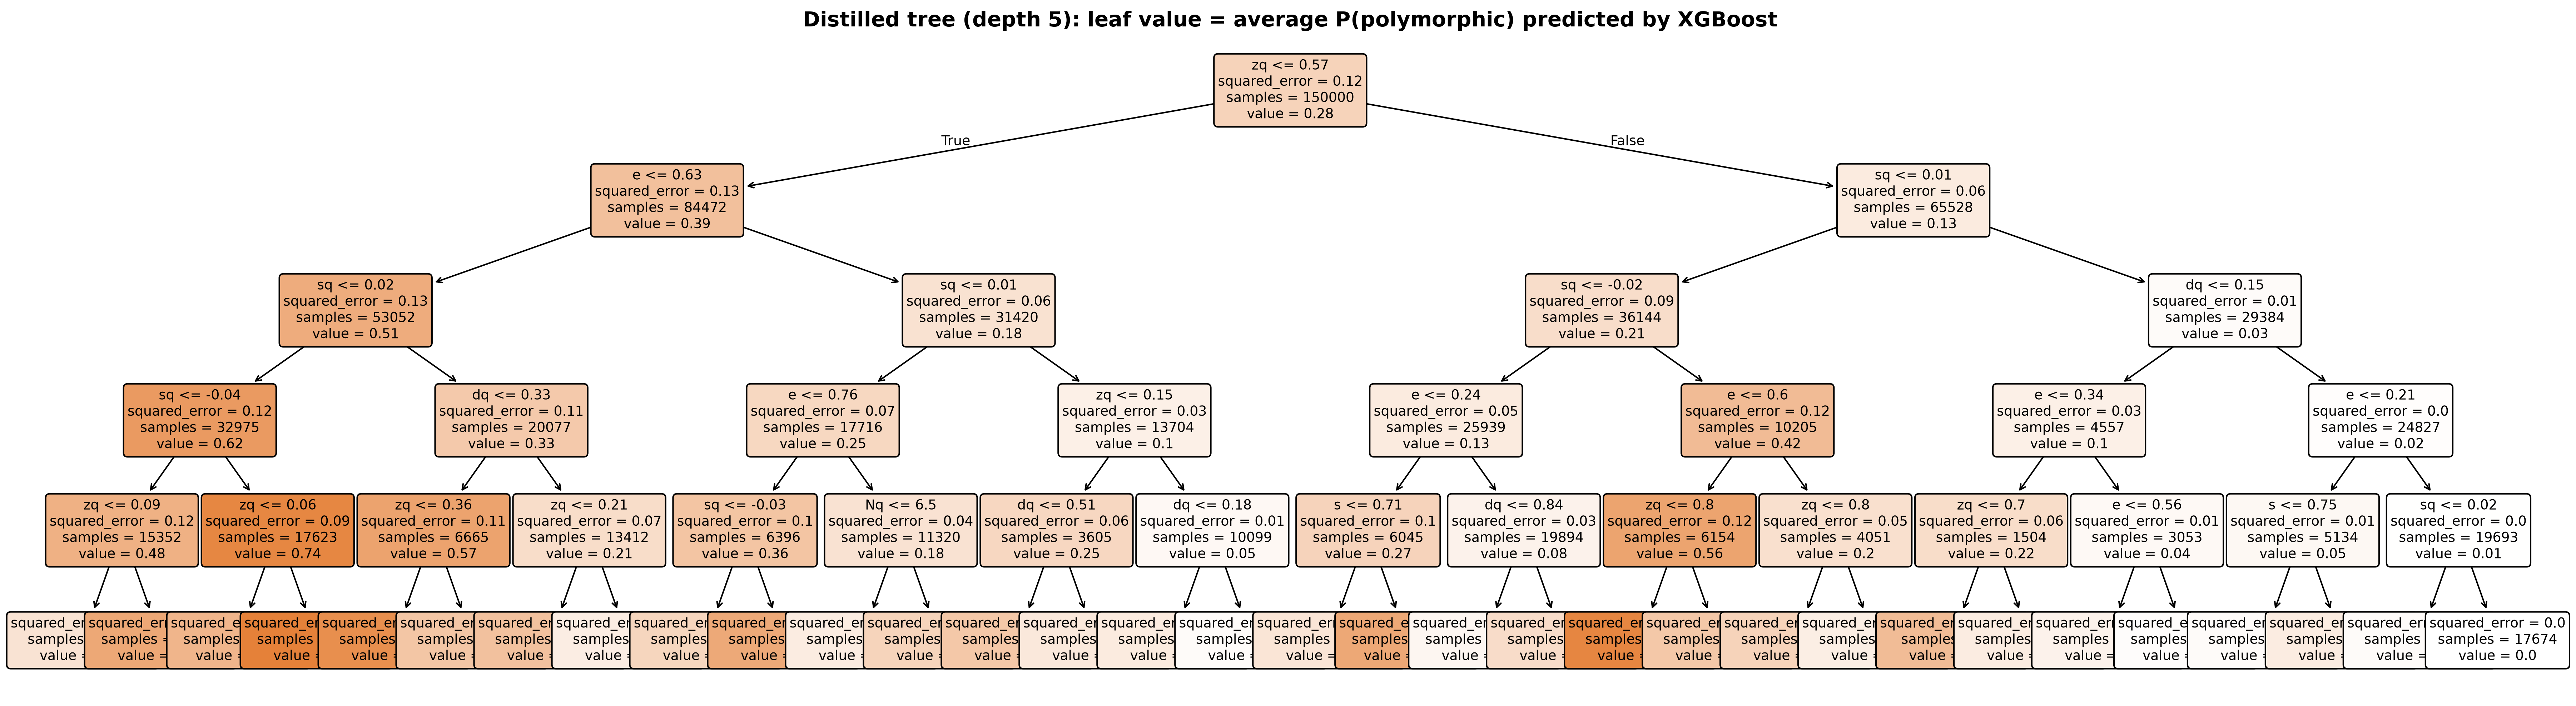

In [146]:
### --- The Chosen Student Tree as Readable Rules --- ###
STUDENT_DEPTH = 5
student = DecisionTreeRegressor(max_depth = STUDENT_DEPTH, min_samples_leaf = 50, random_state = random_seed).fit(X_syn_tr, p_syn_tr)

print(f'Student of depth {STUDENT_DEPTH}: {student.get_n_leaves()} leaves, '
      f'fidelity R2 = {r2_score(p_syn_ho, student.predict(X_syn_ho)):.3f} on held-out synthetic data.\n')
print(export_text(student, feature_names = feature_cols, decimals = 3))

plt.figure(figsize = (30, 8), dpi = 300)
plot_tree(student, feature_names = feature_cols, filled = True, rounded = True, fontsize = 9, precision = 2)
plt.title(f'Distilled tree (depth {STUDENT_DEPTH}): leaf value = average P(polymorphic) predicted by XGBoost', fontsize = 14, fontweight = 'bold')
plt.show()

> **Takeaway.** Distillation turns the black box into a handful of explicit conditions on the parameters. Compare them with the SHAP ranking and the PDPs: if the first splits of the student use the same parameters and thresholds, the three views agree. The rules are **hypotheses about the simulator**, generated by a model. The decisive test of a rule is a set of fresh simulations at parameter values chosen to confirm or contradict it (Section 15). The fidelity table also shows the limit of the approach here: a student small enough to read leaves much of the teacher's variance unexplained, so these rules describe only the coarse structure of XGBoost. Sections 14.8 to 14.10 look for better alternatives.

### **14.8 Why Did Distillation Struggle, and Which Student Fits Better?**

The depth-5 student of Section 14.7 explains only about 60% of the variance of the teacher's probabilities, and it needs hundreds of leaves to reach 85%. It is also barely better than a tree of the same depth trained directly on the real labels. This is information about the simulator, not only a weakness of the method:

1. **The boundaries are oblique.** The maps of Section 14.5 show diagonal and curved transitions between the polymorphic and non polymorphic regions. A tree can only cut parallel to the axes, so every oblique boundary has to be approximated by a staircase of splits.
2. **The interactions are numerous** (Section 14.10). No single pair closes more than about a fifth of the gap between an additive model and the full model, and about ten pairs are needed to approach the ceiling of pairwise models, so a small partition of the space cannot capture them.

Two simple changes of the student address the first point. Both are compared with the depth-limited tree **at the same number of regions**, on the same 150,000 teacher-labelled parameter sets and the same 50,000 held-out ones:

| Student | Idea |
|---|---|
| **Best-first tree** (`max_leaf_nodes`) | Grows the leaf that reduces the error most, instead of growing every branch to the same depth. The leaves are spent where the teacher varies most. |
| **Model tree** | A shallow tree cuts the space into a few regions, and **one linear equation on the teacher's log-odds is fitted in every region**. A region is no longer a constant, so a slanted boundary costs one region instead of a staircase. |

> **Note.** A region of a model tree costs ten numbers (an intercept and nine coefficients) instead of one. The comparison at equal *regions* therefore favours the model tree. What it buys is a handful of readable equations instead of dozens of thresholds.

fidelity R2  agreement with teacher  \
student                     regions                                        
Depth-limited tree          4              0.293                   0.755   
                            8              0.397                   0.785   
                            16             0.506                   0.819   
                            32             0.598                   0.842   
                            64             0.674                   0.855   
Best-first tree             4              0.317                   0.788   
                            8              0.453                   0.803   
                            16             0.557                   0.835   
                            32             0.656                   0.861   
                            64             0.719                   0.871   
Model tree (linear regions) 2              0.312                   0.785   
                            4              0.461                   0.810   
                            8              0.729                   0.885   
                            16             0.755                   0.890   

                                     test PR AUC  test ROC AUC  
student                     regions                             
Depth-limited tree          4              0.471         0.758  
                            8              0.554         0.802  
                            16             0.617         0.834  
                            32             0.675         0.868  
                            64             0.728         0.889  
Best-first tree             4              0.513         0.741  
                            8              0.591         0.809  
                            16             0.675         0.844  
                            32             0.723         0.868  
                            64             0.754         0.892  
Model tree (linear regions) 2              0.590         0.809  
                            4              0.648         0.854  
                            8              0.733         0.899  
                            16             0.761         0.906

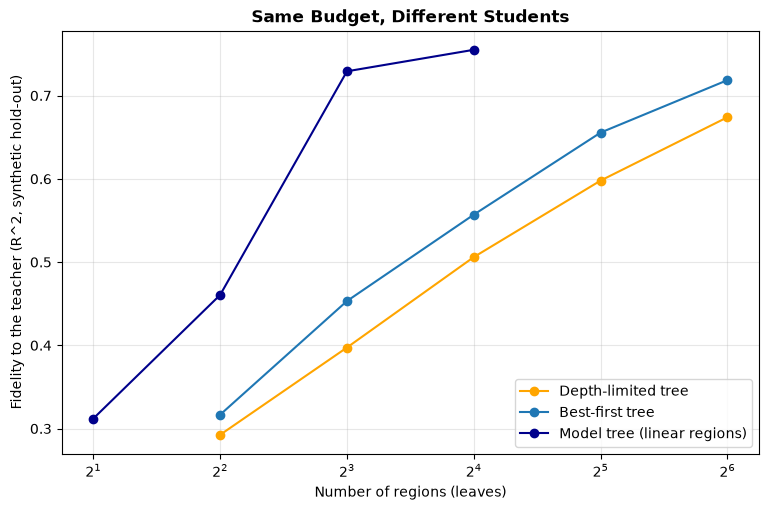

In [147]:
### --- Better Students: Best-First Trees and Model Trees at the Same Budget --- ###
def logit_clip(p, eps = 1e-3):
    """Log-odds of a probability, clipped away from 0 and 1."""
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

def fit_model_tree(X_fit, p_fit, depth, min_leaf = 2000, alpha = 1e-3):
    """Model tree: a shallow tree partitions the space, a ridge regression on the log-odds is fitted in every region."""
    partition = DecisionTreeRegressor(max_depth = depth, min_samples_leaf = min_leaf, random_state = random_seed).fit(X_fit, p_fit)
    region_of = partition.apply(X_fit)
    equations = {r: Ridge(alpha = alpha).fit(X_fit[region_of == r], logit_clip(p_fit[region_of == r])) for r in np.unique(region_of)}
    return partition, equations

def predict_model_tree(model, X_new):
    """Probability predicted by a model tree (each region applies its own linear equation on the log-odds)."""
    partition, equations = model
    region_of = partition.apply(X_new)
    out = np.zeros(len(X_new))
    for r, reg in equations.items():
        mask = region_of == r
        if mask.any():
            out[mask] = 1 / (1 + np.exp(-reg.predict(X_new[mask])))
    return out

student_rows = []
def score_student(family, regions, p_holdout, p_test):
    """Fidelity to the teacher (synthetic hold-out) and PR AUC on the real test labels."""
    student_rows.append({'student': family, 'regions': regions,
                         'fidelity R2': r2_score(p_syn_ho, p_holdout),
                         'agreement with teacher': ((p_holdout >= thr_teacher) == (p_syn_ho >= thr_teacher)).mean(),
                         'test PR AUC': average_precision_score(y_test, p_test),
                         'test ROC AUC': roc_auc_score(y_test, p_test)})

for depth in [2, 3, 4, 5, 6]:
    t = DecisionTreeRegressor(max_depth = depth, min_samples_leaf = 50, random_state = random_seed).fit(X_syn_tr, p_syn_tr)
    score_student('Depth-limited tree', t.get_n_leaves(), t.predict(X_syn_ho), t.predict(X_test))
for leaves in [4, 8, 16, 32, 64]:
    t = DecisionTreeRegressor(max_leaf_nodes = leaves, min_samples_leaf = 50, random_state = random_seed).fit(X_syn_tr, p_syn_tr)
    score_student('Best-first tree', t.get_n_leaves(), t.predict(X_syn_ho), t.predict(X_test))
for depth in [1, 2, 3, 4]:
    mt = fit_model_tree(X_syn_tr, p_syn_tr, depth)
    score_student('Model tree (linear regions)', len(mt[1]), predict_model_tree(mt, X_syn_ho), predict_model_tree(mt, X_test))

student_table = pd.DataFrame(student_rows)
display(student_table.round(3).set_index(['student', 'regions']))

plt.figure(figsize = (9, 5.5))
for family, color in [('Depth-limited tree', 'orange'), ('Best-first tree', 'tab:blue'), ('Model tree (linear regions)', 'darkblue')]:
    sub = student_table[student_table['student'] == family]
    plt.plot(sub['regions'], sub['fidelity R2'], marker = 'o', color = color, label = family)
plt.xscale('log', base = 2)
plt.xlabel('Number of regions (leaves)')
plt.ylabel('Fidelity to the teacher (R^2, synthetic hold-out)')
plt.title('Same Budget, Different Students', fontweight = 'bold')
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.3)
plt.show()

> **Takeaway.** At the same number of leaves, a best-first tree follows the teacher better than a depth-limited tree, simply because its leaves are not wasted on flat regions. A **model tree with only eight regions beats a 64-leaf tree** (fidelity R^2 0.73, against 0.72 for the best-first tree and 0.67 for the depth-limited tree with 64 leaves), which confirms that most of the trouble comes from oblique boundaries. Its fidelity then flattens (0.76 with 16 regions). Even so, none of these students approaches the fidelity of the teacher with a handful of rules: the next section asks whether a different kind of readable model does better than any student.

### **14.9 A Glass-Box Alternative: the Explainable Boosting Machine**

Distillation tries to *copy* a black box into a readable form. Another route is to ask whether a model that is **readable by construction** can match the black box in the first place. The **Explainable Boosting Machine (EBM)** is a boosted additive model:

$$\text{log-odds} = \beta_0 + \sum_j f_j(x_j) + \sum_{(j,k)} f_{jk}(x_j, x_k)$$

- $\beta_0$: The global intercept (ebm.intercept_ in InterpretML).
- $f_j(x_j)$: The learned shape function (term score) for feature $x_{j}$, built from boosted single-feature trees.
- $f_{jk}(x_j, x_k)$: The learned term score for an interaction pair $(x_j, x_k)$, if pairwise interactions are included.


Every term is a small function of one feature (a **shape function**) or of two features (a **heat map**) that can be plotted and read directly. The trees inside are only used to learn these functions, one feature at a time and with a very small learning rate, so the model never mixes more than two features in a term. A first automatic step (FAST) chooses which pairs are worth adding.

This matters for the point raised about **SHAP interaction values**. They give a Shapley credit to *every* pair of features, which raises the number of "players" from 9 to 45 and stacks one more assumption on top of an approximate model (Section 14). In the EBM, the pairs are **few, chosen on the data, and part of the model itself**: nothing is decomposed afterwards, and a term's contribution is read straight off its plot.

The number of pairs is tuned with the common protocol of Section 7.1 (5-fold CV, ROC AUC as the primary metric), from 0 (purely additive model) to 20. The EBM is registered with the other models, so the usual train / validation / test table is printed.

> **Note.** `interpret` is not pre-installed on Google Colab; the import cell installs it if needed. This search is the slowest cell of Section 14, because every candidate is an ensemble of boosted models. Remove the largest value of `interactions` to shorten it.

In [148]:
### --- Best Explainable Boosting Machine (Common Protocol) --- ###
ebm_space = {'interactions': BUDGET['ebm_interactions']}
ebm_rationale = {
    'interactions': 'Number of pairwise terms added to the nine main effects. 0 = purely additive model (a GAM). The pairs are '
                    'chosen by the EBM itself (FAST). 20 is far below the 36 possible pairs, so the model stays readable.',
}

best_ebm_model = tune_model('EBM', ExplainableBoostingClassifier(random_state = random_seed, n_jobs = 1, outer_bags = BUDGET['ebm_outer_bags']),
                            ebm_space, ebm_rationale, n_iter = None)
display(hyperparam_table('EBM'))
display(RESULTS['EBM']['search_cv'][['param_interactions', 'mean_test_pr_auc', 'mean_test_roc_auc']]
        .rename(columns = {'param_interactions': 'pairs', 'mean_test_pr_auc': 'search PR AUC', 'mean_test_roc_auc': 'search ROC AUC'})
        .round(4).set_index('pairs'))
print('Terms of the selected EBM:', ', '.join(best_ebm_model.term_names_))


--- EBM: 4 configuration(s) x 5 folds searched on 10,693 rows, selected on ROC AUC; scores below: 5-fold CV on all 10,693 training rows ---
Selected hyperparameters: {'interactions': 20}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.9672,0.9869
Validation (mean of the 5 validation folds),0.9082,0.9623
Validation (sd across the 5 folds),0.0079,0.0040
Test (held-out set),0.9040,0.9591


Random classifier: PR AUC = 0.280  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.434


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.818,0.850,0.834,0.768,0.888
test set,0.820,0.805,0.813,0.740,0.868


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,EBM,interactions,"[0, 5, 10, 20]",20,at upper cap,Number of pairwise terms added to the nine main effects. 0 = purely additive model (a GAM). The pairs are chosen by ...


,search PR AUC,search ROC AUC
pairs,,
0,0.7392,0.8771
5,0.8623,0.9423
10,0.9042,0.9608
20,0.9082,0.9623


Terms of the selected EBM: s, e, m, zq, dw, dq, sq, Nq, Nm, s & e, s & zq, s & dw, s & sq, e & m, e & zq, e & dq, e & sq, e & Nq, m & zq, m & dq, m & Nq, zq & dq, zq & sq, zq & Nq, zq & Nm, dw & dq, dw & sq, dq & sq, sq & Nq


In [149]:
### --- Does the Glass Box Lose Anything? Comparison With XGBoost --- ###
p_ebm = best_ebm_model.predict_proba(X_test)[:, 1]
p_teacher = best_xgb.predict_proba(X_test)[:, 1]
y_arr = y_test.to_numpy()
thr_teacher = RESULTS['XGBoost']['threshold']       # F1-optimal threshold of the teacher (also used for the 0/1 agreement below).

# Paired bootstrap on the test set (1,000 resamples, same resamples for both models).
rng_ebm = np.random.default_rng(random_seed)
resamples = rng_ebm.integers(0, len(y_arr), size = (BUDGET['n_boot'], len(y_arr)))
d_pr = np.array([average_precision_score(y_arr[i], p_ebm[i]) - average_precision_score(y_arr[i], p_teacher[i]) for i in resamples])
d_auc = np.array([roc_auc_score(y_arr[i], p_ebm[i]) - roc_auc_score(y_arr[i], p_teacher[i]) for i in resamples])

compare = pd.DataFrame({
    'test PR AUC': [average_precision_score(y_test, p_teacher), average_precision_score(y_test, p_ebm)],
    'test ROC AUC': [roc_auc_score(y_test, p_teacher), roc_auc_score(y_test, p_ebm)],
    'Brier score': [brier_score_loss(y_test, p_teacher), brier_score_loss(y_test, p_ebm)],
    'log loss': [log_loss(y_test, p_teacher), log_loss(y_test, p_ebm)],
}, index = ['XGBoost (black box)', 'EBM (glass box)'])
display(compare.round(4))
print(f'EBM minus XGBoost, test PR AUC:  {d_pr.mean():+.4f}  [95% CI {np.percentile(d_pr, 2.5):+.4f}, {np.percentile(d_pr, 97.5):+.4f}]')
print(f'EBM minus XGBoost, test ROC AUC: {d_auc.mean():+.4f}  [95% CI {np.percentile(d_auc, 2.5):+.4f}, {np.percentile(d_auc, 97.5):+.4f}]')

# Fidelity, measured exactly like the students of Sections 14.7 and 14.8 (EBM trained on the real labels, not on the teacher's).
p_ebm_ho = best_ebm_model.predict_proba(X_syn_ho)[:, 1]
print(f'Fidelity of the EBM to XGBoost on the synthetic hold-out: R^2 = {r2_score(p_syn_ho, p_ebm_ho):.3f}, '
      f'agreement of the 0/1 decisions (at the teacher threshold {thr_teacher:.3f}) = {((p_ebm_ho >= thr_teacher) == (p_syn_ho >= thr_teacher)).mean():.3f}')


,test PR AUC,test ROC AUC,Brier score,log loss
XGBoost (black box),0.9092,0.9625,0.0707,0.2271
EBM (glass box),0.9040,0.9591,0.0735,0.2310


EBM minus XGBoost, test PR AUC:  -0.0051  [95% CI -0.0185, +0.0084]
EBM minus XGBoost, test ROC AUC: -0.0034  [95% CI -0.0088, +0.0020]
Fidelity of the EBM to XGBoost on the synthetic hold-out: R^2 = 0.935, agreement of the 0/1 decisions (at the teacher threshold 0.383) = 0.954


**Reading the EBM.** The first figure ranks the terms by their mean absolute contribution to the log-odds (main effects in one colour, pairs in another). The second shows the shape function of every main effect: the line is the contribution to the log-odds (above 0 favours polymorphism), and the band is the variation between the bagged models that the EBM averages, a direct measure of how well the data constrain that part of the curve. The third shows the strongest pairs as heat maps: **a pair term is what remains once the two main effects have been taken out**, so a blank map means that the two features act additively. Unlike a partial dependence plot, the contribution of a term does not change with the other features.

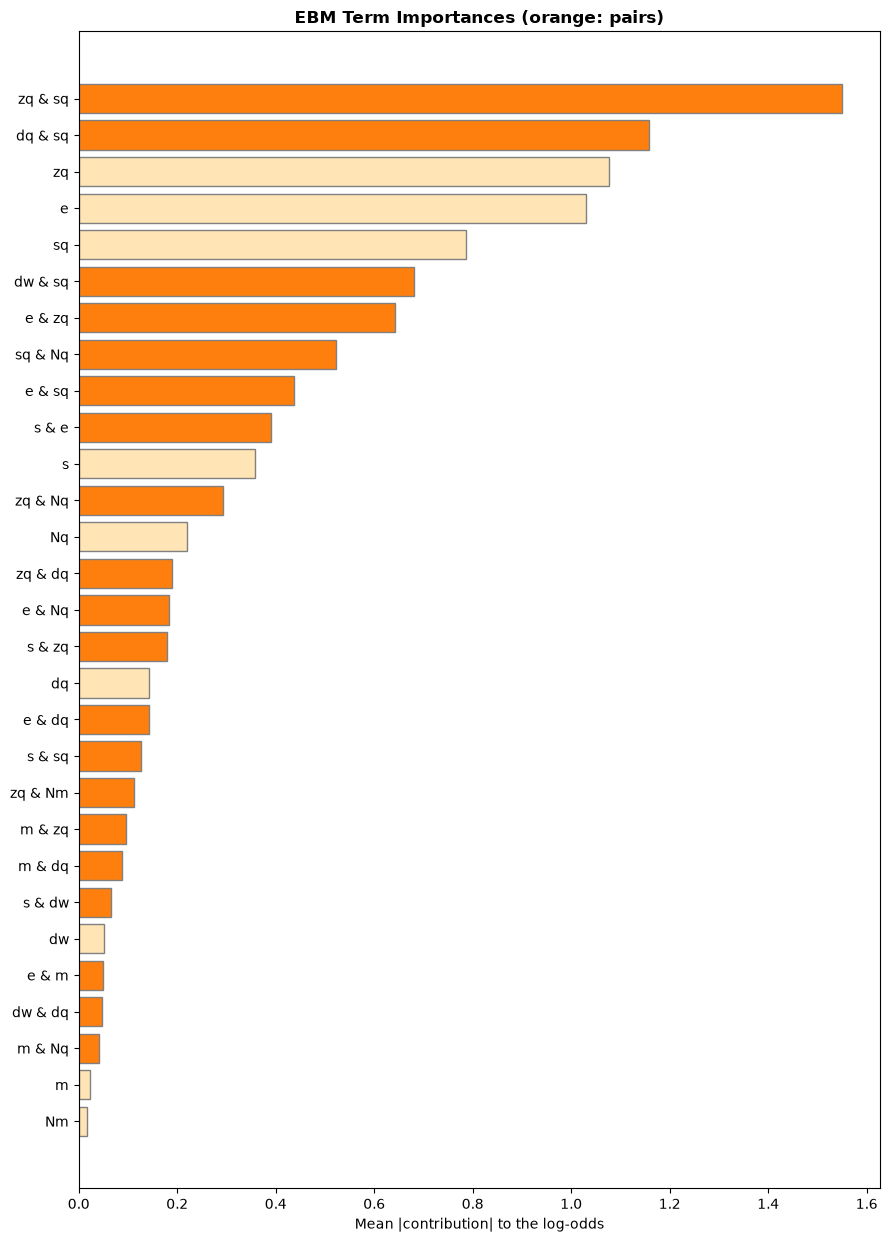

Main effects, most important first: zq, e, sq, s, Nq, dq, dw, m, Nm


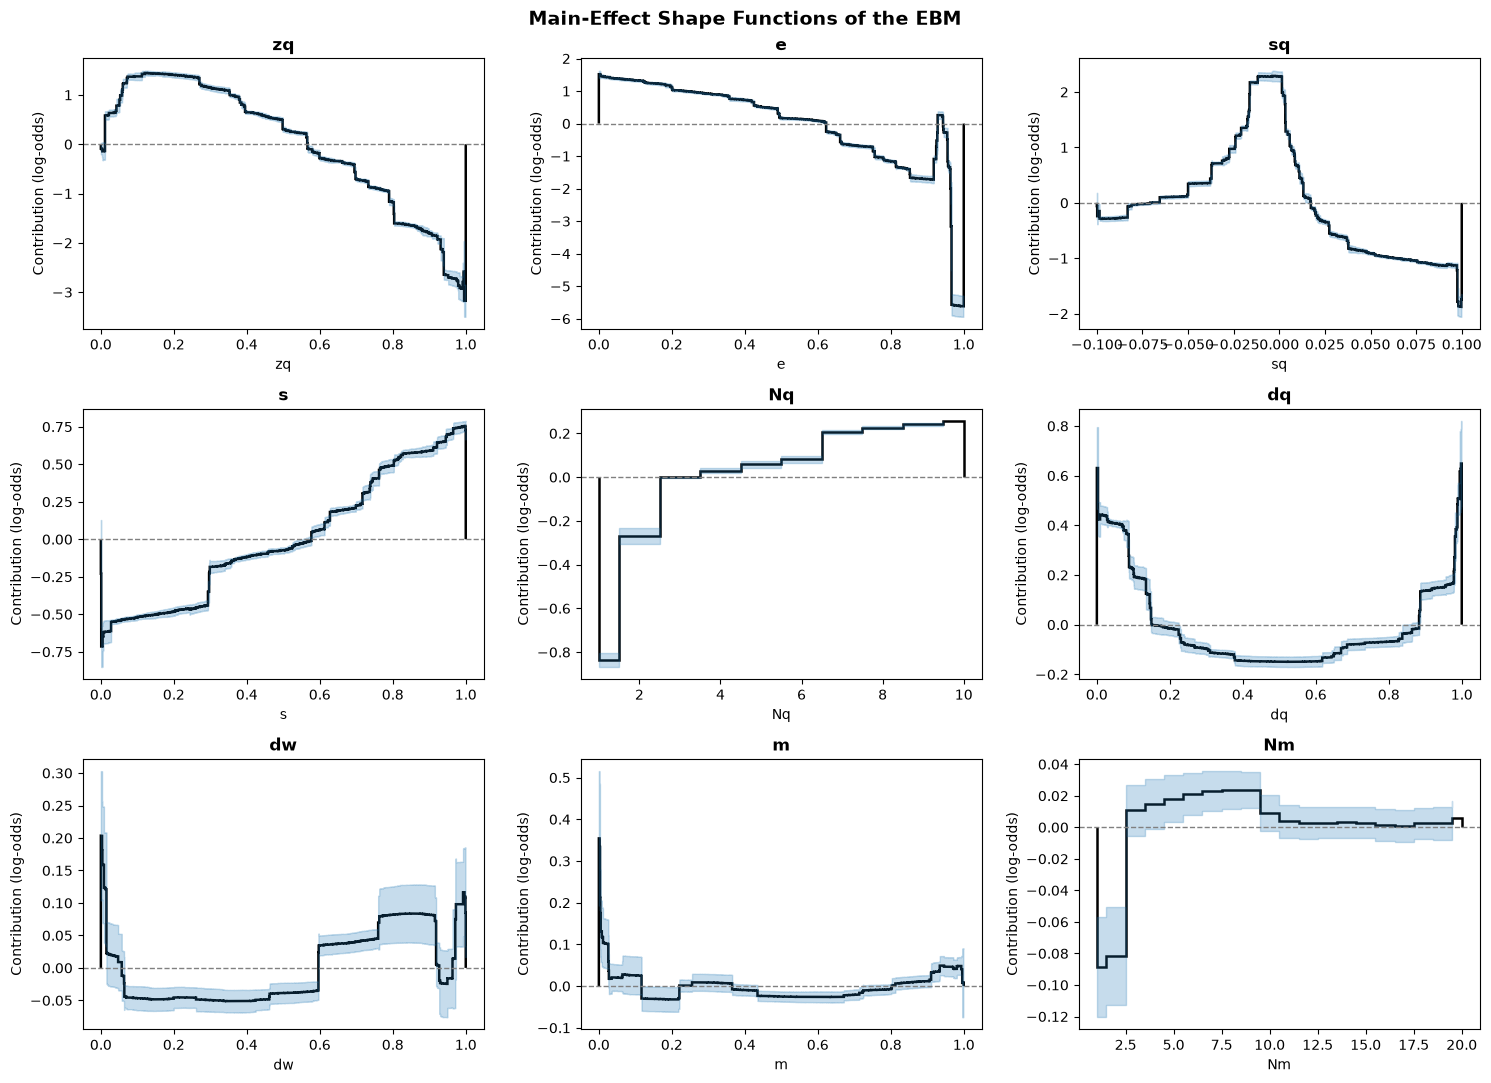

In [150]:
### --- Term Importances and Main-Effect Shape Functions of the EBM --- ###
ebm_global = best_ebm_model.explain_global()
term_names = list(best_ebm_model.term_names_)
term_importance = pd.Series(best_ebm_model.term_importances(), index = term_names).sort_values()

plt.figure(figsize = (9, 0.38 * len(term_importance) + 1.5))
plt.barh(term_importance.index, term_importance.values,
         color = ['tab:orange' if ' & ' in n else 'moccasin' for n in term_importance.index], edgecolor = 'gray')
plt.xlabel('Mean |contribution| to the log-odds')
plt.title('EBM Term Importances (orange: pairs)', fontweight = 'bold')
plt.tight_layout()
plt.show()

main_order = [n for n in term_importance.sort_values(ascending = False).index if ' & ' not in n]
print('Main effects, most important first:', ', '.join(main_order))
fig, axes = plt.subplots(3, 3, figsize = (15, 11))
for ax, name in zip(axes.ravel(), main_order):
    d = ebm_global.data(term_names.index(name))
    edges, score = np.asarray(d['names'], dtype = float), np.asarray(d['scores'], dtype = float)
    ax.stairs(score, edges, color = 'black', linewidth = 1.8)
    ax.fill_between(edges[:-1], d['lower_bounds'], d['upper_bounds'], step = 'post', color = 'tab:blue', alpha = 0.25)
    ax.axhline(0, color = 'gray', linestyle = '--', linewidth = 1)
    ax.set_title(name, fontweight = 'bold')
    ax.set_xlabel(name)
    ax.set_ylabel('Contribution (log-odds)')
fig.suptitle('Main-Effect Shape Functions of the EBM', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

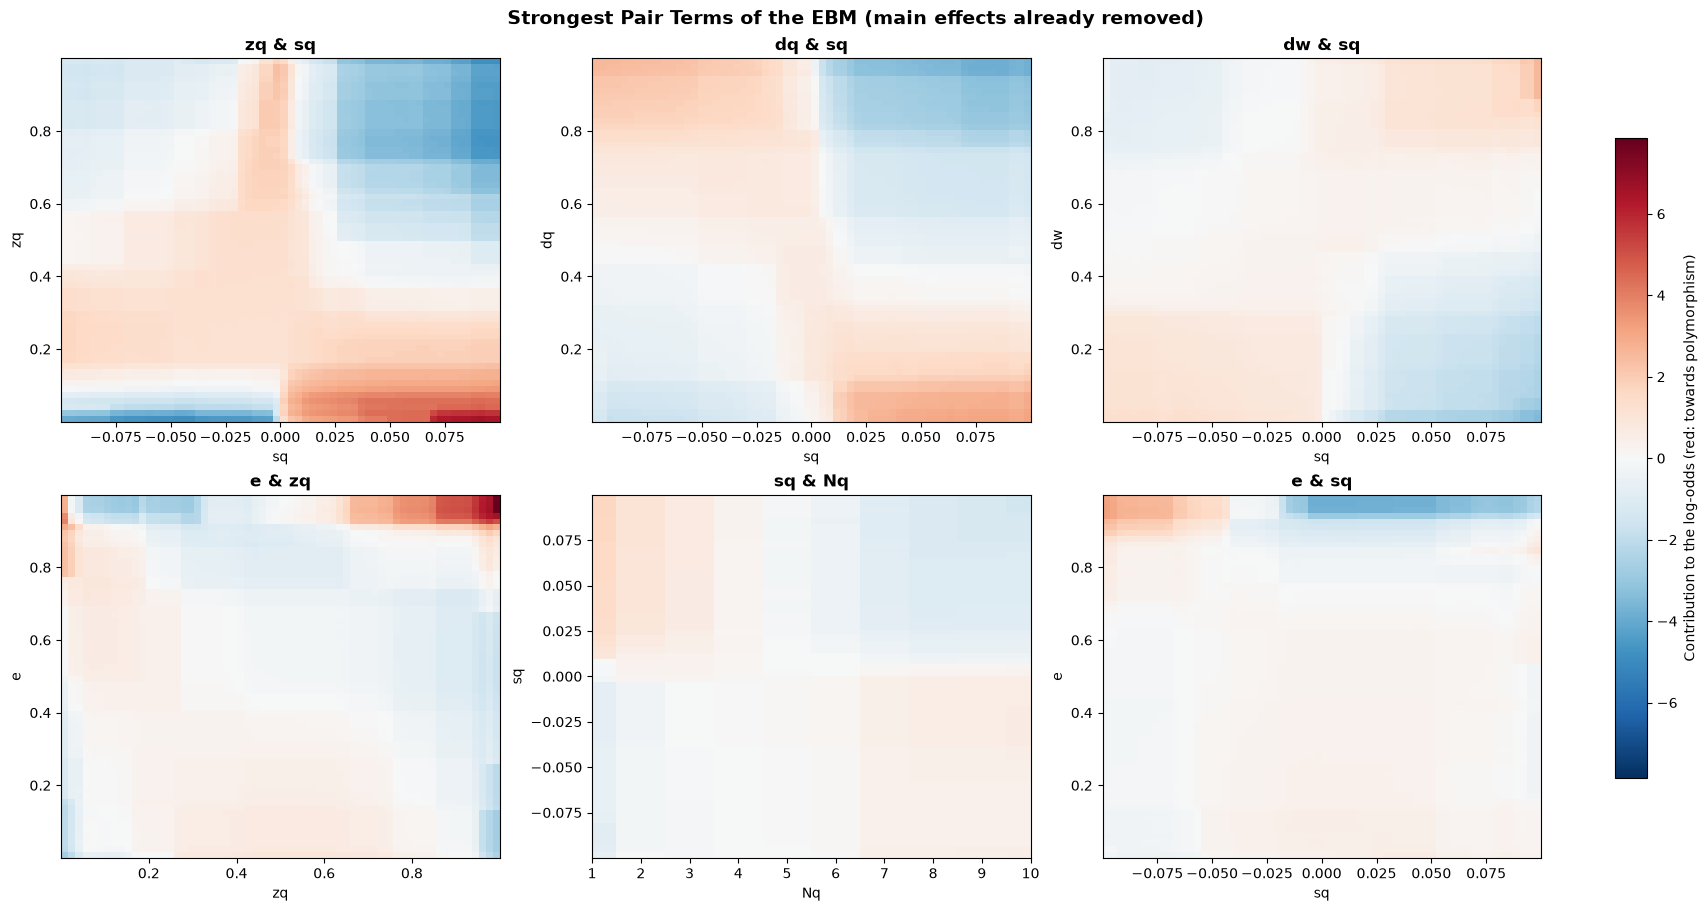

In [151]:
### --- Strongest Pair Terms of the EBM as Heat Maps --- ###
pair_terms = [n for n in term_importance.sort_values(ascending = False).index if ' & ' in n][:6]
if not pair_terms:
    print('The selected EBM has no pair term (interactions = 0), so there is no heat map to show.')
else:
    fig, axes = plt.subplots(2, 3, figsize = (17, 9), layout = 'constrained')
    limit = max(np.abs(np.asarray(ebm_global.data(term_names.index(n))['scores'], dtype = float)).max() for n in pair_terms)
    for ax, name in zip(axes.ravel(), pair_terms):
        d = ebm_global.data(term_names.index(name))
        f_left, f_right = name.split(' & ')                # Rows follow the first feature, columns the second.
        im = ax.pcolormesh(np.asarray(d['right_names'], dtype = float), np.asarray(d['left_names'], dtype = float),
                           np.asarray(d['scores'], dtype = float), cmap = 'RdBu_r', vmin = -limit, vmax = limit, shading = 'flat')
        ax.set_xlabel(f_right); ax.set_ylabel(f_left)
        ax.set_title(name, fontweight = 'bold')
    for ax in axes.ravel()[len(pair_terms):]:
        ax.set_visible(False)
    fig.colorbar(im, ax = axes, shrink = 0.8, label = 'Contribution to the log-odds (red: towards polymorphism)')
    fig.suptitle('Strongest Pair Terms of the EBM (main effects already removed)', fontsize = 14, fontweight = 'bold')
    plt.show()

> **Takeaway.** The EBM is the readable model that distillation could not provide: its test accuracy and ROC AUC are statistically indistinguishable from XGBoost's (the paired bootstrap interval contains 0), while every part of its prediction is a plot that can be read. Its main effects can be compared with the SHAP ranking of Section 14.2 (the printed order of the main effects), and the pair terms it selected are the interactions to look at in Section 14.10. The search selects the largest number of pairs offered, but the gain over the 10-pair model is small (see the validation table), so the strongest pairs shown above carry most of the interaction content.
>
> **Limits.** The EBM, like every model here, describes the simulator only inside the explored ranges, and a term shown as a heat map is as good as the data in its cells (see the bands of the shape functions and the sparse coverage of Section 6.3). The pair terms are the *model's* decomposition; Section 14.10 checks them against a second, independent screen and against the raw data.

### **14.10 Which Parameters Interact? A Screen Without SHAP Interaction Values**

Section 14.5 looked at the three pairs formed by the three most important parameters. That choice is arbitrary: the parameters that interact most are not necessarily the ones that matter most on their own. A screen over *all* 36 pairs needs a tool that does not rely on Shapley credit, so we use **constrained boosting**, which only needs the data:

1. **Additive ceiling.** Boosted trees of depth 1 (stumps) cannot represent any interaction, so they are an additive model. Their cross-validated score is the ceiling of what the nine parameters can do *without* interacting.
2. **One pair at a time.** A boosted model of depth 2 in which **only one chosen pair of features may appear together in a branch** (`interaction_constraints`), all the other features being kept additive. The improvement in cross-validated log loss over the additive ceiling is the strength of that pair. This is repeated for the 36 pairs, with the common 5 folds.
3. **Cumulative curve.** The best pairs are added one after the other to see how many are needed to close the gap between the additive model and the full model (depth 6).

Gains of different pairs are **not additive** (two pairs can share the same information), so they are used only to rank the pairs. The EBM pairs of Section 14.9 give a second ranking, obtained with a different model family.

                    CV log loss  CV PR AUC
Additive (depth 1)       0.3887     0.7408
Any pair (depth 2)       0.2348     0.9006
Full (depth 6)           0.2033     0.9253
Letting every pair interact closes 83% of the gap between the additive and the full model; the rest needs three or more parameters at once.



,f1,f2,log loss gain,PR AUC gain,share of additive-to-full gap,EBM importance
0,dq,sq,0.034,0.044,0.185,1.158
1,zq,sq,0.032,0.043,0.173,1.550
2,e,zq,0.014,0.010,0.078,0.643
3,dw,sq,0.013,0.017,0.070,0.680
4,e,sq,0.007,0.005,0.037,0.437
5,zq,Nq,0.006,0.005,0.035,0.292
6,s,e,0.006,0.008,0.033,0.390
7,sq,Nq,0.005,0.007,0.026,0.523
8,e,Nq,0.004,0.002,0.021,0.182
9,zq,dq,0.004,0.003,0.020,0.189


Spearman correlation between the screen and the EBM importances over the 36 pairs: 0.87
4 of the 5 strongest pairs of the screen are also among the 5 strongest pairs of the EBM.
The strongest single pair closes 19% of the gap between the additive and the full model.


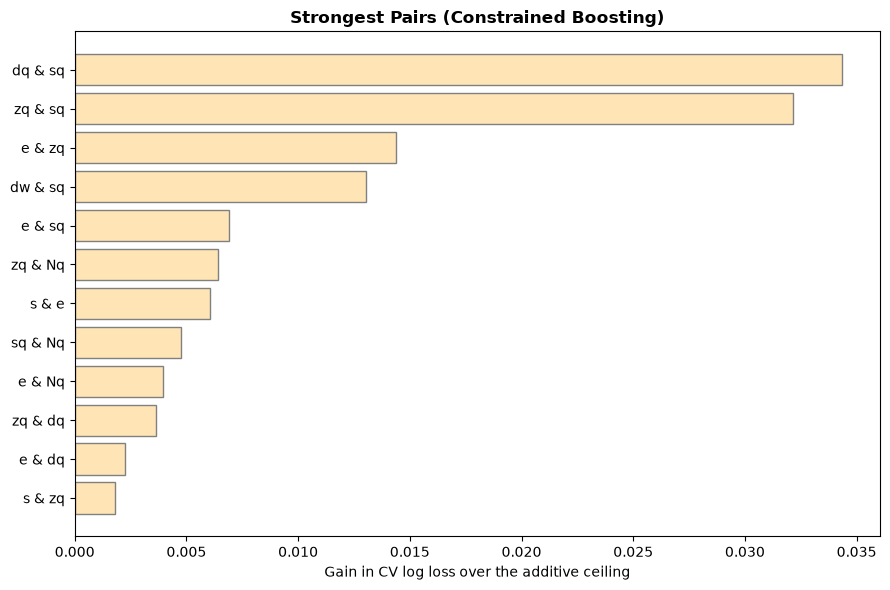

In [152]:
### --- Interaction Screen: Additive Ceiling and One Pair at a Time (Constrained Boosting) --- ###
SCREEN_ROWS, SCREEN_FOLDS = BUDGET['screen_rows'], BUDGET['screen_folds']
if len(X_train) > SCREEN_ROWS:
    X_scr, _, y_scr, _ = train_test_split(X_train, y_train, train_size = SCREEN_ROWS, stratify = y_train, random_state = random_seed)
else:                                     # The whole training set is already small enough.
    X_scr, y_scr = X_train, y_train
SCREEN_CV = StratifiedKFold(n_splits = SCREEN_FOLDS, shuffle = True, random_state = random_seed)

def cv_boosting(constraints, depth):
    """Mean CV log loss and PR AUC of a small boosted model on the screening subsample.

    `constraints` lists the groups of features allowed to appear together in a branch (None = no restriction).
    Every model is trained until an inner hold-out (15% of its training fold) stops improving, so that no model is
    penalised by too few trees: stumps and depth-2 trees need many more rounds than deep trees.
    """
    losses, prs = [], []
    for tr, va in SCREEN_CV.split(X_scr, y_scr):
        X_fit, X_stop, y_fit, y_stop = train_test_split(X_scr.iloc[tr], y_scr.iloc[tr], test_size = 0.15,
                                                        stratify = y_scr.iloc[tr], random_state = random_seed)
        m = XGBClassifier(n_estimators = 4000, max_depth = depth, learning_rate = 0.1, subsample = 0.7,
                          min_child_weight = 5, reg_lambda = 5, interaction_constraints = constraints,
                          early_stopping_rounds = 50, random_state = random_seed, eval_metric = 'logloss', n_jobs = -1)
        m.fit(X_fit, y_fit, eval_set = [(X_stop, y_stop)], verbose = False)
        p = m.predict_proba(X_scr.iloc[va])[:, 1]
        losses.append(log_loss(y_scr.iloc[va], p)); prs.append(average_precision_score(y_scr.iloc[va], p))
    return np.mean(losses), np.mean(prs)


additive_ll, additive_pr = cv_boosting(None, depth = 1)       # Stumps: no interaction is possible.
full_ll, full_pr = cv_boosting(None, depth = 6)               # Everything may interact.
pairwise_ll, pairwise_pr = cv_boosting(None, depth = 2)       # Any pair may interact, nothing higher.
gap = additive_ll - full_ll
print(pd.DataFrame({'CV log loss': [additive_ll, pairwise_ll, full_ll], 'CV PR AUC': [additive_pr, pairwise_pr, full_pr]},
                   index = ['Additive (depth 1)', 'Any pair (depth 2)', 'Full (depth 6)']).round(4).to_string())
print(f'Letting every pair interact closes {(additive_ll - pairwise_ll) / gap:.0%} of the gap between the additive and the full model; '
      f'the rest needs three or more parameters at once.\n')

rows = []
for f1, f2 in itertools.combinations(feature_cols, 2):
    groups = [[f] for f in feature_cols if f not in (f1, f2)] + [[f1, f2]]
    ll, pr = cv_boosting(groups, depth = 2)
    rows.append({'f1': f1, 'f2': f2, 'log loss gain': additive_ll - ll, 'PR AUC gain': pr - additive_pr})
pair_table = pd.DataFrame(rows).sort_values('log loss gain', ascending = False).reset_index(drop = True)
pair_table['share of additive-to-full gap'] = pair_table['log loss gain'] / gap
ebm_pair_importance = {frozenset(n.split(' & ')): v for n, v in zip(best_ebm_model.term_names_, best_ebm_model.term_importances()) if ' & ' in n}
pair_table['EBM importance'] = [ebm_pair_importance.get(frozenset((a, b)), 0.0) for a, b in zip(pair_table['f1'], pair_table['f2'])]
display(pair_table.head(12).round(3))

# Second, independent ranking: the EBM importance of every pair (0 if the EBM did not select it).
rho = stats.spearmanr(pair_table['log loss gain'], pair_table['EBM importance']).correlation
top5_screen = set(zip(pair_table['f1'].head(5), pair_table['f2'].head(5)))
ebm_top = pair_table.sort_values('EBM importance', ascending = False).head(5)
top5_ebm = set(zip(ebm_top['f1'], ebm_top['f2']))
print(f'Spearman correlation between the screen and the EBM importances over the {len(pair_table)} pairs: {rho:.2f}')
print(f'{len(top5_screen & top5_ebm)} of the 5 strongest pairs of the screen are also among the 5 strongest pairs of the EBM.')
print(f'The strongest single pair closes {pair_table["share of additive-to-full gap"].iloc[0]:.0%} of the gap between the additive and the full model.')

top = pair_table.head(12).iloc[::-1]
plt.figure(figsize = (9, 6))
plt.barh([f'{a} & {b}' for a, b in zip(top['f1'], top['f2'])], top['log loss gain'], color = 'moccasin', edgecolor = 'gray')
plt.xlabel('Gain in CV log loss over the additive ceiling')
plt.title('Strongest Pairs (Constrained Boosting)', fontweight = 'bold')
plt.tight_layout()
plt.show()

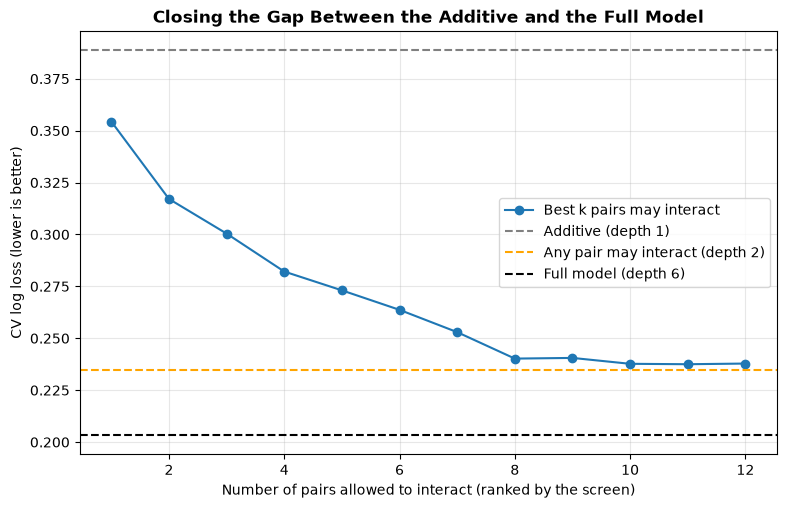

Share of the additive-to-full gap closed: all pairs 83%, best 5 pairs 62%, best 10 pairs 81%.


In [158]:
### --- How Many Pairs Are Needed? Cumulative Curve --- ###
ranked_pairs = list(zip(pair_table['f1'], pair_table['f2']))
curve = []
for k in range(1, BUDGET['n_curve_pairs'] + 1):
    chosen = ranked_pairs[:k]
    used = {f for pair in chosen for f in pair}
    groups = [list(pair) for pair in chosen] + [[f] for f in feature_cols if f not in used]
    curve.append(cv_boosting(groups, depth = 2)[0])

plt.figure(figsize = (9, 5.5))
plt.plot(range(1, len(curve) + 1), curve, marker = 'o', color = 'tab:blue', label = 'Best k pairs may interact')
plt.axhline(additive_ll, color = 'gray', linestyle = '--', label = 'Additive (depth 1)')
plt.axhline(pairwise_ll, color = 'orange', linestyle = '--', label = 'Any pair may interact (depth 2)')
plt.axhline(full_ll, color = 'black', linestyle = '--', label = 'Full model (depth 6)')
plt.xlabel('Number of pairs allowed to interact (ranked by the screen)')
plt.ylabel('CV log loss (lower is better)')
plt.title('Closing the Gap Between the Additive and the Full Model', fontweight = 'bold')
plt.legend()
plt.grid(alpha = 0.3)
plt.show()
closed = ', '.join(f'best {k} pairs {(additive_ll - curve[k - 1]) / gap:.0%}' for k in (5, 10) if k <= len(curve))
print(f'Share of the additive-to-full gap closed: all pairs {(additive_ll - pairwise_ll) / gap:.0%}, {closed}.')

Two of the strongest pairs, **`dq` x `sq` and `dw` x `sq`** (dominance of the allele in each caste against the size of its effect), were not among the pairs examined in Section 14.5. They are exactly the pairs that the dominance hypothesis of Section 14.6 is about, so they deserve the same check against the raw data: the observed polymorphism rate in bins (no model) on the left, the partial dependence of XGBoost in the middle, and the agreement between the two on the right.

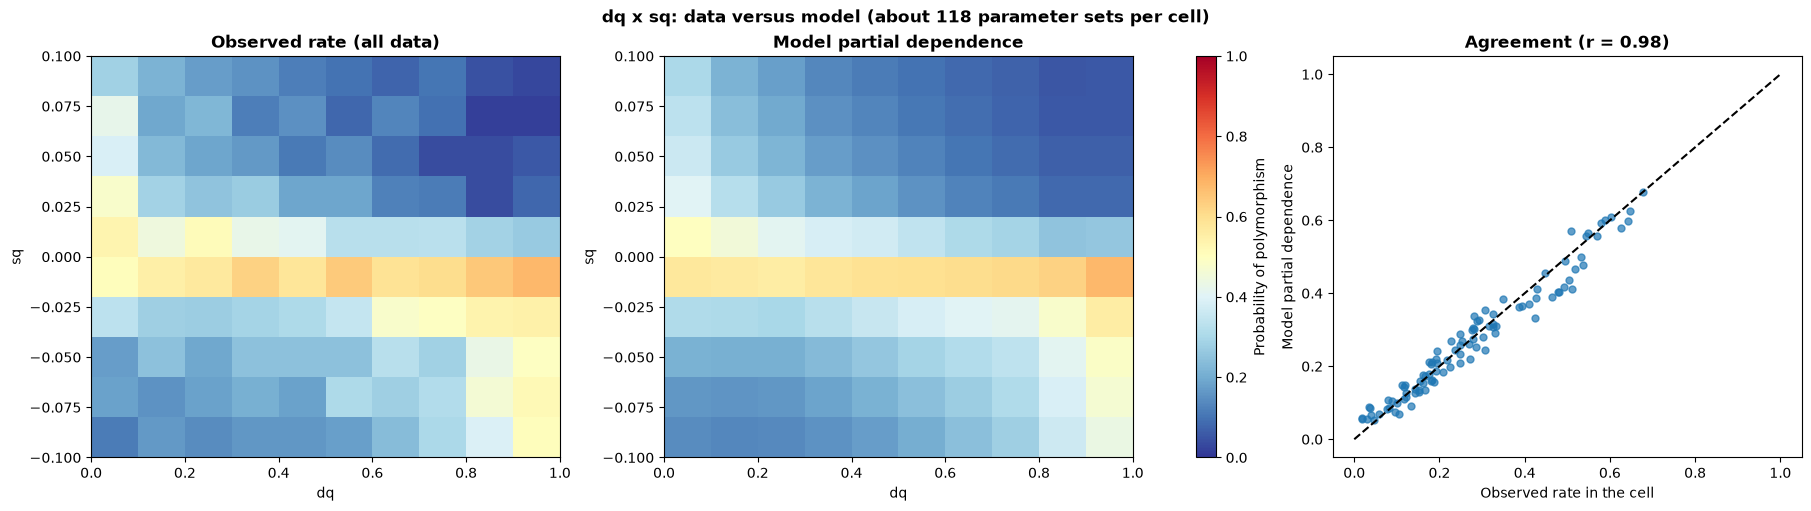

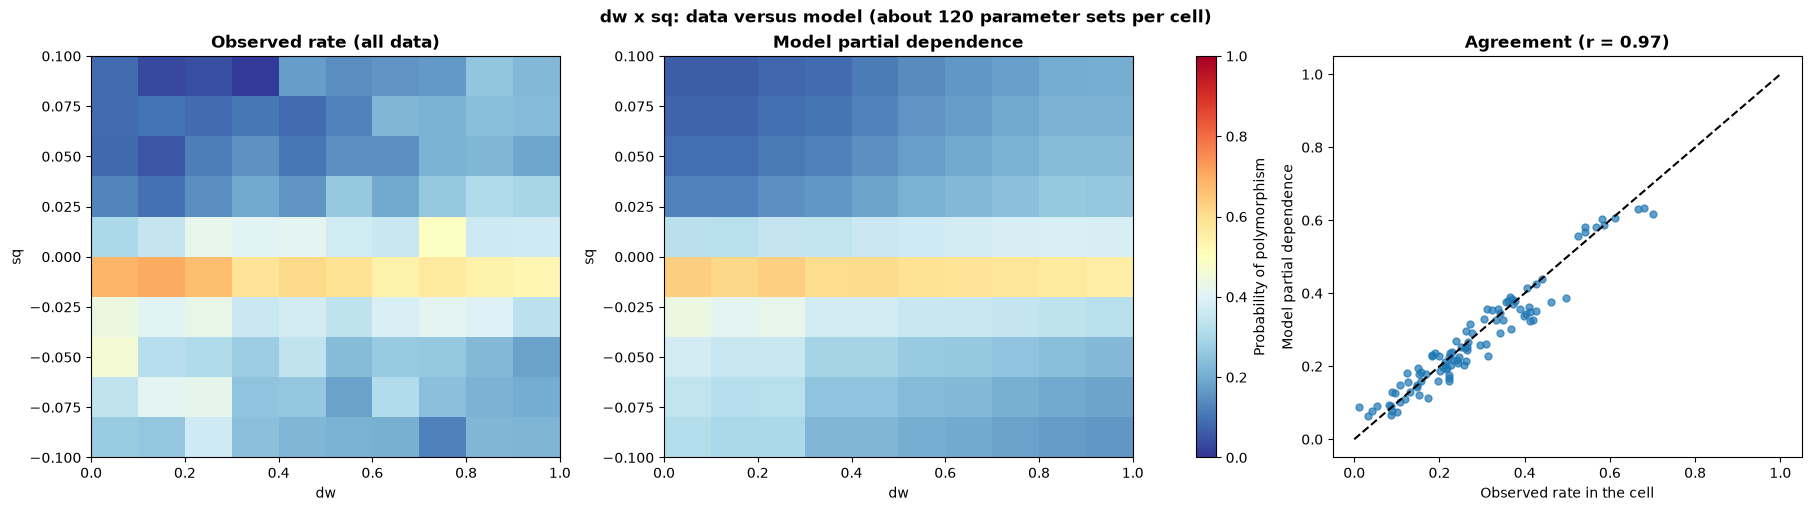

In [154]:
### --- Observed Rate Versus Model Partial Dependence for the Strongest New Pairs --- ###
already_checked = {frozenset(p) for p in itertools.combinations(top3, 2)}          # The pairs of Section 14.5.
new_pairs = [(a, b) for a, b in zip(pair_table['f1'], pair_table['f2']) if frozenset((a, b)) not in already_checked][:2]

for f1, f2 in new_pairs:
    g1, g2 = bin_centers(f1, n_bins_pair), bin_centers(f2, n_bins_pair)
    emp, counts = empirical_rate_grid(df_model, f1, f2, n_bins_pair)
    pdp = pdp_2d(best_xgb, background_pairs, f1, f2, g1, g2)

    fig, axes = plt.subplots(1, 3, figsize = (18, 5), layout = 'constrained')
    extent = [*axis_extent(f1, n_bins_pair), *axis_extent(f2, n_bins_pair)]
    for ax, arr, title in [(axes[0], emp, 'Observed rate (all data)'), (axes[1], pdp, 'Model partial dependence')]:
        im = ax.imshow(arr, origin = 'lower', extent = extent, aspect = 'auto', vmin = 0, vmax = 1, cmap = 'RdYlBu_r')
        ax.set_xlabel(f1); ax.set_ylabel(f2); ax.set_title(title, fontweight = 'bold')
    fig.colorbar(im, ax = axes[:2], label = 'Probability of polymorphism')

    ok = ~np.isnan(emp)
    axes[2].scatter(emp[ok], pdp[ok], s = 25, alpha = 0.7)
    axes[2].plot([0, 1], [0, 1], 'k--')
    axes[2].set_xlabel('Observed rate in the cell'); axes[2].set_ylabel('Model partial dependence')
    axes[2].set_title(f'Agreement (r = {np.corrcoef(emp[ok], pdp[ok])[0, 1]:.2f})', fontweight = 'bold')
    fig.suptitle(f'{f1} x {f2}: data versus model (about {int(np.median(counts[counts > 0]))} parameter sets per cell)', fontweight = 'bold')
    plt.show()

> **Takeaway.** Two routes that share nothing but the data, constrained boosting and the pairs chosen by the EBM, rank the pairs in a consistent way (Spearman correlation 0.82 over the 36 pairs, and 4 of the 5 strongest pairs in common), which is more convincing than either alone. The interaction content is **real and concentrated in a few pairs involving `sq`**: `dq` x `sq` and `zq` x `sq` come first, closing 19% and 17% of the gap between the additive and the full model, and about ten pairs (81%) bring the model close to the ceiling of pairwise models (83%). The part that remains involves three or more parameters at once. Interactions this numerous, and partly of third order, are the structural reason why a small tree could not summarise XGBoost in Section 14.7. The pairs `dq` x `sq` and `dw` x `sq` link back to Section 14.6: the effect of dominance depends on the size and the sign of the allelic effect, which is why the sign-by-sign comparison of Step 1a is the right way to look at it.

## **15. Conclusions, Limitations and Next Steps**

### **15.1 Summary of the Run**

The cell below collects the headline numbers of the run from the tables above, so that the text of the report can be written from numbers produced by the notebook.

In [155]:
### --- Summary of the Run --- ###
print(f'Parameter sets: {len(df_model):,} (train {len(X_train):,}, test {len(X_test):,}); share polymorphic: {df_model[target_col].mean():.2%}')
print(f'Random classifier: PR AUC = {prevalence_train:.3f}; always-negative accuracy = {majority_baseline:.3f}\n')
for n, r in RESULTS.items():
    m = r['metrics']
    print(f'{n:<22} validation PR AUC {m["pr_auc"]["val"]:.3f} (sd {m["pr_auc"]["val_sd"]:.3f}) | validation ROC AUC {m["roc_auc"]["val"]:.3f} | '
          f'test PR AUC {m["pr_auc"]["test"]:.3f} | test ROC AUC {m["roc_auc"]["test"]:.3f} | '
          f'test F1 {r["thr_test"]["F1"]:.3f} (precision {r["thr_test"]["precision"]:.3f}, recall {r["thr_test"]["recall"]:.3f})')
print(f'\nBest model on validation {METRIC_LABEL[PRIMARY_METRIC]}: {ref_name}')
print('Most important features (mean |SHAP|):', ', '.join(shap_importance["Feature"].head(4)))
print('Most important features (permutation, PR AUC):', ', '.join(perm_table["Feature"].head(4)))


Parameter sets: 11,882 (train 10,693, test 1,189); share polymorphic: 28.05%
Random classifier: PR AUC = 0.280; always-negative accuracy = 0.720

Logistic Regression    validation PR AUC 0.574 (sd 0.025) | validation ROC AUC 0.806 | test PR AUC 0.584 | test ROC AUC 0.806 | test F1 0.605 (precision 0.541, recall 0.686)
Decision Tree          validation PR AUC 0.722 (sd 0.022) | validation ROC AUC 0.879 | test PR AUC 0.731 | test ROC AUC 0.880 | test F1 0.685 (precision 0.665, recall 0.707)
Random Forest          validation PR AUC 0.831 (sd 0.010) | validation ROC AUC 0.928 | test PR AUC 0.812 | test ROC AUC 0.920 | test F1 0.744 (precision 0.695, recall 0.799)
XGBoost                validation PR AUC 0.917 (sd 0.007) | validation ROC AUC 0.965 | test PR AUC 0.909 | test ROC AUC 0.963 | test F1 0.833 (precision 0.801, recall 0.868)
Multilayer Perceptron  validation PR AUC 0.927 (sd 0.007) | validation ROC AUC 0.967 | test PR AUC 0.918 | test ROC AUC 0.959 | test F1 0.832 (precision 0.812

### **15.2 Conclusions**

All numbers below come from the tables and figures above (11,882 parameter sets, 28.1% polymorphic, majority-class baseline accuracy 0.72).

1. **How non-linear is the problem? Very.** The logistic regression reaches a test ROC AUC of 0.81 (accuracy 0.77, only 5 points above the baseline), the tree-based models 0.88 (tree), 0.92 (forest) and 0.96 (XGBoost). An additive model without interactions (EBM with 0 pairs, or boosted stumps) reaches only a validation ROC AUC of 0.88, so most of the gain comes from interactions, not only from curved effects.
2. **Which model is the best compromise?** XGBoost and the MLP are the two best models (test AUC 0.963 and 0.959, accuracy 0.898 and 0.903). Their AUC difference is not distinguishable from 0 (XGBoost minus MLP: +0.003, 95% CI -0.003 to +0.010, Section 13.4), so the extra flexibility of the MLP buys nothing measurable. Both have much better probabilities than the simpler models (Brier score 0.071 for both, against 0.154 for the logistic regression). The EBM of Section 14.9 matches them (test AUC 0.960, Brier score 0.073) while staying readable, which makes it the best compromise since interpretation matters.
3. **Which parameters dominate?** The SHAP ranking is `zq` (1.45), `sq` (1.42) and `e` (1.13), followed by `s` (0.51), `dq` (0.48), `Nq` (0.31), `dw` (0.25), `m` (0.10) and `Nm` (0.06). Section 14.3 gives the direction of each effect: polymorphism is **less likely when `zq` or the extinction rate `e` is high**, **more likely when queens survive longer (`s` high)**, and **less likely in single-queen colonies (`Nq = 1`)**. The effect of `sq` is **peaked around 0**: a weak allelic effect lets the allele persist, a strong one of either sign pushes it towards loss or fixation. **Migration `m` and the number of mating males `Nm` have little effect**, and `dw` has none on average but acts through `sq`.
4. **Do the parameters interact, and does the model agree with the data?** Yes to both. The strongest interactions involve `sq`, `zq` and the dominance parameters (`dq` x `sq`, `zq` x `sq`, `e` x `zq`, `dw` x `sq`, Section 14.10). Observed rates and model partial dependence agree closely for the new pair `dq` x `sq` (r = 0.98 across the cells of the map), so the model can be trusted there; for the dominance maps of Section 14.6 the agreement is also high (r = 0.91 and 0.96).
5. **Is there support for dominance reversal?** The effect of the dominance of the queen allele **changes sign with the sign of `sq`**: polymorphism increases with `dq` when `sq` is negative and decreases with `dq` when `sq` is positive (Sections 14.3, 14.6 and 14.10), and the same holds for `dw` with the opposite sign. This sign change is what dominance reversal requires. Whether the direction is the expected one depends on which caste the allele favours for a given sign of `sq`: under the convention of Section 14.6 the observed pattern is the opposite of the expectation.
6. **Can the black box be summarised by a few rules?** Only coarsely. A depth-5 distilled tree explains 60% of the teacher's variance and needs 742 leaves (depth 10) to reach 85%. A best-first tree (R^2 0.66 at 32 leaves) and above all a model tree (R^2 0.73 with 8 linear regions) do better, but the glass-box EBM is the better answer (Section 14.8 and 14.9).
7. **Is there a readable model that matches XGBoost?** Yes: the EBM, with test AUC 0.960 against 0.963 for XGBoost and a paired bootstrap difference of -0.003 (95% CI -0.008 to +0.002). Its shape functions and pair maps show, parameter by parameter, what each one does.
8. **Which pairs interact, and how much does it matter?** About 83% of the gap between an additive and the full model is closed when every pair may interact, and about ten pairs are enough to get there. The strongest pair (`dq` x `sq`) closes 19% alone. 

**In one sentence.** Whether a new allele persists is governed first by how strongly and in which direction it shifts the phenotype (`sq` against `zq`), then by the turnover of colonies (`e`, `s`, `Nq`); the dominance of the allele matters only in combination with the sign of `sq`, and dispersal (`m`) and mating (`Nm`) hardly matter.

### **15.3 Limitations and Next Steps**

- **Binary target.** The classification ignores *how frequent* polymorphism is, and a parameter set is positive as soon as one replicate in 100 keeps the allele. Sections 6.5, 13.6 and 13.7 quantify the effect of the label noise. A **hurdle model**, or a model trained directly on the fractional target `frac_polymorphic` (XGBoost accepts labels between 0 and 1 with the logistic objective), would remove the threshold.
- **Explanations describe the model.** SHAP values, PDPs and the distilled rules explain XGBoost. They are only as reliable as its fit (Table 2, calibration) and they cover only the explored parameter ranges. The observed-rate checks of Sections 14.5 and 14.6 are the part of the analysis that does not depend on the model.
- **Sparse coverage in high dimension.** Pairs of parameters are well covered; combinations of many parameters are not (Sections 6.2 and 6.3). The learning curve of Section 13.8 is still rising at the full training size (validation ROC AUC 0.965), so more simulations would still help, with diminishing returns.
- **Single test split.** The test set contains 10% of the parameter sets. The bootstrap intervals of Section 13.4 quantify the resulting uncertainty; repeated cross-validation or nested cross-validation would give firmer model rankings.
- **Readable models are still models.** The EBM terms and the constrained-boosting gains describe the explored ranges and are rankings, not independent mechanisms: the gains of different pairs overlap. The most decisive test of an interaction is again a set of targeted simulations, for example a fine grid in the (`dq`, `sq`) plane at fixed values of the other parameters.

Next step is the more complex biological model, we created. For that open the next notebook called `1.2-3way-ant-model-analysis.ipynb`. This more complicated biological model will account for the effect of the allele on the males, which will make the scenario even more intricated.